# Occlusion-Aware Training and Post-Processing for Motorcycle Detection
### Does Synthetic Occlusion Transfer to Real Occlusion? — pipeline Kaggle (YOLO11 + UVH-26)

> **VERSI v6:** sama dengan v5 (dataset tetap, label set nyata HANYA dari CSV kukuh), ditambah epoch maksimal dan training multi-sesi.
> Opsi saran asisten lab tersedia tetapi **MATI** secara default (`KURANGI_INSTANCE = False`).
> 1. (Opsional, mati) **Kurangi instance lewat GAMBAR, bukan bounding box** (`KURANGI_INSTANCE`, `MAX_MOTOR_PER_IMG`, `CARA_KURANGI`):
>    `"hapus_gambar"` (utama) membuang citra yang motornya terlalu banyak saat pemilihan data;
>    `"tutup_objek"` (alternatif) menutup motor kelebihan dengan abu-abu dan menghapus labelnya bersamaan.
>    Bounding box tidak pernah dihapus selama motornya masih terlihat. Data uji tetap utuh (`KURANGI_DI_TEST = False`).
> 2. **`BUDGET = "MAKS"`**: 3000 citra, **100 epoch tanpa early stopping**, 3 seed.
> 3. **Training bisa dilanjutkan antar sesi**: berhenti rapi sebelum batas 12 jam Kaggle (`BATAS_JAM_SESI`),
>    lalu sesi berikutnya melanjutkan run yang terpotong dari `last.pt` (resume), bukan mulai dari nol.
> **Bisa di Google Colab maupun Kaggle (deteksi otomatis).** Di Colab: Runtime → GPU (T4), lalu jalankan.
> Google Drive di-mount otomatis; model dan hasil disimpan di `MyDrive/occlusion_v6/`, jadi bila runtime terputus cukup
> **Run all lagi**: data diunduh ulang otomatis dan training dilanjutkan dari epoch terakhir. CSV label kukuh cukup diunggah
> ke panel Files (atau taruh di `MyDrive/occlusion_v6/label_kukuh/`); file `real_tags_raw.csv` (A vs A_ulang) opsional.
> 4. Semua folder memakai akhiran `_v6`, jadi tidak tercampur dengan hasil v5/v2.
> 5. Statistik motor per citra disimpan di `FR01b_instance_per_citra.csv` dan ikut masuk laporan.


Notebook ini menjalankan seluruh protokol FSD v0.1 dari data mentah sampai tabel Bab 4:

| Tahap | Bagian | FR |
|---|---|---|
| 1 | Setup, versi, konfigurasi | NFR reproduksibilitas |
| 2 | Unduh subset UVH-26, konversi ke YOLO 1 kelas, filter, dedup, split | FR-01 – FR-05 |
| 3 | Pool penutup, set uji sintetis berpasangan L0–L3, set val sintetis | FR-06 – FR-10 |
| 4 | Kandidat oklusi nyata, penandaan manual, kappa, **Gate 1** | FR-12 – FR-14 |
| 5 | Training C0 / C1 (random erasing) / C2 (copy-paste kontekstual) × seed | FR-15 – FR-18 |
| 6 | Prediksi mentah, sweep NMS & Soft-NMS di val | FR-19, FR-20 |
| 7 | Evaluasi per tingkat, mean ± sd, bootstrap CI, ablasi, analisis transfer | FR-21 – FR-24 |

**Pengaturan Kaggle:** Accelerator = GPU (T4 atau P100), Internet = ON, Persistence = Files.
Satu sesi Kaggle maksimal ±12 jam. Jalankan tahap 1–4 di sesi pertama, lalu *Save Version* (Save & Run All atau Quick Save).
Di sesi berikutnya, tambahkan output versi sebelumnya sebagai *Input* dan isi `PREV_OUTPUT` di sel konfigurasi; notebook akan
melanjutkan tanpa mengulang langkah yang sudah selesai (run yang sudah punya `best.pt` dilewati).

**Urutan pakai (pemula):**
1. Jalankan dulu dengan `SMOKE = True` di sel konfigurasi (uji asap: 200 + 100 citra, 2 epoch, 1 seed). Data dan hasilnya masuk ke folder `*_smoke` sehingga tidak bercampur dengan run penuh.
2. Bila seluruh sel lolos tanpa error, ubah `SMOKE = False` lalu jalankan penuh (tahap 1–4 dulu, penandaan manual, baru tahap 5–8).
3. Catat versi pustaka (`results/versions.json`) dan cabang dataset (`REVISION`) di laporan.

**Dataset:** [UVH-26](https://huggingface.co/datasets/iisc-aim/UVH-26) (IISc, CC BY 4.0) — 26.646 citra CCTV Bengaluru,
kelas `Two-wheeler` = motor + pengendara. Citra dipilih pembuatnya dengan memprioritaskan kepadatan dan oklusi.
Sitasi: Sharma dkk., arXiv:2511.02563 (2025).

---
### Perubahan v5 (perbaikan review)
1. Sel **4.7 mengunci label final** dari `real_tags.csv` dan **menghentikan** evaluasi bila label final belum ada (bukan sekadar peringatan).
2. `real_tags_raw.csv` hanya untuk agreement; `real_tags.csv` satu label final per target untuk evaluasi; asal label dicatat per target (`real_labels_final.csv`).
3. Label manual diprioritaskan; sampel bersih otomatis tidak lagi menimpa label manual.
4. Urutan sel: `VARIANTS`/`MATCH` didefinisikan di awal sel matching; notebook diuji berurutan dari awal.
5. Jenis agreement (antar-penanda vs intra-penanda) dicatat di `FR13_kappa.json`.
6. Konfigurasi bootstrap (jumlah ulangan, seed, metode, metrik) disimpan di `FR22_bootstrap_config.json`.
7. Ekspor lengkap di `results/ekspor/` + `raw_preds.zip`; state widget dibersihkan agar .ipynb tidak terpotong.
8. Label berubah → jalankan ulang 4.5–4.7 dan bagian 6–8 memakai bobot yang ada (tanpa training ulang).

## 1. Setup

In [1]:
!pip install -q ultralytics==8.4.175 huggingface_hub
import sys, platform, torch, ultralytics, cv2, numpy as np, huggingface_hub
print("python", platform.python_version(), "| torch", torch.__version__, "| ultralytics", ultralytics.__version__,
      "| cv2", cv2.__version__, "| hf_hub", huggingface_hub.__version__, "| cuda", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
# CATAT versi di atas ke laporan (NFR). Setelah run pertama, pin versi ultralytics di baris pip:  ultralytics==<versi>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
python 3.13.15 | torch 2.11.0+cu128 | ultralytics 8.4.175 | cv2 4.14.0 | hf_hub 1.29.0 | cuda True Tesla T4


In [2]:
# OPSIONAL: jalankan HANYA bila muncul error pandas (circular import / _pandas_datetime_CAPI).
# Biasanya tidak perlu karena ultralytics sudah dikunci tanpa -U.
# !pip install -q --force-reinstall --no-deps --no-cache-dir pandas

In [3]:
# (opsional) login Hugging Face agar tidak kena batas laju (429).
# Kaggle: Add-ons > Secrets > tambahkan HF_TOKEN.  Colab: panel kunci (Secrets) di kiri > tambah HF_TOKEN, aktifkan "Notebook access".
try:
    from huggingface_hub import login
    try:
        from kaggle_secrets import UserSecretsClient
        _tok = UserSecretsClient().get_secret("HF_TOKEN")
    except ImportError:
        from google.colab import userdata
        _tok = userdata.get("HF_TOKEN")
    login(token=_tok)
    print("login Hugging Face OK")
except Exception as e:
    print("lanjut tanpa token HF:", type(e).__name__)


login Hugging Face OK


In [4]:
# ===================== KONFIGURASI (satu-satunya sel yang perlu diubah) =====================
from pathlib import Path
from collections import Counter
import os, sys, json, shutil, platform, time
import cv2, numpy as np, pandas as pd
import torch, ultralytics, huggingface_hub


SMOKE  = False          # True = UJI ASAP (200+100 citra, 2 epoch, 1 seed, folder *_smoke)
BUDGET = "PENUH"        # "HEMAT" = 30 epoch | "PENUH" = 60 epoch (sesuai FSD & v2) | "MAKS" = 100 epoch (multi-sesi)

# ---- LOKASI FILE: otomatis Colab atau Kaggle ----
DI_COLAB = "google.colab" in sys.modules
if DI_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    W = Path("/content/drive/MyDrive/occlusion_v6")   # model, hasil, ZIP disimpan di Google Drive (aman bila runtime terputus)
    KERJA = Path("/content/kerja")                      # data citra di disk lokal Colab (lebih cepat; diunduh ulang otomatis)
    LABEL_KUKUH_DIR = W / "label_kukuh"                 # taruh CSV label kukuh di sini
    LABEL_ULANG_CSV = W / "label_ulang" / "real_tags_raw.csv"   # file A vs A_ulang (untuk kappa), opsional
    for d in (W, KERJA, LABEL_KUKUH_DIR, LABEL_ULANG_CSV.parent):
        d.mkdir(parents=True, exist_ok=True)
    # bantuan: CSV yang diunggah lewat panel Files (/content) disalin otomatis ke folder yang benar
    LABEL_PENANDA2_COLAB = W / "label_penanda2.csv"       # label penanda ke-2 (sel 12e), JANGAN di folder label_kukuh
    for p in Path("/content").glob("*.csv"):
        _nm = p.name.lower()
        if "penanda2" in _nm:   dst = LABEL_PENANDA2_COLAB
        elif "raw" in _nm:      dst = LABEL_ULANG_CSV
        else:                   dst = LABEL_KUKUH_DIR / p.name.replace(" ", "_")
        if not dst.exists():
            shutil.copy(p, dst); print(f"disalin: {p.name} -> {dst}")
else:
    W = Path("/kaggle/working")
    KERJA = W
    LABEL_KUKUH_DIR = Path("/kaggle/input/datasets/alirahmanbayanaka/manual-penanda2")
    LABEL_ULANG_CSV = Path("/kaggle/input/datasets/alirahmanbayanaka/manual-penanda2/real_tags_raw.csv")
LIB_PATH = str(W / "occlusion_lib.py")
print("lingkungan:", "Google Colab" if DI_COLAB else "Kaggle", "| folder kerja:", W, "| label kukuh:", LABEL_KUKUH_DIR)
if not SMOKE:   # cek GPU di awal, supaya tidak baru ketahuan saat training
    assert torch.cuda.is_available(), ("GPU TIDAK AKTIF (torch: " + torch.__version__ + "). Colab: Runtime -> Change runtime type -> "
        "T4 GPU, lalu Run all lagi. Kaggle: Settings -> Accelerator -> GPU. Bila GPU Colab habis kuota, tunggu atau pindah ke Kaggle.")
    print("GPU:", torch.cuda.get_device_name(0))
EXP_TAG = "_v6_e60_ulang"   # JANGAN sama dengan run 100 epoch lama; harus sama di Colab dan Kaggle bila hasil dipindah         # akhiran folder eksperimen ini (data, runs, results terpisah dari v5/v2)
TAG  = ("_smoke" if SMOKE else "") + EXP_TAG
T_SESI = time.time()    # awal sesi, untuk penjaga batas waktu training
DATA = KERJA / f"data{TAG}"
RUNS = W / f"runs{TAG}"
RES  = W / f"results{TAG}"
PREV_OUTPUT = None      # mis. Path("/kaggle/input/occ-motor-sesi1") untuk melanjutkan sesi sebelumnya

REPO_ID     = "iisc-aim/UVH-26"
REVISION    = "v1.0"    # cabang dataset (jangan diganti di tengah proyek)
ANN_VARIANT = "MV"      # "MV" (majority voting) atau "ST" (STAPLE)
N_TEST_SRC  = 1200      # citra uji (tidak memengaruhi lama training)
MAX_SIDE    = 1280
VAL_FRAC    = 0.15
DATA_SEED   = 2026

MODEL     = "yolo11s.pt"   # yolo11n.pt lebih cepat, yolo11s.pt lebih akurat
IMGSZ     = 640            # jangan diturunkan: motor kecil di CCTV hilang
BATCH     = 16
P_AUG     = 0.5
COV_TRAIN = (0.10, 0.80)

if BUDGET == "HEMAT":      # 3 konfigurasi x 2 seed = 6 run, maks 30 epoch, berhenti dini
    N_TRAIN_SRC = 1500
    EPOCHS      = 30
    PATIENCE    = 8
    SEEDS       = [0, 1]
elif BUDGET == "PENUH":    # 3 konfigurasi x 3 seed = 9 run x 60 epoch
    N_TRAIN_SRC = 3000
    EPOCHS      = 60
    PATIENCE    = 15
    SEEDS       = [0, 1, 2]
else:                      # "MAKS": 9 run x 100 epoch, early stopping dimatikan (PATIENCE = EPOCHS)
    N_TRAIN_SRC = 3000     # perkiraan kasar: 2-4 sesi Kaggle untuk training (lihat timing_*.csv setelah run pertama)
    EPOCHS      = 100      # 100 = default Ultralytics; lebih dari ini jarang menambah AP, hanya menambah waktu
    PATIENCE    = 100      # = EPOCHS -> training benar-benar sampai epoch terakhir. Isi 20 bila ingin lebih hemat
    SEEDS       = [0, 1, 2]
CACHE = "ram"

CONFIGS = {                # urutan = prioritas: C0, C2, C1
    "C0": dict(mode=None),
    "C2": dict(mode="paste", p=P_AUG, cov_range=COV_TRAIN),
    "C1": dict(mode="erase", p=P_AUG, cov_range=COV_TRAIN),
}
NMS_IOU_GRID    = [0.5, 0.6, 0.7, 0.8]
SOFT_SIGMA_GRID = [0.3, 0.5, 0.7]
N_BOOT          = 1000

# ---- saran asisten lab: kurangi instance lewat GAMBAR, jangan hapus bounding box ----
KURANGI_INSTANCE  = False            # False = dataset tetap (tidak ditambah/dikurangi). True = terapkan saran aslab
MAX_MOTOR_PER_IMG = 30               # citra dengan motor lebih dari ini dikurangi
CARA_KURANGI      = "hapus_gambar"   # "hapus_gambar" (utama) | "tutup_objek" (alternatif)
KURANGI_DI_TEST   = False            # False = data uji tetap utuh supaya evaluasi adil (disarankan)

if KURANGI_INSTANCE:   # folder terpisah otomatis agar data/model tidak tercampur dengan run dataset utuh
    TAG += f"_kurangi{MAX_MOTOR_PER_IMG}_{'hapus' if CARA_KURANGI == 'hapus_gambar' else 'tutup'}"
    DATA, RUNS, RES = DATA.parent / f"data{TAG}", W / f"runs{TAG}", W / f"results{TAG}"

# ---- sesi Kaggle ----
BATAS_JAM_SESI      = 11.0           # Kaggle maks 12 jam; training berhenti rapi sebelum batas ini
BERHENTI_JIKA_BELUM = True           # True = bila training belum tuntas, notebook berhenti setelah training (evaluasi di sesi akhir)

REAL_TAGS_CSV = DATA / "real_test" / "real_tags.csv"
REAL_RAW_CSV  = DATA / "real_test" / "real_tags_raw.csv"
GATE_MIN      = 50
PAKAI_LABEL_SAYA = False  # False = label set nyata HANYA dari CSV kukuh (sel 4.3 dilewati, label lain tidak digabung)

INFER_DIR = None           # demo bagian 9, mis. Path("/kaggle/input/cctv-jakarta")
DEMO_CONF = 0.25

if SMOKE:
    N_TRAIN_SRC = 200
    N_TEST_SRC  = 100
    EPOCHS      = 2
    PATIENCE    = 2
    SEEDS       = [0]
    N_BOOT      = 50
    MAX_MOTOR_PER_IMG = 2   # data uji asap hanya berisi sedikit motor per citra
CLOSE_MOSAIC = min(10, max(1, EPOCHS // 4))

assert CARA_KURANGI in ("hapus_gambar", "tutup_objek"), CARA_KURANGI
print("MODE:", "UJI ASAP" if SMOKE else BUDGET, "| kurangi instance:",
      f"{CARA_KURANGI} > {MAX_MOTOR_PER_IMG} motor" if KURANGI_INSTANCE else "tidak",
      "| N_TRAIN_SRC", N_TRAIN_SRC, "| EPOCHS", EPOCHS, "| PATIENCE", PATIENCE,
      "| SEEDS", SEEDS, "| total run:", len(CONFIGS) * len(SEEDS))

for d in (DATA, RUNS, RES):  # noqa
    d.mkdir(parents=True, exist_ok=True)

if PREV_OUTPUT and Path(PREV_OUTPUT).exists():
    for sub in (f"data{TAG}", f"runs{TAG}", f"results{TAG}"):
        src = Path(PREV_OUTPUT) / sub
        if src.exists():
            shutil.copytree(src, W / sub, dirs_exist_ok=True)
    print("melanjutkan dari", PREV_OUTPUT)
RES_LAMA = None                                   # salinan hasil LAMA untuk dibandingkan di sel 12g
if PREV_OUTPUT and (Path(PREV_OUTPUT) / f"results{TAG}").exists():
    RES_LAMA = W / f"results{TAG}_LAMA"
    if not RES_LAMA.exists():
        shutil.copytree(Path(PREV_OUTPUT) / f"results{TAG}", RES_LAMA)
    print("tabel lama disimpan di", RES_LAMA)
if PREV_OUTPUT and (Path(PREV_OUTPUT) / "raw_preds").exists() and not (W / "raw_preds").exists():
    shutil.copytree(Path(PREV_OUTPUT) / "raw_preds", W / "raw_preds")   # prediksi mentah lama dipakai ulang (hemat waktu)
    print("prediksi mentah lama disalin")

config = dict(
    BUDGET=BUDGET, N_TRAIN_SRC=N_TRAIN_SRC, N_TEST_SRC=N_TEST_SRC, MAX_SIDE=MAX_SIDE,
    VAL_FRAC=VAL_FRAC, DATA_SEED=DATA_SEED, MODEL=MODEL, EPOCHS=EPOCHS, PATIENCE=PATIENCE,
    IMGSZ=IMGSZ, BATCH=BATCH, SEEDS=SEEDS, CACHE=CACHE, P_AUG=P_AUG, COV_TRAIN=COV_TRAIN,
    NMS_IOU_GRID=NMS_IOU_GRID, SOFT_SIGMA_GRID=SOFT_SIGMA_GRID, ANN_VARIANT=ANN_VARIANT,
    REVISION=REVISION, SMOKE=SMOKE, CLOSE_MOSAIC=CLOSE_MOSAIC, GATE_MIN=GATE_MIN,
    EXP_TAG=EXP_TAG, KURANGI_INSTANCE=KURANGI_INSTANCE, MAX_MOTOR_PER_IMG=MAX_MOTOR_PER_IMG,
    CARA_KURANGI=CARA_KURANGI, KURANGI_DI_TEST=KURANGI_DI_TEST, BATAS_JAM_SESI=BATAS_JAM_SESI,
)
with open(RES / "protocol_config.json", "w") as f:
    json.dump(config, f, indent=2)

versions = dict(
    python=platform.python_version(), torch=torch.__version__,
    ultralytics=ultralytics.__version__, huggingface_hub=huggingface_hub.__version__,
    opencv=cv2.__version__, numpy=np.__version__,
)
with open(RES / "versions.json", "w") as f:
    json.dump(versions, f, indent=2)
print("konfigurasi tersimpan di", RES)

lingkungan: Kaggle | folder kerja: /kaggle/working | label kukuh: /kaggle/input/datasets/alirahmanbayanaka/manual-penanda2
GPU: Tesla T4
MODE: PENUH | kurangi instance: tidak | N_TRAIN_SRC 3000 | EPOCHS 60 | PATIENCE 15 | SEEDS [0, 1, 2] | total run: 9
konfigurasi tersimpan di /kaggle/working/results_v6_e60_ulang


### Library proyek
Semua logika ada di `occlusion_lib.py` (diuji sebelumnya pada data tiruan). Sel berikut menuliskannya ke disk.

In [5]:
%%writefile {LIB_PATH}
"""
occlusion_lib.py
Library untuk proyek "Occlusion-Aware Training and Post-Processing for Motorcycle Detection:
Does Synthetic Occlusion Transfer to Real Occlusion?"

Isi:
  A. Data      : unduh subset UVH-26, konversi ke YOLO 1 kelas, dedup, split          (FR-01..FR-05)
  B. Generator : pool penutup, penempatan penutup dengan tutupan terkontrol            (FR-06..FR-10)
  C. Set nyata : kandidat oklusi nyata (proksi), template penandaan, kappa              (FR-12..FR-14)
  D. Training  : augmentasi oklusi on-the-fly untuk YOLO11 (C1 erase, C2 paste)         (FR-15..FR-18)
  E. NMS       : NMS standar dan Soft-NMS Gaussian atas keluaran mentah                 (FR-19, FR-20)
  F. Evaluasi  : AP50, AP50:95, P, R dengan GT "ignore", bootstrap CI, analisis transfer (FR-21..FR-24)
"""
from __future__ import annotations

import csv
import json
import math
import os
import random
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import numpy as np

MOTOR_CAT = 8            # UVH-26: 8 = Two-wheeler (motor + pengendara)
BICYCLE_CAT = 12         # sepeda: bukan motor, bukan sumber penutup
OCCLUDER_CATS = {1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13}  # kendaraan non-motor -> sumber penutup kontekstual
LEVELS = {"L1": (0.20, 0.40), "L2": (0.40, 0.60), "L3": (0.60, 0.80)}
HF_REVISION = "v1.0"     # cabang dataset UVH-26 yang dibahas laporannya; kunci versi agar data tidak berubah diam-diam


# ======================================================================================
# A. DATA
# ======================================================================================
def load_coco(path):
    with open(path) as f:
        coco = json.load(f)
    anns = defaultdict(list)
    for a in coco["annotations"]:
        anns[a["image_id"]].append(a)
    imgs = {im["id"]: im for im in coco["images"]}
    return imgs, anns, coco.get("categories", [])


def inventory(imgs, anns):
    """Ringkasan untuk tabel inventaris (FR-01)."""
    n_motor = sum(1 for v in anns.values() for a in v if a["category_id"] == MOTOR_CAT)
    n_img_motor = sum(1 for v in anns.values() if any(a["category_id"] == MOTOR_CAT for a in v))
    return {"n_images": len(imgs), "n_images_with_motor": n_img_motor, "n_motor_boxes": n_motor}


def count_motor(anns, i):
    return sum(a["category_id"] == MOTOR_CAT for a in anns.get(i, []))


def pick_images(imgs, anns, n, seed, min_motor=1, max_motor=None):
    """Pilih n citra acak (seed) yang punya >= min_motor motor. max_motor: citra yang lebih padat DIKELUARKAN
    dari pool sebelum dipilih (saran aslab: kurangi instance lewat gambar, bukan lewat bounding box)."""
    ids = [i for i in imgs if count_motor(anns, i) >= min_motor and (max_motor is None or count_motor(anns, i) <= max_motor)]
    rng = random.Random(seed)
    rng.shuffle(ids)
    return sorted(ids[:n])


def repo_path_index(repo_id, split_dir):
    """Peta nama file dasar -> path di repo HF (folder data/000, 001, ...)."""
    from huggingface_hub import HfApi
    files = HfApi().list_repo_files(repo_id, repo_type="dataset", revision=HF_REVISION)
    idx = {}
    for f in files:
        if f.startswith(split_dir + "/") and f.lower().endswith((".png", ".jpg", ".jpeg")):
            idx[os.path.basename(f)] = f
    return idx


def _convert_one(args):
    """Unduh 1 citra, resize sisi terpanjang ke max_side, simpan JPG + label YOLO + meta semua kotak."""
    (repo_id, repo_file, im, ann_list, out_img, out_lbl, out_meta, max_side) = args
    if os.path.exists(out_img) and os.path.exists(out_meta):
        return "skip"
    from huggingface_hub import hf_hub_download
    import time
    try:
        for attempt in range(4):           # retry untuk 429 / koneksi putus
            try:
                p = hf_hub_download(repo_id, repo_file, repo_type="dataset", revision=HF_REVISION)
                break
            except Exception:
                if attempt == 3:
                    raise
                time.sleep(5 * (attempt + 1))
        img = cv2.imread(p, cv2.IMREAD_COLOR)
        if img is None:
            return "bad"
        h0, w0 = img.shape[:2]
        s = min(1.0, max_side / max(h0, w0))
        if s < 1.0:
            img = cv2.resize(img, (round(w0 * s), round(h0 * s)), interpolation=cv2.INTER_AREA)
        h, w = img.shape[:2]
        cv2.imwrite(out_img, img, [cv2.IMWRITE_JPEG_QUALITY, 95])
        boxes, lines = [], []
        for a in ann_list:
            x, y, bw, bh = a["bbox"]
            x1, y1 = max(0.0, x * s), max(0.0, y * s)
            x2, y2 = min(w, (x + bw) * s), min(h, (y + bh) * s)
            if x2 - x1 < 2 or y2 - y1 < 2:      # FR-05: buang kotak nol / di luar citra
                continue
            boxes.append({"cat": int(a["category_id"]), "xyxy": [round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1)]})
            if a["category_id"] == MOTOR_CAT:
                lines.append(f"0 {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}")
        with open(out_lbl, "w") as f:
            f.write("\n".join(lines))
        with open(out_meta, "w") as f:
            json.dump({"source": repo_file, "w": w, "h": h, "boxes": boxes}, f)
        try:
            os.remove(os.path.realpath(p))   # hemat disk: hapus PNG mentah di cache HF
        except OSError:
            pass
        return "ok"
    except Exception as e:  # noqa
        return f"err:{e}"


def download_convert(repo_id, path_index, imgs, anns, ids, out_root, max_side=1280, workers=8):
    out_root = Path(out_root)
    for d in ("images", "labels", "meta"):
        (out_root / d).mkdir(parents=True, exist_ok=True)
    jobs = []
    for i in ids:
        im = imgs[i]
        base = os.path.basename(im["file_name"])
        if base not in path_index:
            continue
        stem = Path(base).stem
        jobs.append((repo_id, path_index[base], im, anns.get(i, []),
                     str(out_root / "images" / f"{stem}.jpg"), str(out_root / "labels" / f"{stem}.txt"),
                     str(out_root / "meta" / f"{stem}.json"), max_side))
    stats = defaultdict(int)
    with ThreadPoolExecutor(workers) as ex:
        for k, r in enumerate(ex.map(_convert_one, jobs)):
            stats[r.split(":")[0]] += 1
            if k % 250 == 0:
                print(f"  {k}/{len(jobs)} {dict(stats)}", flush=True)
    return dict(stats)


def load_meta(meta_dir, stem):
    with open(Path(meta_dir) / f"{stem}.json") as f:
        return json.load(f)


# ---------- FR-02: filter citra rusak / teraugmentasi (setara filter_dataset_images.py) ----------
def image_quality_flags(path, dark_thr=12, gray_thr=2.0, noise_thr=None):
    img = cv2.imread(str(path))
    flags = []
    if img is None:
        return ["unreadable"]
    if img.mean() < dark_thr:
        flags.append("black")
    b, g, r = [c.astype(np.float32) for c in cv2.split(img)]
    if np.abs(b - g).mean() < gray_thr and np.abs(g - r).mean() < gray_thr:
        flags.append("grayscale")
    if noise_thr is not None:
        lap = cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()
        if lap > noise_thr:
            flags.append("noise")
    return flags


# ---------- FR-03: dedup near-duplicate dengan dHash ----------
def dhash(path, size=8):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (size + 1, size), interpolation=cv2.INTER_AREA)
    bits = (img[:, 1:] > img[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def near_dup_groups(paths, max_hamming=6):
    """Union-find atas pasangan dHash dengan jarak Hamming <= max_hamming. O(n^2) cukup untuk ~5k citra."""
    hs = np.array([dhash(p) for p in paths], dtype=np.uint64)
    n = len(hs)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(n):
        x = np.bitwise_xor(hs[i + 1:], hs[i])
        d = np.array([bin(int(v)).count("1") for v in x]) if len(x) else np.array([])
        for j in np.nonzero(d <= max_hamming)[0]:
            a, b = find(i), find(i + 1 + int(j))
            if a != b:
                parent[a] = b
    return [find(i) for i in range(n)], hs


def hamming_to_set(h, hs_ref, max_hamming=6):
    x = np.bitwise_xor(hs_ref, np.uint64(h))
    return any(bin(int(v)).count("1") <= max_hamming for v in x)


def group_split(stems, groups, val_frac, seed):
    """FR-04: split pada tingkat grup near-duplicate, seed tetap."""
    by_g = defaultdict(list)
    for s, g in zip(stems, groups):
        by_g[g].append(s)
    keys = sorted(by_g)
    random.Random(seed).shuffle(keys)
    n_val = int(round(val_frac * len(stems)))
    val, train = [], []
    for k in keys:
        (val if len(val) < n_val else train).extend(by_g[k])
    return sorted(train), sorted(val)


# ======================================================================================
# B. GENERATOR OKLUSI SINTETIS
# ======================================================================================
def box_area(b):
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])


def inter_area(a, b):
    w = min(a[2], b[2]) - max(a[0], b[0])
    h = min(a[3], b[3]) - max(a[1], b[1])
    return max(0.0, w) * max(0.0, h)


def iou(a, b):
    i = inter_area(a, b)
    u = box_area(a) + box_area(b) - i
    return i / u if u > 0 else 0.0


def covered_fraction(target, others, grid=32):
    """Fraksi luas target yang tertutup UNION kotak lain (raster grid agar irisan ganda tidak dihitung dua kali)."""
    x1, y1, x2, y2 = target
    if x2 <= x1 or y2 <= y1 or not others:
        return 0.0
    xs = np.linspace(x1, x2, grid, endpoint=False) + (x2 - x1) / grid / 2
    ys = np.linspace(y1, y2, grid, endpoint=False) + (y2 - y1) / grid / 2
    X, Y = np.meshgrid(xs, ys)
    m = np.zeros_like(X, dtype=bool)
    for o in others:
        m |= (X >= o[0]) & (X < o[2]) & (Y >= o[1]) & (Y < o[3])
    return float(m.mean())


def build_occluder_pool(meta_dir, stems, out_dir, min_side=40, max_motor_overlap=0.05, max_per_image=3, seed=0):
    """FR-06: potong kendaraan non-motor sebagai penutup. Potongan yang memuat motor dibuang."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    rng = random.Random(seed)
    img_dir = Path(meta_dir).parent / "images"
    rows = []
    for stem in stems:
        meta = load_meta(meta_dir, stem)
        motors = [b["xyxy"] for b in meta["boxes"] if b["cat"] == MOTOR_CAT]
        cands = []
        for k, b in enumerate(meta["boxes"]):
            if b["cat"] not in OCCLUDER_CATS:
                continue
            x1, y1, x2, y2 = b["xyxy"]
            if min(x2 - x1, y2 - y1) < min_side:
                continue
            others = [o["xyxy"] for j, o in enumerate(meta["boxes"]) if j != k]
            if covered_fraction(b["xyxy"], others) > 0.10:      # penutup sendiri tidak boleh tertutup
                continue
            if motors and covered_fraction(b["xyxy"], motors) > max_motor_overlap:
                continue
            cands.append((k, b))
        rng.shuffle(cands)
        if not cands:
            continue
        img = cv2.imread(str(img_dir / f"{stem}.jpg"))
        for k, b in cands[:max_per_image]:
            x1, y1, x2, y2 = map(int, b["xyxy"])
            crop = img[y1:y2, x1:x2]
            oid = f"{stem}_{k}"
            cv2.imwrite(str(out_dir / f"{oid}.jpg"), crop, [cv2.IMWRITE_JPEG_QUALITY, 95])
            rows.append({"occluder_id": oid, "source_image": stem, "cat": b["cat"], "w": x2 - x1, "h": y2 - y1})
    with open(out_dir / "pool.csv", "w", newline="") as f:
        wr = csv.DictWriter(f, fieldnames=["occluder_id", "source_image", "cat", "w", "h"])
        wr.writeheader()
        wr.writerows(rows)
    return rows


class OccluderPool:
    def __init__(self, pool_dir):
        self.dir = Path(pool_dir)
        self.ids = sorted(p.stem for p in self.dir.glob("*.jpg"))
        self._cache = {}

    def __len__(self):
        return len(self.ids)

    def get(self, oid):
        if oid not in self._cache:
            if len(self._cache) > 512:
                self._cache.clear()
            self._cache[oid] = cv2.imread(str(self.dir / f"{oid}.jpg"))
        return self._cache[oid]


def place_occluder(box, cov_range, aspect, img_w, img_h, rng, max_tries=50):
    """FR-07/FR-08: cari persegi penutup (xyxy, int) dengan tutupan = luas irisan / luas kotak motor
    yang jatuh di cov_range. Mengembalikan (rect, coverage) atau (None, None) jika gagal."""
    bx1, by1, bx2, by2 = box
    bw, bh = bx2 - bx1, by2 - by1
    A = bw * bh
    if A <= 0:
        return None, None
    for _ in range(max_tries):
        c = rng.uniform(*cov_range)
        S = c * A * rng.uniform(1.0, 1.6)            # penutup sedikit lebih besar dari irisan yang diinginkan
        ar = aspect * math.exp(rng.uniform(-0.25, 0.25))
        w = min(max(4.0, math.sqrt(S * ar)), 1.6 * bw + 1, img_w)
        h = min(max(4.0, S / w), 1.6 * bh + 1, img_h)
        cx = rng.uniform(bx1 - 0.3 * w, bx2 + 0.3 * w)
        cy = rng.uniform(by1 - 0.3 * h, by2 + 0.3 * h)
        x1 = int(round(min(max(0, cx - w / 2), img_w - w)))
        y1 = int(round(min(max(0, cy - h / 2), img_h - h)))
        rect = (x1, y1, int(round(x1 + w)), int(round(y1 + h)))
        cov = inter_area(rect, box) / A
        if cov_range[0] <= cov <= cov_range[1]:
            return rect, cov
    return None, None


def paint_occluder(img, rect, mode, crop=None, rng=None):
    """mode 'erase' = isi derau acak (random erasing, Zhong dkk.), 'paste' = tempel potongan kendaraan."""
    x1, y1, x2, y2 = rect
    h, w = y2 - y1, x2 - x1
    if h <= 0 or w <= 0:
        return img
    if mode == "erase":
        rs = np.random.default_rng(rng.randrange(2**31) if rng else None)
        img[y1:y2, x1:x2] = rs.integers(0, 256, size=(h, w, 3), dtype=np.uint8)
    elif mode == "paste":
        img[y1:y2, x1:x2] = cv2.resize(crop, (w, h), interpolation=cv2.INTER_LINEAR)
    elif mode == "gray":
        img[y1:y2, x1:x2] = 114
    return img


def occlude_box(img, box, cov_range, mode, pool=None, rng=None, occluder_id=None):
    """Tempel satu penutup pada satu kotak motor. Label tidak diubah (kotak penuh)."""
    rng = rng or random.Random()
    H, W = img.shape[:2]
    crop, oid = None, None
    if mode == "paste":
        oid = occluder_id or rng.choice(pool.ids)
        crop = pool.get(oid)
        aspect = crop.shape[1] / max(1, crop.shape[0])
    else:
        aspect = math.exp(rng.uniform(math.log(0.3), math.log(3.3)))
    rect, cov = place_occluder(box, cov_range, aspect, W, H, rng)
    if rect is None:
        return img, None, None, None
    img = paint_occluder(img, rect, mode, crop, rng)
    return img, cov, oid, rect


def select_isolated_targets(meta, min_side=40, max_prior=0.10):
    """FR-09 (adaptasi): target sintetis = motor cukup besar yang hampir tidak tertutup apa pun,
    agar tingkat tutupan hanya berasal dari penutup buatan."""
    boxes = meta["boxes"]
    out = []
    for k, b in enumerate(boxes):
        if b["cat"] != MOTOR_CAT:
            continue
        x1, y1, x2, y2 = b["xyxy"]
        if min(x2 - x1, y2 - y1) < min_side:
            continue
        others = [o["xyxy"] for j, o in enumerate(boxes) if j != k and inter_area(o["xyxy"], b["xyxy"]) > 0]
        if covered_fraction(b["xyxy"], others) <= max_prior:
            out.append(k)
    return out


def build_synthetic_test(meta_dir, stems, pool_test, out_root, seed=0, mode="paste", min_side=40):
    """Set uji sintetis BERPASANGAN: target motor yang sama muncul di L0 (bersih), L1, L2, L3.
    Penutup yang sama dipakai di semua level untuk satu target; hanya ukuran/posisinya yang berubah.
    Tulis citra + label YOLO per level dan synthetic_log.csv (FR-10)."""
    out_root = Path(out_root)
    img_dir = Path(meta_dir).parent / "images"
    rng = random.Random(seed)
    log = []
    for lv in ["L0", *LEVELS]:
        (out_root / lv / "images").mkdir(parents=True, exist_ok=True)
        (out_root / lv / "labels").mkdir(parents=True, exist_ok=True)
    targets = {}
    skipped = 0
    for stem in stems:
        meta = load_meta(meta_dir, stem)
        cand = select_isolated_targets(meta, min_side=min_side)
        if not cand:
            continue
        k = rng.choice(cand)
        box = meta["boxes"][k]["xyxy"]
        base = cv2.imread(str(img_dir / f"{stem}.jpg"))
        oid = rng.choice(pool_test.ids) if mode == "paste" else None
        results = {}
        for lv, rr in LEVELS.items():
            r = random.Random(f"{seed}-{stem}-{lv}")
            img, cov, oid2, rect = occlude_box(base.copy(), box, rr, mode, pool_test, r, occluder_id=oid)
            if cov is None:
                break
            results[lv] = (img, cov, oid2, rect)
        if len(results) != len(LEVELS):       # FR-08: gagal 50 percobaan -> lewati dan catat
            skipped += 1
            log.append({"file": "", "source_image": stem, "level": "skip", "coverage": "", "occluder_id": oid or "",
                        "seed": seed, "target_idx": k, "target_xyxy": json.dumps(box), "rect": ""})
            continue
        lbl_src = Path(meta_dir).parent / "labels" / f"{stem}.txt"
        for lv in ["L0", *LEVELS]:
            fn = f"{stem}_{lv}.jpg"
            if lv == "L0":
                img, cov, oid2, rect = base, 0.0, "", None
            else:
                img, cov, oid2, rect = results[lv]
            cv2.imwrite(str(out_root / lv / "images" / fn), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
            os.link(lbl_src, out_root / lv / "labels" / f"{stem}_{lv}.txt") if not (out_root / lv / "labels" / f"{stem}_{lv}.txt").exists() else None
            log.append({"file": fn, "source_image": stem, "level": lv, "coverage": round(cov, 4),
                        "occluder_id": oid2 or "", "seed": seed, "target_idx": k,
                        "target_xyxy": json.dumps(box), "rect": json.dumps(rect) if rect else ""})
        targets[stem] = k
    with open(out_root / "synthetic_log.csv", "w", newline="") as f:
        wr = csv.DictWriter(f, fieldnames=list(log[0].keys()))
        wr.writeheader()
        wr.writerows(log)
    print(f"target sintetis: {len(targets)}, dilewati: {skipped}")
    return targets


# ======================================================================================
# C. SET OKLUSI NYATA
# ======================================================================================
def real_occlusion_proxy(meta, front_margin=4):
    """FR-12: proksi oklusi nyata untuk kamera CCTV yang tinggi.
    Objek yang tepi bawahnya lebih rendah di citra (y2 lebih besar) dianggap lebih dekat ke kamera,
    jadi bisa menutupi. Proksi = fraksi luas motor yang tertutup union kotak 'di depan'."""
    boxes = meta["boxes"]
    out = []
    for k, b in enumerate(boxes):
        if b["cat"] != MOTOR_CAT:
            continue
        front = [o["xyxy"] for j, o in enumerate(boxes)
                 if j != k and o["xyxy"][3] > b["xyxy"][3] + front_margin and inter_area(o["xyxy"], b["xyxy"]) > 0]
        out.append((k, covered_fraction(b["xyxy"], front)))
    return out


def export_real_candidates(meta_dir, stems, out_dir, min_side=32, min_proxy=0.15, clean_max=0.02, seed=0):
    """Ekspor kandidat oklusi nyata (berperingkat) + target bersih acuan + template real_tags.csv.
    Tiap kandidat juga disimpan sebagai potongan konteks dengan kotak target digambar, untuk ditandai manual."""
    out_dir = Path(out_dir)
    (out_dir / "crops").mkdir(parents=True, exist_ok=True)
    img_dir = Path(meta_dir).parent / "images"
    rows = []
    rng = random.Random(seed)
    for stem in stems:
        meta = load_meta(meta_dir, stem)
        for k, p in real_occlusion_proxy(meta):
            x1, y1, x2, y2 = meta["boxes"][k]["xyxy"]
            if min(x2 - x1, y2 - y1) < min_side:
                continue
            if p >= min_proxy:
                rows.append({"stem": stem, "target_idx": k, "proxy": round(p, 3), "kind": "kandidat"})
            elif p <= clean_max and rng.random() < 0.15:
                rows.append({"stem": stem, "target_idx": k, "proxy": round(p, 3), "kind": "bersih"})
    rows.sort(key=lambda r: (r["kind"] != "kandidat", -r["proxy"]))
    for r in rows:
        if r["kind"] != "kandidat":
            continue
        meta = load_meta(meta_dir, r["stem"])
        img = cv2.imread(str(img_dir / f"{r['stem']}.jpg"))
        x1, y1, x2, y2 = map(int, meta["boxes"][r["target_idx"]]["xyxy"])
        pad = max(x2 - x1, y2 - y1)
        X1, Y1 = max(0, x1 - pad), max(0, y1 - pad)
        X2, Y2 = min(img.shape[1], x2 + pad), min(img.shape[0], y2 + pad)
        vis = img.copy()
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 255), 2)
        crop = vis[Y1:Y2, X1:X2]
        s = 320 / max(crop.shape[:2])
        crop = cv2.resize(crop, None, fx=s, fy=s) if s < 1 or s > 1.5 else crop
        cv2.imwrite(str(out_dir / "crops" / f"{r['stem']}_{r['target_idx']}.jpg"), crop)
    with open(out_dir / "real_candidates.csv", "w", newline="") as f:
        wr = csv.DictWriter(f, fieldnames=["stem", "target_idx", "proxy", "kind"])
        wr.writeheader()
        wr.writerows(rows)
    # template penandaan (FR-13): satu baris per motor per penanda
    with open(out_dir / "real_tags_TEMPLATE.csv", "w", newline="") as f:
        wr = csv.writer(f)
        wr.writerow(["file", "target_idx", "annotator", "level", "n_motor", "penutup", "kotak_ok", "catatan"])
        for r in rows:
            if r["kind"] == "kandidat":
                wr.writerow([f"{r['stem']}_{r['target_idx']}.jpg", r["target_idx"], "", "", "", "", "", ""])
    return rows


def cohen_kappa(a, b):
    labels = sorted(set(a) | set(b))
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((a.count(l) / n) * (b.count(l) / n) for l in labels)
    return (po - pe) / (1 - pe) if pe < 1 else 1.0


def load_real_levels(tags_csv, candidates_csv, use_proxy_if_missing=True, light_max=0.5):
    """Gabungkan tag manual. Aturan: 'berat' = lebih dari separuh motor tidak terlihat.
    Bila sebuah target punya baris dengan annotator 'konsensus', baris itu dipakai. Jika tidak, dipakai
    label penanda pertama di berkas (karena itu simpan satu baris konsensus per target di real_tags.csv
    dan label mentah tiap penanda di real_tags_raw.csv untuk kappa).
    Tanpa tag manual, jatuh ke proksi (HANYA untuk uji pipeline, tandai sebagai 'proxy')."""
    levels = {}
    src = "manual"
    if tags_csv and Path(tags_csv).exists():
        by = defaultdict(list)
        with open(tags_csv) as f:
            for r in csv.DictReader(f):
                if r["level"].strip():
                    stem_k = r["file"].rsplit(".", 1)[0]
                    by[stem_k].append(((r.get("annotator") or "").strip().lower(), r["level"].strip().lower()))
        for key, labs in by.items():
            stem, k = key.rsplit("_", 1)
            cons = [lv for an, lv in labs if an == "konsensus"]
            levels[(stem, int(k))] = cons[0] if cons else labs[0][1]
    if levels:
        # Label manusia ada: HANYA label manusia yang dipakai. Sampel 'bersih' otomatis tidak boleh menimpa label manual.
        return levels, src
    if use_proxy_if_missing:
        src = "proxy"
        with open(candidates_csv) as f:
            for r in csv.DictReader(f):
                if r["kind"] == "kandidat":
                    levels[(r["stem"], int(r["target_idx"]))] = "ringan" if float(r["proxy"]) <= light_max else "berat"
    with open(candidates_csv) as f:
        for r in csv.DictReader(f):
            if r["kind"] == "bersih":
                levels[(r["stem"], int(r["target_idx"]))] = "bersih"
    return levels, src


# ======================================================================================
# D. TRAINING: augmentasi oklusi on-the-fly untuk Ultralytics YOLO11
# ======================================================================================
class OcclusionAug:
    """Transform Ultralytics: dipasang tepat sebelum Format, setelah mosaic/perspective/flip.
    Untuk tiap citra, dengan peluang p, pilih 1 kotak motor dan tutup dengan tutupan ~ U(cov_range).
    Label TIDAK diubah (kotak penuh tetap menjadi target)."""

    def __init__(self, mode, p=0.5, cov_range=(0.10, 0.80), pool_dir=None, min_side=8, max_targets=1, seed=0):
        assert mode in ("erase", "paste")
        self.mode, self.p, self.cov_range = mode, p, cov_range
        self.pool_dir, self.min_side, self.max_targets = pool_dir, min_side, max_targets
        self.seed = seed
        self._pool = None
        self._rng, self._rng_key = None, None

    @property
    def rng(self):
        """RNG per worker dataloader. Di worker, torch.initial_seed() = seed dasar iterator + id worker,
        sehingga tiap worker berbeda, deterministik untuk seed training yang sama, dan berubah saat
        loader dibangun ulang (close_mosaic). Tanpa ini, semua worker hasil fork memakai urutan acak yang sama."""
        try:
            import torch
            wi = torch.utils.data.get_worker_info()
            key = torch.initial_seed() if wi is not None else ("main", self.seed)
        except Exception:
            key = ("main", self.seed)
        if self._rng is None or key != self._rng_key:
            self._rng, self._rng_key = random.Random(str(key)), key
        return self._rng

    @property
    def pool(self):
        if self._pool is None and self.pool_dir:
            self._pool = OccluderPool(self.pool_dir)    # dimuat malas per worker dataloader
        return self._pool

    def __call__(self, labels):
        if self.rng.random() >= self.p:
            return labels
        inst = labels.get("instances")
        if inst is None or len(inst) == 0:
            return labels
        img = labels["img"]
        h, w = img.shape[:2]
        inst.convert_bbox("xyxy")
        boxes = inst.bboxes.copy()
        if inst.normalized:
            boxes = boxes * np.array([w, h, w, h], dtype=boxes.dtype)
        ok = [i for i, b in enumerate(boxes) if min(b[2] - b[0], b[3] - b[1]) >= self.min_side]
        if not ok:
            return labels
        self.rng.shuffle(ok)
        img = np.ascontiguousarray(img)
        for i in ok[: self.max_targets]:
            img, *_ = occlude_box(img, tuple(float(v) for v in boxes[i]), self.cov_range, self.mode, self.pool, self.rng)
        labels["img"] = img
        return labels


def make_trainer(mode=None, p=0.5, cov_range=(0.10, 0.80), pool_dir=None, seed=0):
    """Kembalikan kelas trainer. mode=None -> baseline C0 (trainer standar)."""
    from ultralytics.models.yolo.detect import DetectionTrainer

    if mode is None:
        return DetectionTrainer

    aug = OcclusionAug(mode, p=p, cov_range=cov_range, pool_dir=pool_dir, seed=seed)

    class OccTrainer(DetectionTrainer):
        def build_dataset(self, img_path, mode="train", batch=None):
            ds = super().build_dataset(img_path, mode, batch)
            if mode == "train":
                attach_aug(ds, aug)
            return ds

    return OccTrainer


def attach_aug(ds, aug):
    """Sisipkan aug sebelum Format, dan pastikan tetap terpasang setelah close_mosaic membangun ulang transform."""
    def _insert(t):
        if not any(isinstance(x, OcclusionAug) for x in t.transforms):
            t.transforms.insert(len(t.transforms) - 1, aug)
        return t

    orig = ds.build_transforms
    ds.build_transforms = lambda hyp=None: _insert(orig(hyp))
    _insert(ds.transforms)
    return ds


# ======================================================================================
# E. POST-PROCESSING NMS
# ======================================================================================
def _iou_one_to_many(b, bs):
    xx1 = np.maximum(b[0], bs[:, 0]); yy1 = np.maximum(b[1], bs[:, 1])
    xx2 = np.minimum(b[2], bs[:, 2]); yy2 = np.minimum(b[3], bs[:, 3])
    inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
    a = (b[2] - b[0]) * (b[3] - b[1]); A = (bs[:, 2] - bs[:, 0]) * (bs[:, 3] - bs[:, 1])
    return inter / np.maximum(a + A - inter, 1e-9)


def hard_nms(boxes, scores, iou_thr=0.7, max_det=300):
    if len(boxes) == 0:
        return boxes, scores
    try:
        import torch, torchvision
        keep = torchvision.ops.nms(torch.as_tensor(boxes, dtype=torch.float32),
                                   torch.as_tensor(scores, dtype=torch.float32), iou_thr).numpy()
    except Exception:
        order = scores.argsort()[::-1]; keep = []
        while len(order):
            i = order[0]; keep.append(i)
            order = order[1:][_iou_one_to_many(boxes[i], boxes[order[1:]]) <= iou_thr]
        keep = np.array(keep)
    keep = keep[:max_det]
    return boxes[keep], scores[keep]


def soft_nms_gaussian(boxes, scores, sigma=0.5, score_thr=0.001, max_det=300, pre_topk=1000):
    """Soft-NMS Gaussian (Bodla dkk., 2017): s_i <- s_i * exp(-IoU^2 / sigma)."""
    if len(boxes) == 0:
        return boxes, scores
    o = scores.argsort()[::-1][:pre_topk]
    B, S = boxes[o].astype(np.float64).copy(), scores[o].astype(np.float64).copy()
    keep_b, keep_s = [], []
    while len(S) and len(keep_b) < max_det:
        i = int(S.argmax())
        if S[i] < score_thr:
            break
        keep_b.append(B[i]); keep_s.append(S[i])
        B = np.delete(B, i, 0); S = np.delete(S, i)
        if len(S):
            S *= np.exp(-(_iou_one_to_many(keep_b[-1], B) ** 2) / sigma)
    return np.array(keep_b).reshape(-1, 4), np.array(keep_s)


def postprocess(raw, variant):
    """variant: ('std', iou) | ('soft', sigma)."""
    out = {}
    for k, (b, s) in raw.items():
        if variant[0] == "std":
            out[k] = hard_nms(b, s, variant[1])
        else:
            out[k] = soft_nms_gaussian(b, s, sigma=variant[1])
    return out


def predict_raw(model, paths, imgsz=640, batch=16, conf=0.001, device=None):
    """Keluaran 'mentah': NMS bawaan dibuat hampir tidak aktif (iou=0.99) agar semua varian NMS
    diterapkan dari kandidat yang sama."""
    raw = {}
    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        res = model.predict(chunk, imgsz=imgsz, conf=conf, iou=0.99, max_det=1000, verbose=False,
                            device=device, agnostic_nms=True)
        for p, r in zip(chunk, res):
            raw[Path(p).stem] = (r.boxes.xyxy.cpu().numpy().astype(np.float32), r.boxes.conf.cpu().numpy().astype(np.float32))
    return raw


# ======================================================================================
# F. EVALUASI
# ======================================================================================
IOU_THRS = np.round(np.arange(0.5, 0.96, 0.05), 2)


def match_image(pb, ps, gt, care):
    """Pencocokan gaya COCO per citra dengan GT 'ignore'.
    Prediksi yang cocok dengan GT ignore (IoU >= t) tidak dihitung TP maupun FP.
    Return: scores (n_pred,), tp (n_pred, n_thr) dengan nilai 1=TP, 0=FP, -1=diabaikan; n_care."""
    n_thr = len(IOU_THRS)
    o = np.argsort(-ps)
    pb, ps = pb[o], ps[o]
    tp = np.zeros((len(ps), n_thr), dtype=np.int8)
    care = np.asarray(care, dtype=bool)
    if len(gt) == 0:
        return ps, tp, int(care.sum())
    gt = np.asarray(gt, dtype=np.float64)
    ious = np.stack([_iou_one_to_many(b, gt) for b in pb]) if len(pb) else np.zeros((0, len(gt)))
    for t, thr in enumerate(IOU_THRS):
        used = np.zeros(len(gt), dtype=bool)
        for i in range(len(pb)):
            cand = np.where(care & ~used & (ious[i] >= thr))[0]
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]
                used[j] = True
                tp[i, t] = 1
            elif np.any(~care & (ious[i] >= thr)):
                tp[i, t] = -1
    return ps, tp, int(care.sum())


def ap_from_matches(scores, tp, n_gt):
    """AP 101 titik (COCO) per ambang IoU. tp: (n, n_thr) {1,0,-1}."""
    if n_gt == 0:
        return np.full(tp.shape[1], np.nan)
    o = np.argsort(-scores, kind="mergesort")
    tp = tp[o]
    aps = []
    rs = np.linspace(0, 1, 101)
    for t in range(tp.shape[1]):
        v = tp[:, t]
        v = v[v >= 0]
        if len(v) == 0:
            aps.append(0.0); continue
        ctp = np.cumsum(v == 1); cfp = np.cumsum(v == 0)
        rec = ctp / n_gt; prec = ctp / np.maximum(ctp + cfp, 1)
        prec = np.maximum.accumulate(prec[::-1])[::-1]
        idx = np.searchsorted(rec, rs, side="left")
        aps.append(float(np.mean([prec[i] if i < len(prec) else 0.0 for i in idx])))
    return np.array(aps)


class EvalSet:
    """Kumpulan GT untuk satu set evaluasi. gts[stem] = (boxes xyxy, care mask)."""

    def __init__(self, name, gts):
        self.name, self.gts = name, gts

    def match(self, preds):
        per = {}
        for stem, (gt, care) in self.gts.items():
            pb, ps = preds.get(stem, (np.zeros((0, 4)), np.zeros(0)))
            per[stem] = match_image(pb, ps, gt, care)
        return per


def summarize(per, stems=None, conf_thr=0.25):
    stems = list(per) if stems is None else stems
    S = np.concatenate([per[s][0] for s in stems]) if stems else np.zeros(0)
    T = np.concatenate([per[s][1] for s in stems]) if stems else np.zeros((0, len(IOU_THRS)), np.int8)
    n = sum(per[s][2] for s in stems)
    aps = ap_from_matches(S, T, n)
    m = (S >= conf_thr) & (T[:, 0] >= 0)
    tpc = int((T[m, 0] == 1).sum()); fpc = int((T[m, 0] == 0).sum())
    return {"AP50": float(aps[0]), "AP50_95": float(np.nanmean(aps)),
            "P": tpc / max(tpc + fpc, 1), "R": tpc / max(n, 1), "n_gt": n}


def best_f1_conf(per):
    """Ambang confidence dengan F1 maksimum pada IoU 0.5 — dipilih di val (FR-17)."""
    S = np.concatenate([v[0] for v in per.values()]); T = np.concatenate([v[1] for v in per.values()])
    n = sum(v[2] for v in per.values())
    keep = T[:, 0] >= 0
    S, t = S[keep], T[keep, 0]
    o = np.argsort(-S); S, t = S[o], t[o]
    ctp = np.cumsum(t == 1); cfp = np.cumsum(t == 0)
    p = ctp / np.maximum(ctp + cfp, 1); r = ctp / max(n, 1)
    f1 = 2 * p * r / np.maximum(p + r, 1e-9)
    i = int(np.argmax(f1))
    return float(S[i]), float(f1[i])


def bootstrap_delta(per_a_list, per_b_list, stems, metric="AP50", n_boot=1000, seed=0, conf_a=0.25, conf_b=0.25):
    """Bootstrap 95% CI untuk selisih (B - A) dengan resampling citra berpasangan.
    per_*_list = daftar hasil match per seed; metrik = rata-rata antar seed."""
    rng = np.random.default_rng(seed)
    stems = list(stems)
    def val(per_list, ss, c):
        return float(np.mean([summarize(p, ss, c)[metric] for p in per_list]))
    base = val(per_b_list, stems, conf_b) - val(per_a_list, stems, conf_a)
    ds = []
    for _ in range(n_boot):
        ss = [stems[i] for i in rng.integers(0, len(stems), len(stems))]
        ds.append(val(per_b_list, ss, conf_b) - val(per_a_list, ss, conf_a))
    lo, hi = np.percentile(ds, [2.5, 97.5])
    return base, float(lo), float(hi)


def gts_from_yolo(label_dir, img_dir, stems):
    """GT biasa (semua motor = care) dari label YOLO."""
    out = {}
    for s in stems:
        im = cv2.imread(str(Path(img_dir) / f"{s}.jpg"))
        h, w = im.shape[:2]
        boxes = []
        p = Path(label_dir) / f"{s}.txt"
        if p.exists():
            for line in p.read_text().split("\n"):
                if line.strip():
                    _, cx, cy, bw, bh = map(float, line.split())
                    boxes.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
        out[s] = (np.array(boxes).reshape(-1, 4), np.ones(len(boxes), bool))
    return out


def gts_target_only(meta_dir, targets, name_fmt="{stem}"):
    """GT dengan hanya target yang 'care'; motor lain = ignore. targets: {stem: target_idx} atau {(stem,k): ...}."""
    out = {}
    for stem, k in targets:
        meta = load_meta(meta_dir, stem)
        motors = [(j, b["xyxy"]) for j, b in enumerate(meta["boxes"]) if b["cat"] == MOTOR_CAT]
        key = name_fmt.format(stem=stem)
        if key in out:     # beberapa target di citra yang sama (set nyata)
            gt, care = out[key]
            care = care | np.array([j == k for j, _ in motors])
            out[key] = (gt, care)
        else:
            out[key] = (np.array([b for _, b in motors]).reshape(-1, 4), np.array([j == k for j, _ in motors]))
    return out


Writing /kaggle/working/occlusion_lib.py


In [6]:
import importlib, sys
sys.path.insert(0, str(W))
import occlusion_lib as L
importlib.reload(L)
L.HF_REVISION = REVISION   # semua unduhan memakai cabang yang sama


## 2. Data (FR-01 – FR-05)
Anotasi COCO JSON diunduh utuh (±60 MB + 16 MB). Citra diunduh per file hanya untuk subset terpilih,
dikonversi ke JPG 1280 px, lalu PNG mentah dihapus agar disk Kaggle cukup.

In [7]:
from huggingface_hub import hf_hub_download
ann_tr = hf_hub_download(REPO_ID, f"UVH-26-Train/UVH-26-{ANN_VARIANT}-Train.json", repo_type="dataset", revision=REVISION)
ann_va = hf_hub_download(REPO_ID, f"UVH-26-Val/UVH-26-{ANN_VARIANT}-Val.json", repo_type="dataset", revision=REVISION)
imgs_tr, anns_tr, cats = L.load_coco(ann_tr)
imgs_va, anns_va, _    = L.load_coco(ann_va)
print("dataset", REPO_ID, "cabang", REVISION); print(cats)

# Verifikasi id kelas dari NAMA kategori (jangan berasumsi urutan)
CATNAME = {c["id"]: c["name"].lower() for c in cats}
motor_ids = [i for i, n in CATNAME.items() if ("two" in n or "2" in n) and "wheel" in n]
assert len(motor_ids) == 1, f"kelas motor tidak jelas: {CATNAME}"
L.MOTOR_CAT = motor_ids[0]
L.BICYCLE_CAT = next((i for i, n in CATNAME.items() if n in ("bicycle", "cycle")), -1)
L.OCCLUDER_CATS = {i for i, n in CATNAME.items() if i not in (L.MOTOR_CAT, L.BICYCLE_CAT) and n != "other"}
print("MOTOR_CAT", L.MOTOR_CAT, "| BICYCLE", L.BICYCLE_CAT, "| OCCLUDER_CATS", sorted(L.OCCLUDER_CATS))
print("contoh file_name:", next(iter(imgs_tr.values()))["file_name"])

import pandas as pd
inv = pd.DataFrame([dict(sumber="UVH-26 Train (resmi)", **L.inventory(imgs_tr, anns_tr)),
                    dict(sumber="UVH-26 Val (resmi)", **L.inventory(imgs_va, anns_va))])
inv["lisensi"] = "CC BY 4.0"
inv.to_csv(RES / "FR01_inventory.csv", index=False); inv

UVH-26-Train/UVH-26-MV-Train.json: reconstructing file:   0%|          |  0.00B / 63.6MB            

UVH-26-Train/UVH-26-MV-Train.json: downloading bytes:           |  0.00B            

UVH-26-Val/UVH-26-MV-Val.json: reconstructing file:   0%|          |  0.00B / 16.0MB            

UVH-26-Val/UVH-26-MV-Val.json: downloading bytes:           |  0.00B            

dataset iisc-aim/UVH-26 cabang v1.0
[{'id': 1, 'name': 'Hatchback', 'supercategory': 'vehicle'}, {'id': 2, 'name': 'Sedan', 'supercategory': 'vehicle'}, {'id': 3, 'name': 'SUV', 'supercategory': 'vehicle'}, {'id': 4, 'name': 'MUV', 'supercategory': 'vehicle'}, {'id': 5, 'name': 'Bus', 'supercategory': 'vehicle'}, {'id': 6, 'name': 'Truck', 'supercategory': 'vehicle'}, {'id': 7, 'name': 'Three-wheeler', 'supercategory': 'vehicle'}, {'id': 8, 'name': 'Two-wheeler', 'supercategory': 'vehicle'}, {'id': 9, 'name': 'LCV', 'supercategory': 'vehicle'}, {'id': 10, 'name': 'Mini-bus', 'supercategory': 'vehicle'}, {'id': 11, 'name': 'Tempo-traveller', 'supercategory': 'vehicle'}, {'id': 12, 'name': 'Bicycle', 'supercategory': 'vehicle'}, {'id': 13, 'name': 'Van', 'supercategory': 'vehicle'}, {'id': 14, 'name': 'Others', 'supercategory': 'vehicle'}]
MOTOR_CAT 8 | BICYCLE 12 | OCCLUDER_CATS [1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 14]
contoh file_name: 356278.png


,sumber,n_images,n_images_with_motor,n_motor_boxes,lisensi
0,UVH-26 Train (resmi),21349,19871,119519,CC BY 4.0
1,UVH-26 Val (resmi),5297,4968,30211,CC BY 4.0


In [8]:
from huggingface_hub import HfApi
from collections import Counter
from pathlib import Path

REPO_ID  = "iisc-aim/UVH-26"
REVISION = "v1.0"          # samakan dengan REVISION di sel konfigurasi

files = HfApi().list_repo_files(repo_id=REPO_ID, repo_type="dataset", revision=REVISION)

for split in ("UVH-26-Train", "UVH-26-Val"):
    imgs = [f for f in files if f.startswith(f"{split}/data/")]
    anns = [f for f in files if f.startswith(f"{split}/") and f.endswith(".json")]
    ext  = Counter(Path(f).suffix.lower() for f in imgs)
    print(f"=== {split} ===")
    print("Total citra:", len(imgs), "| Jenis file:", dict(ext))
    print("Anotasi    :", anns)
    print("Contoh     :", imgs[:3])

=== UVH-26-Train ===
Total citra: 21349 | Jenis file: {'.png': 21349}
Anotasi    : ['UVH-26-Train/UVH-26-MV-Train.json', 'UVH-26-Train/UVH-26-ST-Train.json']
Contoh     : ['UVH-26-Train/data/000/100103.png', 'UVH-26-Train/data/000/100156.png', 'UVH-26-Train/data/000/10020.png']
=== UVH-26-Val ===
Total citra: 5297 | Jenis file: {'.png': 5297}
Anotasi    : ['UVH-26-Val/UVH-26-MV-Val.json', 'UVH-26-Val/UVH-26-ST-Val.json']
Contoh     : ['UVH-26-Val/data/000/100130.png', 'UVH-26-Val/data/000/100173.png', 'UVH-26-Val/data/000/100296.png']


In [9]:
# Unduh subset. Cabang dataset = REVISION dari sel konfigurasi (dipasang ke L.HF_REVISION di sel import library)
import subprocess
assert L.HF_REVISION == REVISION, (L.HF_REVISION, REVISION)

WORKERS_UNDUH = 24   # turunkan ke 16 bila muncul error 429 (terlalu banyak permintaan)
CADANGAN_SRC = W / f"src{TAG}.tar"   # Colab: cadangan citra di Drive

# Colab: pulihkan citra dari cadangan Drive bila runtime sempat terputus
if DI_COLAB and CADANGAN_SRC.exists() and not (DATA / "src_train" / "images").exists():
    DATA.mkdir(parents=True, exist_ok=True)
    print("memulihkan citra dari", CADANGAN_SRC)
    subprocess.run(["tar", "-xf", str(CADANGAN_SRC), "-C", str(DATA)], check=True)

# Index gambar dari repository
idx_tr = L.repo_path_index(REPO_ID, "UVH-26-Train")
idx_va = L.repo_path_index(REPO_ID, "UVH-26-Val")
print("File citra di repo:", len(idx_tr), len(idx_va))

# Pengurangan instance (opsional): citra dengan motor > MAX_MOTOR_PER_IMG dikeluarkan dari pool SEBELUM dipilih
_max_tr = MAX_MOTOR_PER_IMG if (KURANGI_INSTANCE and CARA_KURANGI == "hapus_gambar") else None
_max_te = _max_tr if KURANGI_DI_TEST else None
N_DIKELUARKAN = {}
for nama, (im_, an_, mx_) in {"train": (imgs_tr, anns_tr, _max_tr), "test": (imgs_va, anns_va, _max_te)}.items():
    cnt = [L.count_motor(an_, i) for i in im_ if L.count_motor(an_, i) >= 1]
    N_DIKELUARKAN[nama] = int(sum(c > mx_ for c in cnt)) if mx_ else 0
    print(f"pool {nama}: {len(cnt)} citra bermotor | median {np.median(cnt):.0f}, maks {max(cnt)} motor/citra"
          f" | dikeluarkan (> {mx_} motor): {N_DIKELUARKAN[nama]}" if mx_ else f"pool {nama}: {len(cnt)} citra bermotor (tanpa batas)")

ids_tr = L.pick_images(imgs_tr, anns_tr, N_TRAIN_SRC, DATA_SEED, max_motor=_max_tr)
ids_va = L.pick_images(imgs_va, anns_va, N_TEST_SRC, DATA_SEED, max_motor=_max_te)
if len(ids_tr) < N_TRAIN_SRC:
    print(f"PERINGATAN: hanya {len(ids_tr)} citra train yang lolos batas {_max_tr} motor (diminta {N_TRAIN_SRC}). "
          "Naikkan MAX_MOTOR_PER_IMG bila ingin jumlah citra penuh.")

# Download dan konversi ke format YOLO (citra yang sudah ada dilewati)
st_tr = L.download_convert(REPO_ID, idx_tr, imgs_tr, anns_tr, ids_tr, DATA / "src_train", MAX_SIDE, workers=WORKERS_UNDUH)
print("Unduh train-src:", st_tr)
st_te = L.download_convert(REPO_ID, idx_va, imgs_va, anns_va, ids_va, DATA / "src_test", MAX_SIDE, workers=WORKERS_UNDUH)
print("Unduh test-src:", st_te)

# Colab: simpan cadangan citra ke Drive (sekali, atau diperbarui bila ada citra baru)
n_baru = sum(v for k, v in {**st_tr}.items() if k != "skip") + sum(v for k, v in {**st_te}.items() if k != "skip")
if DI_COLAB and (n_baru > 0 or not CADANGAN_SRC.exists()):
    print("menyimpan cadangan citra ke", CADANGAN_SRC, "(beberapa menit)...")
    subprocess.run(["tar", "-cf", str(CADANGAN_SRC), "-C", str(DATA), "src_train", "src_test"], check=True)
    print(f"cadangan selesai: {CADANGAN_SRC.stat().st_size / 1e9:.2f} GB")

File citra di repo: 21349 5297
pool train: 19871 citra bermotor (tanpa batas)
pool test: 4968 citra bermotor (tanpa batas)


UVH-26-Train/data/000/209572.png: reconstructing file:   0%|          |  0.00B / 4.02MB            

UVH-26-Train/data/002/678263.png: reconstructing file:   0%|          |  0.00B / 3.13MB            

UVH-26-Train/data/003/8464.png: reconstructing file:   0%|          |  0.00B / 3.50MB            

UVH-26-Train/data/004/97173.png: reconstructing file:   0%|          |  0.00B / 3.82MB            

...

UVH-26-Val/data/000/506581.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/570229.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/392048.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/647955.png: downloading bytes:           |  0.00B            

Unduh test-src: {'ok': 1200}


In [10]:
# ===== 2b. KURANGI INSTANCE (saran asisten lab) + statistik motor per citra =====
# Aturan: (1) HAPUS GAMBAR dulu, (2) TUTUP OBJEK sebagai alternatif, (3) JANGAN PERNAH hapus bounding box
# sementara motornya masih terlihat (motor tanpa label = diajarkan sebagai background).
#  - "hapus_gambar": citra dengan motor > MAX_MOTOR_PER_IMG sudah TIDAK dipilih saat unduh (pick_images),
#                    jadi jumlah citra tetap N_TRAIN_SRC. Sel ini hanya mencatat statistiknya.
#  - "tutup_objek" : citra padat tetap dipakai, tetapi motor kelebihan ditutup kotak abu-abu (114) DAN labelnya
#                    dihapus bersamaan (objek sudah tidak terlihat -> aman). Motor yang dipertahankan dipulihkan
#                    pikselnya agar tidak ikut tertutup. Catatan: cara ini mirip augmentasi C1 (erase).
import random, json
import numpy as np, pandas as pd

def _n_motor_meta(meta):
    return sum(b["cat"] == L.MOTOR_CAT for b in meta["boxes"])

def tutup_motor_berlebih(part, batas):
    n_img = n_tutup = 0
    for mp in sorted((DATA / part / "meta").glob("*.json")):
        meta = json.load(open(mp)); stem = mp.stem
        if meta.get("ditutup"):                       # sudah diproses (sel dijalankan ulang / sesi lanjutan)
            continue
        mk = [j for j, b in enumerate(meta["boxes"]) if b["cat"] == L.MOTOR_CAT]
        if len(mk) <= batas:
            continue
        keep = set(random.Random(f"{DATA_SEED}-{stem}").sample(mk, batas))
        ip = DATA / part / "images" / f"{stem}.jpg"
        img = cv2.imread(str(ip)); asli = img.copy()
        for j in mk:
            if j not in keep:
                x1, y1, x2, y2 = [int(round(v)) for v in meta["boxes"][j]["xyxy"]]
                img[y1:y2, x1:x2] = 114
        for j in keep:                                 # motor yang dipertahankan tidak boleh ikut tertutup
            x1, y1, x2, y2 = [int(round(v)) for v in meta["boxes"][j]["xyxy"]]
            img[y1:y2, x1:x2] = asli[y1:y2, x1:x2]
        cv2.imwrite(str(ip), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
        W_, H_ = meta["w"], meta["h"]
        meta["boxes"] = [b for j, b in enumerate(meta["boxes"]) if not (j in mk and j not in keep)]
        lines = [f"0 {(b['xyxy'][0] + b['xyxy'][2]) / 2 / W_:.6f} {(b['xyxy'][1] + b['xyxy'][3]) / 2 / H_:.6f} "
                 f"{(b['xyxy'][2] - b['xyxy'][0]) / W_:.6f} {(b['xyxy'][3] - b['xyxy'][1]) / H_:.6f}"
                 for b in meta["boxes"] if b["cat"] == L.MOTOR_CAT]
        (DATA / part / "labels" / f"{stem}.txt").write_text("\n".join(lines))
        meta["ditutup"] = len(mk) - batas
        json.dump(meta, open(mp, "w"))
        n_img += 1; n_tutup += len(mk) - batas
    return n_img, n_tutup

ringkas_kurangi = dict(aktif=KURANGI_INSTANCE, cara=CARA_KURANGI, batas_motor_per_citra=MAX_MOTOR_PER_IMG,
                       berlaku_di_test=KURANGI_DI_TEST, citra_dikeluarkan_dari_pool=globals().get("N_DIKELUARKAN", {}))
if KURANGI_INSTANCE and CARA_KURANGI == "tutup_objek":
    for part in ["src_train"] + (["src_test"] if KURANGI_DI_TEST else []):
        n_img, n_tutup = tutup_motor_berlebih(part, MAX_MOTOR_PER_IMG)
        ringkas_kurangi[f"{part}_citra_ditutup"] = n_img; ringkas_kurangi[f"{part}_motor_ditutup"] = n_tutup
        print(f"{part}: {n_img} citra, {n_tutup} motor ditutup + labelnya dihapus")
json.dump(ringkas_kurangi, open(RES / "FR01b_pengurangan_instance.json", "w"), indent=2)

# statistik motor per citra SETELAH pengurangan (masuk ke tabel dataset paper)
rows = []
for part in ("src_train", "src_test"):
    for p in (DATA / part / "labels").glob("*.txt"):
        rows.append(dict(bagian=part, n=sum(1 for l in p.read_text().splitlines() if l.strip())))
st = pd.DataFrame(rows)
stat_inst = st.groupby("bagian").n.agg(citra="count", total_motor="sum", rata2="mean", median="median",
                                       minimum="min", maksimum="max").round(2).reset_index()
stat_inst[f"citra_>{MAX_MOTOR_PER_IMG}_motor"] = [int((st[st.bagian == b].n > MAX_MOTOR_PER_IMG).sum()) for b in stat_inst.bagian]
stat_inst.to_csv(RES / "FR01b_instance_per_citra.csv", index=False)
print("pengurangan:", ringkas_kurangi); display(stat_inst)


pengurangan: {'aktif': False, 'cara': 'hapus_gambar', 'batas_motor_per_citra': 30, 'berlaku_di_test': False, 'citra_dikeluarkan_dari_pool': {'train': 0, 'test': 0}}


,bagian,citra,total_motor,rata2,median,minimum,maksimum,citra_>30_motor
0,src_test,1200,7019,5.85,5.0,1,26,0
1,src_train,3000,18026,6.01,5.0,1,42,1


### FR-02 filter citra rusak
Jalankan dulu dengan `APPLY=False` untuk melihat statistik dan kalibrasi ambang, baru `True`.

In [11]:
from collections import Counter
APPLY = False
flags_all = {}
for part in ("src_train", "src_test"):
    for p in sorted((DATA / part / "images").glob("*.jpg")):
        f = L.image_quality_flags(p, dark_thr=12, gray_thr=2.0)
        if f: flags_all[(part, p.stem)] = f
print(Counter(x for v in flags_all.values() for x in v), "| total ter-flag:", len(flags_all))
pd.DataFrame([dict(part=k[0], stem=k[1], flags="|".join(v)) for k, v in flags_all.items()]).to_csv(RES / "FR02_flags.csv", index=False)
if APPLY:
    for (part, stem) in flags_all:
        for sub, ext in (("images", "jpg"), ("labels", "txt"), ("meta", "json")):
            (DATA / part / sub / f"{stem}.{ext}").unlink(missing_ok=True)

Counter({'grayscale': 68}) | total ter-flag: 68


In [12]:
# FR-03 / FR-04: dedup near-duplicate (dHash), split per grup, lalu buang citra uji yang mirip citra train
tr_stems = sorted(p.stem for p in (DATA / "src_train/images").glob("*.jpg"))
te_stems = sorted(p.stem for p in (DATA / "src_test/images").glob("*.jpg"))
groups, hs_tr = L.near_dup_groups([DATA / "src_train/images" / f"{s}.jpg" for s in tr_stems], max_hamming=6)
train, val = L.group_split(tr_stems, groups, VAL_FRAC, DATA_SEED)
print("grup near-dup:", len(set(groups)), "dari", len(tr_stems), "citra")

leak = [s for s in te_stems if L.hamming_to_set(L.dhash(DATA / "src_test/images" / f"{s}.jpg"), hs_tr)]
test = [s for s in te_stems if s not in set(leak)]
print(f"train {len(train)} | val {len(val)} | test {len(test)} (dibuang karena mirip train: {len(leak)})")
(DATA / "splits").mkdir(exist_ok=True)
for n, ss in (("train", train), ("val", val), ("test", test), ("test_removed_neardup", leak)):
    (DATA / "splits" / f"{n}.txt").write_text("\n".join(ss))

grup near-dup: 2924 dari 3000 citra
train 2550 | val 450 | test 1150 (dibuang karena mirip train: 50)


In [13]:
# FR-05: dataset YOLO 1 kelas (symlink) + validasi kotak
YOLO_DIR = DATA / "yolo"
bad = 0
for sp, ss in (("train", train), ("val", val)):
    for sub in ("images", "labels"):
        (YOLO_DIR / sub / sp).mkdir(parents=True, exist_ok=True)
    for s in ss:
        for sub, ext in (("images", "jpg"), ("labels", "txt")):
            dst = YOLO_DIR / sub / sp / f"{s}.{ext}"
            if not dst.exists():
                os.symlink(DATA / "src_train" / sub / f"{s}.{ext}", dst)
        for line in (DATA / "src_train/labels" / f"{s}.txt").read_text().split("\n"):
            if line.strip():
                _, cx, cy, w, h = map(float, line.split())
                bad += not (0 < w <= 1 and 0 < h <= 1 and 0 <= cx <= 1 and 0 <= cy <= 1)
print("kotak tidak valid:", bad)
DATA_YAML = DATA / "motor.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: two_wheeler\n")
n_box = sum(len([l for l in (DATA/'src_train/labels'/f'{s}.txt').read_text().split('\n') if l.strip()]) for s in train)
print("motor di train:", n_box)

kotak tidak valid: 0
motor di train: 15323


,split,n_img,n_motor
0,train,2550,15323
1,val,450,2703
2,test,1150,6729


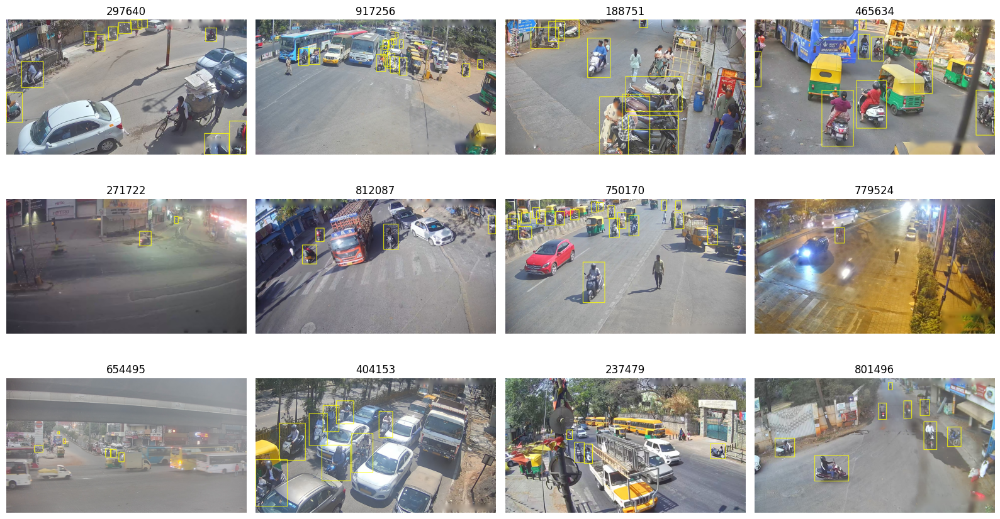

In [14]:
# Pemeriksaan wajib sebelum training: inventaris split, tidak ada citra ganda antar split, overlay label YOLO pada citra acak
import matplotlib.pyplot as plt, random as _r2
S_ = {"train": set(train), "val": set(val), "test": set(test)}
assert not (S_["train"] & S_["val"]) and not (S_["train"] & S_["test"]) and not (S_["val"] & S_["test"]), "ada citra yang sama di dua split!"
def _n_motor(part, stems):
    return sum(len([l for l in (DATA / part / "labels" / f"{s}.txt").read_text().split("\n") if l.strip()]) for s in stems)
inv_split = pd.DataFrame([dict(split="train", n_img=len(train), n_motor=_n_motor("src_train", train)),
                          dict(split="val",   n_img=len(val),   n_motor=_n_motor("src_train", val)),
                          dict(split="test",  n_img=len(test),  n_motor=_n_motor("src_test", test))])
inv_split.to_csv(RES / "FR04_split_inventory.csv", index=False); display(inv_split)
ex_ = _r2.Random(1).sample(train, min(12, len(train)))
fig, axs = plt.subplots(3, 4, figsize=(16, 9))
for a_, s_ in zip(axs.ravel(), ex_):
    im_ = cv2.imread(str(DATA / "src_train/images" / f"{s_}.jpg")); h_, w_ = im_.shape[:2]
    for line in (DATA / "src_train/labels" / f"{s_}.txt").read_text().split("\n"):
        if line.strip():
            _, cx, cy, bw, bh = map(float, line.split())
            cv2.rectangle(im_, (int((cx - bw / 2) * w_), int((cy - bh / 2) * h_)), (int((cx + bw / 2) * w_), int((cy + bh / 2) * h_)), (0, 255, 255), 2)
    a_.imshow(im_[:, :, ::-1]); a_.set_title(s_); a_.axis("off")
plt.tight_layout(); plt.savefig(RES / "FR05_label_check.png", dpi=110); plt.show()
# Periksa gambar: kotak harus menempel pada motor BESERTA pengendaranya (definisi 2-Wheeler UVH-26). Catat jumlah di tabel di atas.

## 3. Generator oklusi sintetis (FR-06 – FR-10)
* `pool_train` dari citra **train**, `pool_test` dari citra **test** → tidak ada sumber yang sama (FR-06).
* Set uji sintetis **berpasangan**: satu motor target per citra, muncul di L0 (bersih), L1 20–40%, L2 40–60%, L3 60–80%,
  dengan potongan penutup yang sama. Target dipilih yang hampir tidak tertutup apa pun (≤10%) agar tutupan hanya berasal dari penutup.
  Motor lain di citra yang sama diperlakukan *ignore* saat evaluasi (adaptasi FR-09, karena citra CCTV hampir tidak pernah berisi satu motor).
* Set **val sintetis** dibangun dengan cara yang sama dari citra val + `pool_train`, khusus untuk memilih varian NMS (FR-17).

In [15]:
pool_tr_rows = L.build_occluder_pool(DATA / "src_train/meta", train, DATA / "occluders/pool_train", seed=DATA_SEED)
pool_te_rows = L.build_occluder_pool(DATA / "src_test/meta",  test,  DATA / "occluders/pool_test",  seed=DATA_SEED)
assert not ({r["source_image"] for r in pool_tr_rows} & {r["source_image"] for r in pool_te_rows})
print("pool_train:", len(pool_tr_rows), "| pool_test:", len(pool_te_rows))
pd.Series(Counter(CATNAME.get(r["cat"], r["cat"]) for r in pool_te_rows)).sort_values(ascending=False)

pool_train: 4801 | pool_test: 2152


three-wheeler      601
hatchback          378
truck              256
lcv                240
sedan              202
suv                156
bus                143
muv                 94
tempo-traveller     35
van                 32
mini-bus             9
others               6
dtype: int64

In [16]:
pool_te = L.OccluderPool(DATA / "occluders/pool_test")
pool_tr = L.OccluderPool(DATA / "occluders/pool_train")
syn_targets = L.build_synthetic_test(DATA / "src_test/meta",  test, pool_te, DATA / "synthetic_test", seed=DATA_SEED, mode="paste")
val_targets = L.build_synthetic_test(DATA / "src_train/meta", val,  pool_tr, DATA / "synthetic_val",  seed=DATA_SEED, mode="paste")
log = pd.read_csv(DATA / "synthetic_test/synthetic_log.csv")
print(log[log.level != "skip"].groupby("level").coverage.describe())

target sintetis: 910, dilewati: 14
target sintetis: 355, dilewati: 5
       count      mean       std     min       25%      50%       75%     max
level                                                                        
L0     910.0  0.000000  0.000000  0.0000  0.000000  0.00000  0.000000  0.0000
L1     910.0  0.282703  0.054367  0.2000  0.238225  0.27680  0.325350  0.3995
L2     910.0  0.484067  0.054274  0.4001  0.437925  0.47810  0.527175  0.5992
L3     910.0  0.677611  0.052726  0.6000  0.631350  0.67085  0.718675  0.8000


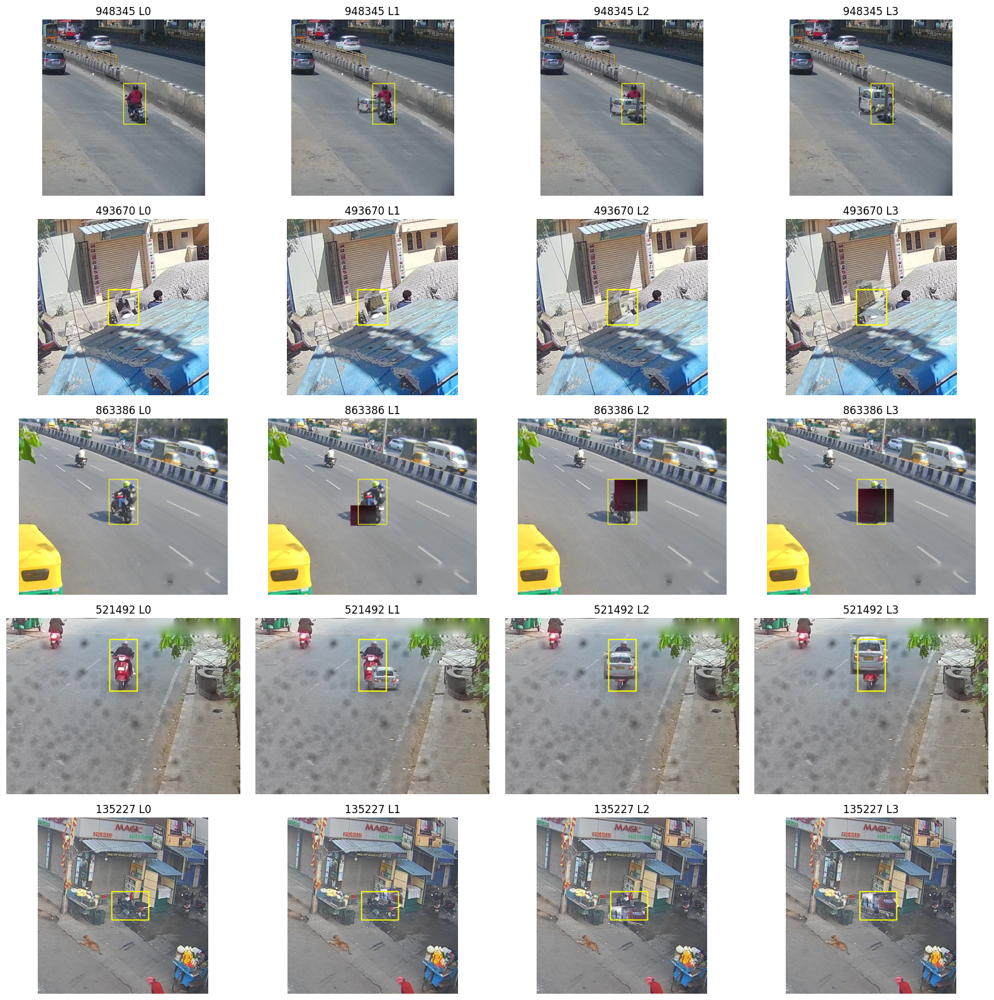

In [17]:
# Pemeriksaan visual 20 contoh (FSD risiko: 'pipeline tempel salah'). Kuning = target.
import matplotlib.pyplot as plt, random as _r
ex = _r.Random(0).sample(sorted(syn_targets), min(5, len(syn_targets)))
fig, ax = plt.subplots(len(ex), 4, figsize=(16, 3.2 * len(ex)))
for i, s in enumerate(ex):
    box = L.load_meta(DATA / "src_test/meta", s)["boxes"][syn_targets[s]]["xyxy"]
    x1, y1, x2, y2 = map(int, box); pad = 2 * max(x2 - x1, y2 - y1)
    for j, lv in enumerate(["L0", "L1", "L2", "L3"]):
        im = cv2.imread(str(DATA / "synthetic_test" / lv / "images" / f"{s}_{lv}.jpg"))
        cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 255), 2)
        crop = im[max(0, y1-pad):y2+pad, max(0, x1-pad):x2+pad][:, :, ::-1]
        ax[i, j].imshow(crop); ax[i, j].set_title(f"{s} {lv}"); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig(RES / "FR10_synthetic_examples.png", dpi=110); plt.show()

## 4. Set oklusi nyata (FR-12 – FR-14): kandidat, label manusia, kappa, Gate 1

| Sel | Isi | Berkas |
|---|---|---|
| 4.1 | Kandidat oklusi nyata (proksi geometri) | `real_candidates.csv` |
| 4.2 | Aturan penandaan (dibekukan) | `aturan_penandaan.json` |
| 4.3 | Penandaan manual mode cepat (sesi interaktif) | `real_tags_raw.csv` |
| 4.4 | Label penanda lain (kukuh) + cek kecocokan | `real_tags_raw_kukuh.csv` |
| 4.5 | Konsensus: **satu label final per target** | `real_tags.csv` |
| 4.6 | Agreement (kappa) dari label **mentah** + Gate 1 | `FR13_kappa.json` |
| 4.7 | **Kunci label final.** Evaluasi nyata BERHENTI bila label final belum ada | `real_labels_final.csv`, `real_labels_manifest.json` |

* `real_tags_raw.csv` = label mentah tiap penanda, **hanya** untuk agreement.
* `real_tags.csv` = satu baris `konsensus` per target, **satu-satunya** sumber label untuk evaluasi.
* Bila label berubah: jalankan ulang 4.5 → 4.7 lalu bagian 6–8. Training **tidak** diulang; prediksi set nyata dibuat ulang otomatis.

In [18]:
# 4.1 Kandidat oklusi nyata.
# Proksi: pada kamera CCTV yang tinggi, objek dengan tepi bawah lebih rendah di citra biasanya lebih dekat ke kamera dan bisa menutupi.
# Proksi = fraksi kotak motor yang tertutup kotak-kotak "di depan". Kandidat: sisi >= 32 px dan proksi >= 0.15.
# Acuan "bersih": proksi <= 0.02 (diambil acak 15%). Keduanya tetap DINILAI MANUSIA di 4.3.
cands = L.export_real_candidates(DATA / "src_test/meta", test, DATA / "real_test", min_proxy=0.15, seed=DATA_SEED)
cdf = pd.DataFrame(cands)
print(cdf.kind.value_counts().to_dict(), "| citra uji:", len(test))
print("kandidat per rentang proksi (TIDAK ditampilkan ke penanda):\n",
      pd.cut(cdf[cdf.kind == "kandidat"].proxy, [0.15, 0.3, 0.5, 0.7, 1.0]).value_counts().sort_index())

{'kandidat': 1623, 'bersih': 496} | citra uji: 1150
kandidat per rentang proksi (TIDAK ditampilkan ke penanda):
 proxy
(0.15, 0.3]    566
(0.3, 0.5]     589
(0.5, 0.7]     277
(0.7, 1.0]     187
Name: count, dtype: int64


In [19]:
# 4.2 Aturan penandaan: ditulis SEBELUM menandai dan dibekukan (berkas tidak ditimpa bila sudah ada).
import datetime
ATURAN_JSON = DATA / "real_test" / "aturan_penandaan.json"
ATURAN = {
    "objek": "Motor/skuter BESERTA pengendaranya di dalam kotak kuning (definisi Two-wheeler UVH-26). Abaikan motor lain.",
    "bersih": "Hampir tidak ada yang menutup motor maupun pengendara (bagian tertutup kira-kira < 10%).",
    "ringan": "Ada yang menutup, tetapi separuh atau lebih dari motor + pengendara masih terlihat.",
    "berat": "Lebih dari separuh motor + pengendara tidak terlihat.",
    "buang": "Kotak salah, bukan motor, terlalu kecil/buram untuk dinilai, atau penanda ragu. Tulis alasan di catatan.",
    "petunjuk": "Gunakan roda, rangka, posisi pengendara, dan konteks. Bagian yang terpotong tepi gambar TIDAK dihitung sebagai tertutup; tulis 'terpotong' di catatan.",
    "penutup": "kendaraan = kendaraan lain (termasuk motor lain); objek_diam = tiang, pohon, pagar, papan; lain = orang, barang, dll.; '-' bila bersih.",
    "kotak_ok": "Hilangkan centang bila kotak kuning TIDAK mencakup seluruh motor + pengendara termasuk bagian yang tertutup (motor itu lalu tidak dievaluasi).",
    "independen": "Jangan melihat atau mendiskusikan label penanda lain sebelum kedua penanda selesai.",
}
if ATURAN_JSON.exists():
    ATURAN = json.load(open(ATURAN_JSON))["aturan"]
    print("aturan dibaca dari", ATURAN_JSON, "(sudah dibekukan)")
else:
    json.dump({"dibuat": datetime.datetime.now().isoformat(timespec="seconds"), "aturan": ATURAN},
              open(ATURAN_JSON, "w"), indent=2, ensure_ascii=False)
    print("aturan dibekukan di", ATURAN_JSON)
for k, v in ATURAN.items():
    print(f"- {k}: {v}")

aturan dibekukan di /kaggle/working/data_v6_e60_ulang/real_test/aturan_penandaan.json
- objek: Motor/skuter BESERTA pengendaranya di dalam kotak kuning (definisi Two-wheeler UVH-26). Abaikan motor lain.
- bersih: Hampir tidak ada yang menutup motor maupun pengendara (bagian tertutup kira-kira < 10%).
- ringan: Ada yang menutup, tetapi separuh atau lebih dari motor + pengendara masih terlihat.
- berat: Lebih dari separuh motor + pengendara tidak terlihat.
- buang: Kotak salah, bukan motor, terlalu kecil/buram untuk dinilai, atau penanda ragu. Tulis alasan di catatan.
- petunjuk: Gunakan roda, rangka, posisi pengendara, dan konteks. Bagian yang terpotong tepi gambar TIDAK dihitung sebagai tertutup; tulis 'terpotong' di catatan.
- penutup: kendaraan = kendaraan lain (termasuk motor lain); objek_diam = tiang, pohon, pagar, papan; lain = orang, barang, dll.; '-' bila bersih.
- kotak_ok: Hilangkan centang bila kotak kuning TIDAK mencakup seluruh motor + pengendara termasuk bagian yang tertut

In [20]:
# 4.3 MODE CEPAT: 12 motor per halaman, cukup pilih level lalu klik "Simpan halaman".
# Dilewati bila PAKAI_LABEL_SAYA = False (label hanya dari CSV kukuh).
if not PAKAI_LABEL_SAYA:
    print('4.3 dilewati: label set nyata hanya dari CSV kukuh')
else:
    import ipywidgets as widgets
    from IPython.display import display

    ANNOTATOR = "ali"        # nama KAMU (jangan "kukuh" / "A")
    JUMLAH    = 80           # cukup 80 motor untuk kappa dengan kukuh
    PER_HAL   = 12           # motor per halaman
    TARGET    = 60

    TAG_DIR   = DATA / "real_test"
    ORDER_CSV = TAG_DIR / "tag_order.csv"
    if not ORDER_CSV.exists():
        cand = pd.read_csv(TAG_DIR / "real_candidates.csv", dtype={"stem": str})
        kd, bs = cand[cand.kind == "kandidat"], cand[cand.kind == "bersih"]
        order = pd.concat([kd.sample(min(300, len(kd)), random_state=DATA_SEED), bs.sample(min(80, len(bs)), random_state=DATA_SEED)])
        order = order.sample(frac=1, random_state=DATA_SEED).reset_index(drop=True)
        order["file"] = [f"{s}_{k}.jpg" for s, k in zip(order.stem, order.target_idx)]
        order[["file", "stem", "target_idx"]].to_csv(ORDER_CSV, index=False)
    order = pd.read_csv(ORDER_CSV, dtype={"stem": str})
    if JUMLAH:
        order = order.iloc[:JUMLAH]
    assert ANNOTATOR != "konsensus"

    COLS = ["file", "target_idx", "annotator", "level", "n_motor", "penutup", "kotak_ok", "catatan"]
    def _load():
        return pd.read_csv(REAL_RAW_CSV, dtype={"file": str, "annotator": str}) if REAL_RAW_CSV.exists() else pd.DataFrame(columns=COLS)
    raw_tags = _load()

    def _thumb(stem, k, size=300):
        meta = L.load_meta(DATA / "src_test/meta", stem)
        im = cv2.imread(str(DATA / "src_test/images" / f"{stem}.jpg"))
        x1, y1, x2, y2 = map(int, meta["boxes"][k]["xyxy"])
        n_motor = sum(b["cat"] == L.MOTOR_CAT for b in meta["boxes"])
        cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 255), 2)
        p = int(0.8 * max(x2 - x1, y2 - y1))
        c = im[max(0, y1 - p):y2 + p, max(0, x1 - p):x2 + p]
        s = size / max(c.shape[:2])
        c = cv2.resize(c, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC if s > 1 else cv2.INTER_AREA)
        return cv2.imencode(".jpg", c, [cv2.IMWRITE_JPEG_QUALITY, 85])[1].tobytes(), n_motor

    def _mine():
        m = raw_tags[raw_tags.annotator == ANNOTATOR]
        return dict(zip(m.file, m.level)), dict(zip(m.file, m.penutup.fillna("")))

    done0, _ = _mine()
    hal = {"i": next((i for i in range(0, len(order), PER_HAL)
                      if any(f not in done0 for f in order.file.iloc[i:i + PER_HAL])), max(0, (len(order) - 1) // PER_HAL * PER_HAL))}
    LEVELS = ["bersih", "ringan", "berat", "buang"]
    kartu = []
    for _ in range(PER_HAL):
        img = widgets.Image(format="jpeg", layout=widgets.Layout(width="300px"))
        lv  = widgets.ToggleButtons(options=LEVELS, value=None, style={"button_width": "70px"})
        pen = widgets.Dropdown(options=["", "kendaraan", "objek_diam", "lain"], value="", description="penutup",
                               layout=widgets.Layout(width="230px"))
        cap = widgets.HTML()
        kartu.append((widgets.VBox([cap, img, lv, pen], layout=widgets.Layout(border="1px solid #ccc", padding="4px")), img, lv, pen, cap))
    judul = widgets.HTML(); info = widgets.HTML()
    b_save = widgets.Button(description="Simpan halaman & lanjut >", button_style="success", layout=widgets.Layout(width="230px"))
    b_prev = widgets.Button(description="< Halaman sebelumnya")
    NM = {}

    def tampil():
        i0 = hal["i"]; rows = order.iloc[i0:i0 + PER_HAL]
        done, pen_done = _mine()
        for j, (box, img, lv, pen, cap) in enumerate(kartu):
            if j < len(rows):
                r = rows.iloc[j]
                img.value, NM[r.file] = _thumb(r.stem, int(r.target_idx))
                lv.value = done.get(r.file); pen.value = pen_done.get(r.file, "") or ""
                cap.value = f"<small>{i0 + j + 1}. {r.file}</small>"
                box.layout.display = None
            else:
                box.layout.display = "none"
        hitung = pd.Series(list(done.values())).value_counts()
        judul.value = (f"<h3>{ANNOTATOR}: halaman {i0 // PER_HAL + 1} / {(len(order) - 1) // PER_HAL + 1} "
                       f"&nbsp; | sudah {len(done)} / {len(order)} motor</h3>"
                       + " &nbsp; ".join(f"<b>{k}</b>: {hitung.get(k, 0)}" + (f"/{TARGET}" if k in ("ringan", "berat") else "")
                                       for k in LEVELS))

    def simpan(_):
        global raw_tags
        i0 = hal["i"]; rows = order.iloc[i0:i0 + PER_HAL]
        baru = []
        for j in range(len(rows)):
            _, img, lv, pen, _ = kartu[j]
            if lv.value is None:
                continue
            r = rows.iloc[j]
            baru.append(dict(file=r.file, target_idx=int(r.target_idx), annotator=ANNOTATOR, level=lv.value, n_motor=NM[r.file],
                             penutup="" if lv.value == "bersih" else pen.value, kotak_ok="ya",
                             catatan="ditandai mode cepat; buang = kotak salah/ragu" if lv.value == "buang" else ""))
        kosong = len(rows) - len(baru)
        if baru:
            files = {b["file"] for b in baru}
            raw_tags = _load()
            raw_tags = raw_tags[~((raw_tags.annotator == ANNOTATOR) & raw_tags.file.isin(files))]
            raw_tags = pd.concat([raw_tags, pd.DataFrame(baru)], ignore_index=True)[COLS]
            raw_tags.to_csv(REAL_RAW_CSV, index=False)
        if kosong:
            info.value = f"<b style='color:red'>{len(baru)} tersimpan, {kosong} motor belum dipilih levelnya. Lengkapi dulu.</b>"
            tampil(); return
        info.value = f"tersimpan {len(baru)} motor."
        if i0 + PER_HAL < len(order):
            hal["i"] = i0 + PER_HAL
        else:
            info.value += " <b>SEMUA SELESAI.</b>"
        tampil()

    def mundur(_):
        hal["i"] = max(0, hal["i"] - PER_HAL); info.value = ""; tampil()

    b_save.on_click(simpan); b_prev.on_click(mundur)
    aturan = widgets.HTML("<small><b>bersih</b> &lt;10% tertutup · <b>ringan</b> separuh atau lebih masih terlihat · "
                          "<b>berat</b> lebih dari separuh tidak terlihat · <b>buang</b> kotak salah / bukan motor / ragu. "
                          "Penutup diisi untuk ringan dan berat.</small>")
    tampil()
    grid = widgets.GridBox([k[0] for k in kartu], layout=widgets.Layout(grid_template_columns="repeat(4, 320px)", grid_gap="6px"))
    display(widgets.VBox([judul, aturan, grid, widgets.HBox([b_prev, b_save]), info]))

4.3 dilewati: label set nyata hanya dari CSV kukuh


In [21]:
# 4.4 MASUKKAN CSV LABEL TEMAN + cek kecocokan dengan data uji notebook ini
import glob
FOLDER_TEMAN = str(LABEL_KUKUH_DIR)   # diatur di sel konfigurasi (Colab: Drive/occlusion_v6/label_kukuh)
NAMA_TEMAN   = "kukuh"      # nama penanda di CSV teman (di file aslinya tertulis "A")

_csvs = sorted(glob.glob(f"{FOLDER_TEMAN}/**/*.csv", recursive=True))
assert _csvs, f"tidak ada file .csv di {FOLDER_TEMAN} -> cek path di panel Input (kanan)"
_csvs = [p for p in _csvs if "penanda2" not in Path(p).name.lower()]   # label penanda ke-2 TIDAK boleh masuk label kukuh (dipakai di 12e)
print("CSV ditemukan:", _csvs)
t = pd.concat([pd.read_csv(p, dtype={"file": str, "annotator": str}) for p in _csvs], ignore_index=True)
_n0 = len(t)
t = t[~t["annotator"].astype(str).str.lower().str.contains("ulang|penanda2", regex=True)]   # baris penilaian ulang (A_ulang) hanya untuk agreement
print(f"baris penilaian-ulang/penanda2 dibuang dari label kukuh: {_n0 - len(t)} | annotator di berkas: {sorted(set(map(str, pd.concat([pd.read_csv(p, dtype=str, usecols=['annotator']) for p in _csvs]).annotator)))}")
t["annotator"] = NAMA_TEMAN
t["level"] = t["level"].astype(str).str.strip().str.lower()
t = t.drop_duplicates("file", keep="last")

c = pd.read_csv(DATA / "real_test" / "real_candidates.csv", dtype={"stem": str})
c_files = set(f"{s}_{k}.jpg" for s, k in zip(c.stem, c.target_idx))
cocok = t.file.isin(c_files)
print(f"label teman: {len(t)} motor | cocok dengan kandidat di notebook ini: {cocok.sum()} ({cocok.mean():.1%})")
print("level:", t.level.value_counts().to_dict())
if cocok.mean() < 0.95:
    print("PERINGATAN: banyak file TIDAK cocok -> data uji teman berbeda (samakan DATA_SEED / N_TEST_SRC / REVISION). Contoh:",
          t.file[~cocok].head(5).tolist())
t = t[cocok]
CSV_TEMAN = DATA / "real_test" / f"real_tags_raw_{NAMA_TEMAN}.csv"     # salinan (folder input Kaggle hanya-baca)
t.to_csv(CSV_TEMAN, index=False)
print("disalin ke", CSV_TEMAN)

# kemajuan semua penanda + motor yang dinilai >= 2 penanda (dasar kappa)
_all = pd.concat([pd.read_csv(p, dtype={"file": str, "annotator": str}) for p in ([REAL_RAW_CSV] if PAKAI_LABEL_SAYA else []) + [CSV_TEMAN] if Path(p).exists()],
                 ignore_index=True).drop_duplicates(["file", "annotator"], keep="last")
display(_all.groupby("annotator")["level"].value_counts().unstack(fill_value=0))
_pf = _all.groupby("file").annotator.nunique()
print(f"motor yang dinilai >= 2 penanda: {(_pf >= 2).sum()} (butuh >= 50 untuk kappa)")

CSV ditemukan: ['/kaggle/input/datasets/alirahmanbayanaka/manual-penanda2/real_tags (1).csv']
baris penilaian-ulang/penanda2 dibuang dari label kukuh: 0 | annotator di berkas: ['A']
label teman: 1623 motor | cocok dengan kandidat di notebook ini: 1623 (100.0%)
level: {'ringan': 595, 'bersih': 588, 'berat': 333, 'buang': 107}
disalin ke /kaggle/working/data_v6_e60_ulang/real_test/real_tags_raw_kukuh.csv


level,berat,bersih,buang,ringan
annotator,,,,
kukuh,333,588,107,595


motor yang dinilai >= 2 penanda: 0 (butuh >= 50 untuk kappa)


In [22]:
# 4.5 Konsensus -> real_tags.csv. Label sama diambil langsung; label beda ditampilkan untuk didiskusikan, lalu diisi di RESOLVE.
import pickle, matplotlib.pyplot as plt

EXTRA_RAW_CSVS = [CSV_TEMAN]   # label teman dari sel 4.4
RESOLVE = {}          # hasil diskusi untuk label yang beda, mis. {"356278_4.jpg": "berat"}
HAPUS_PENANDA = ["penanda1"]   # label uji coba lama yang TIDAK dipakai (kosongkan [] bila ingin dipakai)

# label lama di real_tags_raw.csv (mis. terbawa dari PREV_OUTPUT) hanya dipakai bila PAKAI_LABEL_SAYA = True
srcs = [p for p in ([REAL_RAW_CSV] if PAKAI_LABEL_SAYA else []) + list(EXTRA_RAW_CSVS) if Path(p).exists()]
if not srcs:
    print("Belum ada label. Jalankan 4.3 dulu (sesi interaktif).")
else:
    raw = (pd.concat([pd.read_csv(p, dtype={"file": str, "annotator": str}) for p in srcs], ignore_index=True)
             .drop_duplicates(["file", "annotator"], keep="last"))
    raw = raw[(raw.annotator.str.lower() != "konsensus") & (~raw.annotator.isin(HAPUS_PENANDA))]
    if not PAKAI_LABEL_SAYA:
        raw = raw[raw.annotator == NAMA_TEMAN]                       # pengaman: hanya label kukuh
    print("penanda yang dipakai:", sorted(raw.annotator.unique()))
    raw.to_csv(REAL_RAW_CSV, index=False)                          # satu berkas mentah gabungan (dasar kappa)
    print("label per penanda:\n", raw.groupby("annotator")["level"].value_counts().unstack(fill_value=0))

    rows, beda = [], []
    for f, g in raw.groupby("file"):
        lv = g["level"].astype(str).str.lower()
        if f in RESOLVE:
            level, cara = RESOLVE[f], "diskusi"
        elif lv.nunique() == 1:
            level, cara = lv.iloc[0], ("sepakat" if len(g) > 1 else "satu_penanda")
        else:
            level, cara = None, None; beda.append((f, dict(zip(g.annotator, lv))))
        if level is not None and (g["kotak_ok"].astype(str) == "tidak").any():
            level = "buang"                                          # kotak GT tidak mencakup seluruh motor -> tidak dievaluasi
        if level is not None:
            g0 = g.iloc[0]
            pen = g["penutup"].dropna().astype(str)
            rows.append(dict(file=f, target_idx=int(g0.target_idx), annotator="konsensus", level=level, n_motor=g0.n_motor,
                             penutup=pen.mode().iloc[0] if len(pen) else "", kotak_ok="ya" if level != "buang" else "tidak",
                             catatan="; ".join(str(c) for c in g["catatan"].dropna() if str(c).strip()), cara=cara))
    cons = pd.DataFrame(rows)
    cons.to_csv(REAL_TAGS_CSV, index=False)
    print("\nkonsensus:", cons["level"].value_counts().to_dict(), "| cara:", cons["cara"].value_counts().to_dict(), "->", REAL_TAGS_CSV)

    if beda:
        print(f"\n{len(beda)} motor BEDA label (belum masuk konsensus). Diskusikan, isi RESOLVE, lalu jalankan sel ini lagi:")
        for f, d in beda:
            print("  ", f, d)
        def _crop45(f):
            s_, k_ = f.rsplit(".", 1)[0].rsplit("_", 1)
            meta = L.load_meta(DATA / "src_test/meta", s_); im = cv2.imread(str(DATA / "src_test/images" / f"{s_}.jpg"))
            x1, y1, x2, y2 = map(int, meta["boxes"][int(k_)]["xyxy"]); p = max(x2 - x1, y2 - y1)
            cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 255), 2)
            return im[max(0, y1 - p):y2 + p, max(0, x1 - p):x2 + p, ::-1]
        show = beda[:12]
        fig, axs = plt.subplots((len(show) + 3) // 4, 4, figsize=(16, 4 * ((len(show) + 3) // 4)), squeeze=False)
        for a_, (f, d) in zip(axs.ravel(), show):
            a_.imshow(_crop45(f))
            a_.set_title(f"{f}\n" + ", ".join(f"{k}={v}" for k, v in d.items()), fontsize=9)
        for a_ in axs.ravel(): a_.axis("off")
        plt.tight_layout(); plt.show()
    else:
        print("semua label sudah sepakat / sudah diputuskan.")

    # cache prediksi set nyata lama dihapus (isi set berubah) agar bagian 6 memprediksi citra yang benar
    for fp in (W / "raw_preds").glob("*.pkl"):
        d = pickle.load(open(fp, "rb")); lama = [k for k in d if k.startswith("nyata_")]
        for k in lama: d.pop(k)
        pickle.dump(d, open(fp, "wb"))
    print("cache prediksi set nyata dibersihkan.")

penanda yang dipakai: ['kukuh']
label per penanda:
 level      berat  bersih  buang  ringan
annotator                              
kukuh        333     588    107     595

konsensus: {'ringan': 589, 'bersih': 587, 'berat': 300, 'buang': 147} | cara: {'satu_penanda': 1623} -> /kaggle/working/data_v6_e60_ulang/real_test/real_tags.csv
semua label sudah sepakat / sudah diputuskan.
cache prediksi set nyata dibersihkan.


In [23]:
# 4.6 Muat label set nyata + Cohen's kappa (FR-13) + Gate 1 (FR-14)
real_levels, real_src = L.load_real_levels(REAL_TAGS_CSV, DATA / "real_test/real_candidates.csv")
# Bila ada konsensus manual: pakai HANYA label manusia (tidak dicampur / ditimpa proksi)
if REAL_TAGS_CSV.exists():
    _m = pd.read_csv(REAL_TAGS_CSV, dtype={"file": str, "annotator": str})
    _m = _m[_m.annotator.astype(str).str.lower() == "konsensus"]
    if len(_m):
        real_levels = {(f.rsplit(".", 1)[0].rsplit("_", 1)[0], int(k)): str(lv).lower()
                       for f, k, lv in zip(_m["file"], _m["target_idx"], _m["level"])}
        real_src = "manual"
print("sumber label set nyata:", real_src.upper())
if real_src == "proxy" and not SMOKE:
    print("PERINGATAN: label set nyata = PROXY. Hanya untuk uji pipeline; JANGAN dipakai untuk hasil paper. Selesaikan 4.3-4.5.")

# kappa dari label MENTAH (sebelum diskusi), hanya motor yang dinilai >= 2 penanda
def _interpretasi(k):
    return ("sangat rendah" if k < 0.2 else "rendah" if k < 0.4 else "sedang" if k < 0.6
            else "substansial" if k < 0.8 else "hampir sempurna")
kappa_info = {}
if REAL_RAW_CSV.exists():
    t = pd.read_csv(REAL_RAW_CSV, dtype={"file": str, "annotator": str})
    t = t[t.annotator.astype(str).str.lower() != "konsensus"]
    t["level"] = t["level"].astype(str).str.lower()
    t = t[~t.annotator.isin(HAPUS_PENANDA)]
    piv_all = t.pivot_table(index="file", columns="annotator", values="level", aggfunc="first")
    # pasangan penanda dengan motor bersama terbanyak
    pairs = [(piv_all[[x, y]].dropna().shape[0], x, y) for i, x in enumerate(piv_all.columns) for y in piv_all.columns[i + 1:]]
    piv = piv_all.iloc[:, :1]
    if pairs and max(pairs)[0] > 0:
        _, a, b = max(pairs)
        piv = piv_all[[a, b]].dropna()
    if piv.shape[1] >= 2:
        la, lb = list(piv[a]), list(piv[b])
        k_all = L.cohen_kappa(la, lb)
        keep = [(x, y) for x, y in zip(la, lb) if x != "buang" and y != "buang"]          # analisis tanpa label ragu/buang
        k_nb = L.cohen_kappa([x for x, _ in keep], [y for _, y in keep]) if keep else float("nan")
        kappa_info = dict(pasangan=f"{a} vs {b}", n_motor=len(piv), n_citra=len({f.rsplit("_", 1)[0] for f in piv.index}),
                          kesepakatan=sum(x == y for x, y in zip(la, lb)) / len(piv), kappa=k_all,
                          interpretasi=_interpretasi(k_all), n_tanpa_buang=len(keep), kappa_tanpa_buang=k_nb)
        print(f"Cohen kappa ({kappa_info['pasangan']}, {kappa_info['n_motor']} motor, {kappa_info['n_citra']} citra): "
              f"{k_all:.3f} ({kappa_info['interpretasi']}) | kesepakatan {kappa_info['kesepakatan']:.1%} | "
              f"tanpa 'buang': {k_nb:.3f} (n={len(keep)})")
        display(pd.crosstab(piv[a], piv[b], margins=True))
        json.dump(kappa_info, open(RES / "FR13_kappa.json", "w"), indent=2)
    else:
        print("kappa belum bisa dihitung: butuh >= 2 penanda pada motor yang sama")
else:
    print("kappa belum bisa dihitung: belum ada label manual")

# Gate 1
real_levels = {k: v for k, v in real_levels.items() if v in ("ringan", "berat", "bersih")}
cnt = Counter(real_levels.values()); print("motor per tingkat:", dict(cnt))
GATE_OK = cnt["ringan"] >= GATE_MIN and cnt["berat"] >= GATE_MIN
print(f"GATE 1 (>= {GATE_MIN} motor ringan DAN berat, label {real_src}):",
      "LANJUT" if GATE_OK else "KURANG -> tandai lebih banyak / catat sebagai keterbatasan")
rows = []
for lv in ("bersih", "ringan", "berat"):
    ks = [k for k, v in real_levels.items() if v == lv]
    rows.append(dict(level=lv, n_motor=len(ks), n_citra=len({s for s, _ in ks}), sumber=real_src))
fr14 = pd.DataFrame(rows); display(fr14); fr14.to_csv(RES / "FR14_real_counts.csv", index=False)
if REAL_TAGS_CSV.exists() and real_src == "manual":
    _c = pd.read_csv(REAL_TAGS_CSV, dtype={"file": str})
    pt = _c[_c.level.isin(["ringan", "berat"])].pivot_table(index="level", columns="penutup", values="file", aggfunc="count", fill_value=0)
    print("jenis penutup per tingkat (untuk paper):"); display(pt); pt.to_csv(RES / "FR14_penutup.csv")

sumber label set nyata: MANUAL
kappa belum bisa dihitung: butuh >= 2 penanda pada motor yang sama
motor per tingkat: {'bersih': 587, 'ringan': 589, 'berat': 300}
GATE 1 (>= 50 motor ringan DAN berat, label manual): LANJUT


,level,n_motor,n_citra,sumber
0,bersih,587,365,manual
1,ringan,589,362,manual
2,berat,300,191,manual


jenis penutup per tingkat (untuk paper):


penutup,kendaraan,lain,objek_diam
level,,,
berat,269,18,13
ringan,535,20,34


In [24]:
import shutil, os
if DI_COLAB:
    B = '/content/drive/MyDrive/occlusion_v6'
    shutil.copy(f'{B}/label_kukuh/real_tags_raw.csv', f'{B}/label_ulang/real_tags_raw.csv')
    print(os.listdir(f'{B}/label_ulang'))
print(LABEL_ULANG_CSV, LABEL_ULANG_CSV.exists())

/kaggle/input/datasets/alirahmanbayanaka/manual-penanda2/real_tags_raw.csv False


In [25]:
# 4.6b AGREEMENT INTRA-PENANDA (opsional): penanda yang sama menilai ulang sebagian motor (A vs A_ulang).
# Kosongkan RAW_ULANG = None bila file tidak ada. Label ulang ini HANYA untuk agreement, tidak ikut label final.
import glob
RAW_ULANG = str(LABEL_ULANG_CSV)      # diatur di sel konfigurasi
if RAW_ULANG and Path(RAW_ULANG).exists():
    _u = pd.read_csv(RAW_ULANG, dtype={"file": str, "annotator": str})
    _u["level"] = _u["level"].astype(str).str.strip().str.lower()
    _pv = _u.pivot_table(index="file", columns="annotator", values="level", aggfunc="first").dropna()
    _cols = list(_pv.columns)
    _b = next((c for c in _cols if "ulang" in c.lower()), None)
    _a = "A" if "A" in _cols else next((c for c in _cols if c != _b), None)   # A = kukuh, A_ulang = kukuh menilai ulang
    if _a and _b:
        la, lb = list(_pv[_a]), list(_pv[_b])
        k_all = L.cohen_kappa(la, lb)
        keep = [(x, y) for x, y in zip(la, lb) if x != "buang" and y != "buang"]
        kappa_info = dict(pasangan=f"{_a} vs {_b}", n_motor=len(_pv), n_citra=len({f.rsplit("_", 1)[0] for f in _pv.index}),
                          kesepakatan=sum(x == y for x, y in zip(la, lb)) / len(_pv), kappa=k_all, interpretasi=_interpretasi(k_all),
                          n_tanpa_buang=len(keep), kappa_tanpa_buang=L.cohen_kappa([x for x, _ in keep], [y for _, y in keep]) if keep else float("nan"),
                          sumber_file=str(RAW_ULANG))
        json.dump(kappa_info, open(RES / "FR13_kappa.json", "w"), indent=2)
        print(f"agreement {kappa_info['pasangan']} ({kappa_info['n_motor']} motor): kappa {k_all:.3f} ({kappa_info['interpretasi']}) | "
              f"kesepakatan {kappa_info['kesepakatan']:.1%} -> jenis dicatat di sel 4.7")
        display(pd.crosstab(_pv[_a], _pv[_b], margins=True))
    else:
        print("file ulang tidak berisi pasangan A / A_ulang:", _cols)
else:
    print("tidak ada file label ulang -> agreement tidak dihitung")

tidak ada file label ulang -> agreement tidak dihitung


In [26]:
# 4.7 KUNCI LABEL FINAL (wajib sebelum evaluasi). Sumber satu-satunya: real_tags.csv (baris 'konsensus').
import hashlib
JENIS_AGREEMENT = "otomatis"   # "antar" = dua penanda independen | "intra" = orang yang sama menilai ulang | "otomatis" = tebak dari nama

_final = pd.read_csv(REAL_TAGS_CSV, dtype={"file": str, "annotator": str}) if REAL_TAGS_CSV.exists() else pd.DataFrame(columns=["file", "annotator", "level"])
_final = _final[_final.annotator.astype(str).str.lower() == "konsensus"].copy()
assert not _final.file.duplicated().any(), "real_tags.csv memuat lebih dari satu label final untuk target yang sama"
_final["level"] = _final["level"].astype(str).str.lower()
_n_buang = int((_final.level == "buang").sum())
_final = _final[_final.level.isin(["bersih", "ringan", "berat"])]
if len(_final) == 0:
    if SMOKE:
        print("UJI ASAP: label final belum ada, evaluasi memakai PROXY (hanya untuk uji pipeline)")
    else:
        raise RuntimeError("BERHENTI: label final (real_tags.csv, baris 'konsensus') belum ada. Selesaikan 4.3-4.5. "
                           "Evaluasi set nyata tidak dijalankan dengan label PROXY.")
else:
    _final["stem"] = [f.rsplit(".", 1)[0].rsplit("_", 1)[0] for f in _final.file]
    _final["target_idx"] = [int(f.rsplit(".", 1)[0].rsplit("_", 1)[1]) for f in _final.file]
    _raw = pd.read_csv(REAL_RAW_CSV, dtype={"file": str, "annotator": str}) if REAL_RAW_CSV.exists() else pd.DataFrame(columns=["file", "annotator", "level"])
    _raw = _raw[_raw.annotator.astype(str).str.lower() != "konsensus"]
    _pen = _raw.groupby("file").annotator.apply(lambda s: "+".join(sorted(set(map(str, s)))))
    _final["penanda"] = _final.file.map(_pen).fillna("")
    _final["sumber_label"] = _final["cara"] if "cara" in _final.columns else "konsensus"   # sepakat / satu_penanda / diskusi
    real_levels = {(s, int(k)): lv for s, k, lv in zip(_final.stem, _final.target_idx, _final.level)}
    real_src = "manual"
    cols = [c for c in ["file", "stem", "target_idx", "level", "sumber_label", "penanda", "penutup", "catatan"] if c in _final.columns]
    _final[cols].sort_values("file").to_csv(RES / "real_labels_final.csv", index=False)
    cnt = Counter(real_levels.values())
    GATE_OK = cnt["ringan"] >= GATE_MIN and cnt["berat"] >= GATE_MIN
    manifest = dict(sumber="manual (real_tags.csv, baris konsensus)", sha256_real_tags=hashlib.sha256(open(REAL_TAGS_CSV, "rb").read()).hexdigest(),
                    n_target=len(_final), per_tingkat=dict(cnt), n_buang_dikeluarkan=_n_buang,
                    sumber_label=_final.sumber_label.value_counts().to_dict(), penanda=_final.penanda.value_counts().to_dict(),
                    gate1_ok=bool(GATE_OK))
    json.dump(manifest, open(RES / "real_labels_manifest.json", "w"), indent=2)
    print("LABEL FINAL DIKUNCI:", manifest["n_target"], "target |", dict(cnt), "| buang dikeluarkan:", _n_buang)
    print("asal label:", manifest["sumber_label"])

# jenis agreement (poin 6): antar-penanda vs anotasi ulang oleh orang yang sama
_kp = RES / "FR13_kappa.json"
if _kp.exists():
    ki = json.load(open(_kp)); a_, b_ = ki["pasangan"].split(" vs ")
    if JENIS_AGREEMENT == "otomatis":
        sama = a_.lower().startswith(b_.lower()) or b_.lower().startswith(a_.lower()) or "ulang" in (a_ + b_).lower()
        jenis = "intra" if sama else "antar"
    else:
        jenis = JENIS_AGREEMENT
    ki["jenis"] = {"intra": "intra-penanda (orang yang sama menilai ulang)", "antar": "antar-penanda (dua penanda independen)"}[jenis]
    json.dump(ki, open(_kp, "w"), indent=2); kappa_info = ki
    print(f"agreement {ki['pasangan']}: kappa {ki['kappa']:.3f} -> dilaporkan sebagai {ki['jenis']}")
    if JENIS_AGREEMENT == "otomatis":
        print("  KONFIRMASI ke tim: benar begitu? Bila tidak, isi JENIS_AGREEMENT = 'antar' / 'intra' lalu jalankan ulang sel ini.")
LABEL_FINAL_OK = True

LABEL FINAL DIKUNCI: 1476 target | {'bersih': 587, 'ringan': 589, 'berat': 300} | buang dikeluarkan: 147
asal label: {'satu_penanda': 1476}


## 5. Training (FR-15 – FR-18)
* Hyperparameter identik untuk semua konfigurasi; satu-satunya beda adalah augmentasi oklusi.
* **FR-18 (hasil verifikasi):** di Ultralytics, argumen `erasing` hanya berlaku untuk klasifikasi dan `copy_paste` hanya untuk segmentasi/OBB.
  Karena itu C1 dan C2 memakai transform sendiri (`L.OcclusionAug`) yang disisipkan sebelum `Format`, setelah mosaic/perspective/flip,
  dan tetap aktif setelah `close_mosaic`.
* Optimizer ditetapkan `SGD` agar `lr0` benar-benar dipakai (`optimizer='auto'` mengabaikan `lr0`).
* Gunakan satu GPU (`device=0`). Mode multi-GPU Ultralytics menjalankan subprocess yang tidak membawa trainer kustom.

In [27]:
# ===== PENGAMAN EPOCH (sebelum training) =====
# Mencegah run lama dengan jumlah epoch berbeda ikut dianggap "selesai" (sel training hanya melihat berkas SELESAI/best.pt).
import yaml
_salah = []
for _d in sorted(RUNS.glob("*_s*")):
    _a = _d / "args.yaml"
    if _a.exists():
        _e = yaml.safe_load(open(_a)).get("epochs")
        if _e != EPOCHS:
            _salah.append((_d.name, _e))
if _salah:
    raise RuntimeError(f"Run lama dengan epoch berbeda dari EPOCHS={EPOCHS}: {_salah}. Hapus folder {RUNS} atau ganti EXP_TAG.")
print("folder run bersih / epoch cocok:", EPOCHS)


folder run bersih / epoch cocok: 60


In [28]:
# Matikan integrasi logging bawaan Ultralytics (Ray Tune, W&B, MLflow, dll.).
# Di image Kaggle, paket 'ray' bisa error "circular import" saat training dimulai.
from ultralytics import settings as _ul_settings
_ul_settings.update({k: False for k in ("raytune", "wandb", "mlflow", "comet", "clearml", "neptune", "dvc", "tensorboard")
                     if k in _ul_settings})

import time, torch
from ultralytics import YOLO
HYP = dict(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer="SGD", lr0=0.01, momentum=0.937,
           weight_decay=5e-4, patience=PATIENCE, close_mosaic=CLOSE_MOSAIC, cache=CACHE, workers=4, device=0,
           deterministic=True, plots=True, exist_ok=True, project=str(RUNS), verbose=False)
json.dump(HYP, open(RES / "FR15_hyperparameters.json", "w"), indent=2)

# ---- training yang bisa DILANJUTKAN antar sesi + berhenti rapi sebelum batas waktu Kaggle ----
class BatasWaktu(Exception):
    pass

def status_run(d):
    """'selesai' | 'lanjut' (terpotong, bisa di-resume) | 'baru'."""
    d = Path(d); last, best = d / "weights" / "last.pt", d / "weights" / "best.pt"
    if (d / "SELESAI").exists():
        return "selesai"
    if last.exists():
        try:
            ck = torch.load(last, map_location="cpu", weights_only=False)
        except Exception:
            return "baru"
        if ck.get("optimizer") is None:              # Ultralytics membuang optimizer saat training tuntas
            (d / "SELESAI").write_text("ok"); return "selesai"
        return "lanjut"
    if best.exists():                                 # bobot lama tanpa last.pt
        (d / "SELESAI").write_text("ok"); return "selesai"
    return "baru"

DURASI_MENIT = []
def sisa_jam():
    return BATAS_JAM_SESI - (time.time() - T_SESI) / 3600

def latih(name, kw, seed, hyp, project):
    """Latih satu run. Return status akhirnya ('selesai' / 'lanjut' bila dipotong karena waktu)."""
    d = Path(project) / name
    st = status_run(d)
    if st == "selesai":
        print("lewati (sudah selesai):", name); return st
    est = max(DURASI_MENIT) / 60 if DURASI_MENIT else 0
    if sisa_jam() <= 0.25 or (st == "baru" and est > sisa_jam()):
        print(f"WAKTU SESI HAMPIR HABIS -> {name} ditunda ke sesi berikutnya"); return st
    kw2 = dict(kw)
    if kw2.get("mode") == "paste":
        kw2["pool_dir"] = str(DATA / "occluders/pool_train")
    trainer = L.make_trainer(seed=seed, **kw2)
    def _cek_waktu(tr):                               # dipanggil SETELAH last.pt tersimpan tiap epoch
        if sisa_jam() <= 0.25:
            raise BatasWaktu(f"{name} berhenti di epoch {tr.epoch + 1} (sisa waktu sesi tipis)")
    t0 = time.time()
    try:
        if st == "lanjut":
            print("LANJUTKAN (resume):", name)
            m = YOLO(str(d / "weights" / "last.pt")); m.add_callback("on_fit_epoch_end", _cek_waktu)
            m.train(trainer=trainer, resume=True)
        else:
            m = YOLO(MODEL); m.add_callback("on_fit_epoch_end", _cek_waktu)
            m.train(trainer=trainer, seed=seed, name=name, **dict(hyp, project=str(project)))
    except BatasWaktu as e:
        print("DIJEDA:", e)
    menit = round((time.time() - t0) / 60, 1)
    st = status_run(d)
    if st == "selesai":
        DURASI_MENIT.append(menit)
    timing.append(dict(run=name, minutes=menit, status=st))
    print(timing[-1]); pd.DataFrame(timing).to_csv(RES / f"timing_{int(T_SESI)}.csv", index=False)
    return st

timing = []
status_semua = {f"{cfg}_s{seed}": latih(f"{cfg}_s{seed}", kw, seed, HYP, RUNS) for cfg, kw in CONFIGS.items() for seed in SEEDS}
belum = [k for k, v in status_semua.items() if v != "selesai"]
if belum:
    msg = (f"TRAINING BELUM SELESAI ({len(belum)} run: {belum}). Ini BUKAN kerusakan: hasil yang sudah ada tersimpan di Output.\n"
           f"Lanjutkan: Add Input -> output versi notebook ini, isi PREV_OUTPUT dengan path-nya, lalu Save & Run All lagi.")
    print(msg)
    if BERHENTI_JIKA_BELUM:
        raise SystemExit(msg)
print("semua run selesai:", list(status_semua))


[... output panjang dipangkas; lihat log lengkap di reports/ ...]
 2703      0.868      0.825      0.902      0.687

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      50/60       4.4G     0.8497       0.55     0.8865         42        640: 100% ━━━━━━━━━━━━ 160/160 5.4it/s 29.7s0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.9it/s 2.2s0.2s
                   all        450       2703      0.848      0.847       0.91      0.695
Closing dataloader mosaic
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      51/60       4.4G     0.8304     0.5359     0.8876         53        640: 100% ━━━━━━━━━━━━ 160/160 5.3it/s 30.2s0.4ss
                 C

In [44]:
# ===== KEMAS RUN UNTUK DIBAWA KE KAGGLE (jalankan setelah training selesai) =====
# Di Colab: berhenti setelah sel ini (menu Runtime > Run before). Evaluasi bisa dikerjakan di Kaggle dengan PREV_OUTPUT.
import pandas as pd
_rows = []
for _cfg in CONFIGS:
    for _s in SEEDS:
        _d = RUNS / f"{_cfg}_s{_s}"
        _n = len(pd.read_csv(_d / "results.csv")) if (_d / "results.csv").exists() else 0
        _rows.append(dict(run=_d.name, epoch_dilatih=_n, best_pt=(_d / "weights" / "best.pt").exists(), status=status_run(_d)))
_chk = pd.DataFrame(_rows); display(_chk)
if (_chk.status == "selesai").all() and _chk.best_pt.all() and (_chk.epoch_dilatih <= EPOCHS).all():
    if DI_COLAB:
        shutil.make_archive(str(W / "runs_untuk_kaggle"), "zip", root_dir=str(W), base_dir=RUNS.name)
        _z = W / "runs_untuk_kaggle.zip"
        print(f"ZIP siap: {_z} ({_z.stat().st_size / 1e6:.0f} MB). Isinya folder {RUNS.name}/. Unggah sebagai Kaggle Dataset.")
    else:
        print("bukan Colab: zip dilewati")
else:
    print("BELUM LENGKAP: jalankan ulang sel training (ia akan melanjutkan dari last.pt) sampai semua 9 run 'selesai'.")


,run,epoch_dilatih,best_pt,status
0,C0_s0,60,True,selesai
1,C0_s1,60,True,selesai
2,C0_s2,60,True,selesai
3,C2_s0,60,True,selesai
4,C2_s1,60,True,selesai
5,C2_s2,60,True,selesai
6,C1_s0,60,True,selesai
7,C1_s1,60,True,selesai
8,C1_s2,60,True,selesai


bukan Colab: zip dilewati


/kaggle/working/runs_v6_e60_ulang/C2_s0/train_batch0.jpg


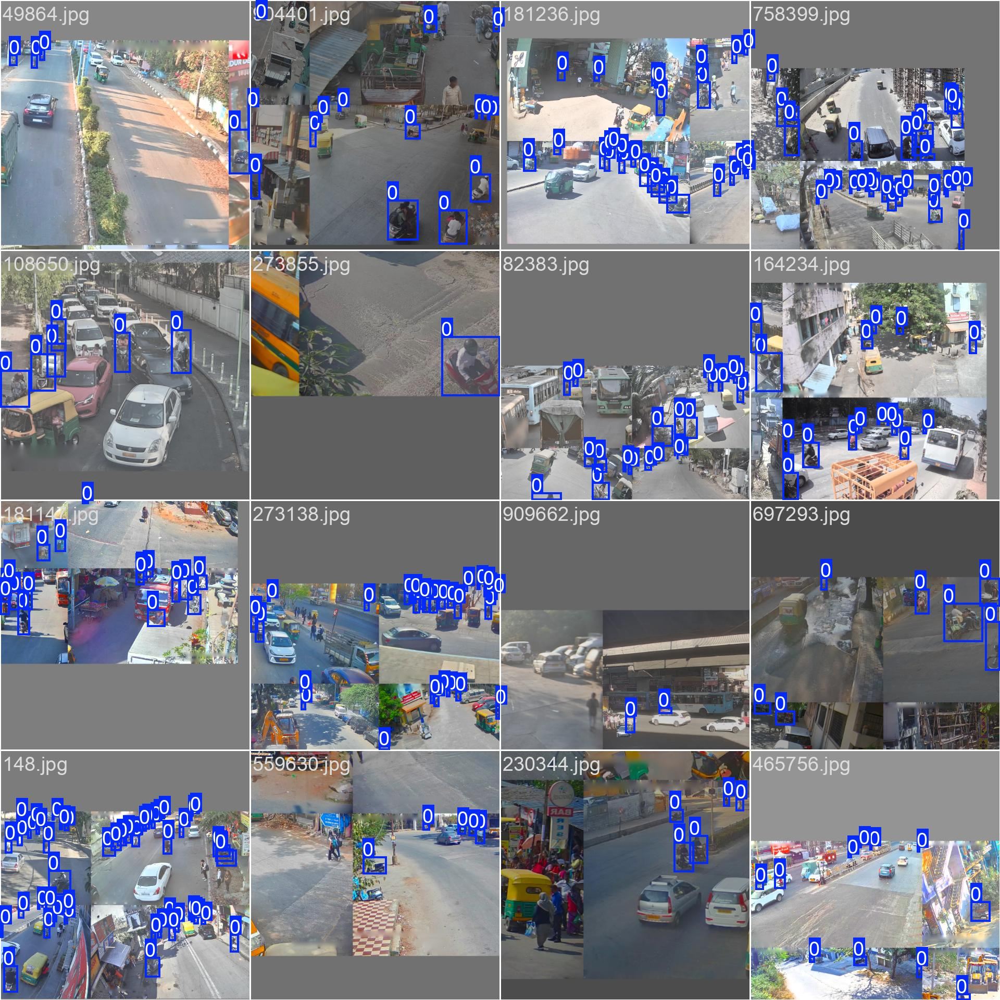

/kaggle/working/runs_v6_e60_ulang/C2_s0/train_batch8002.jpg


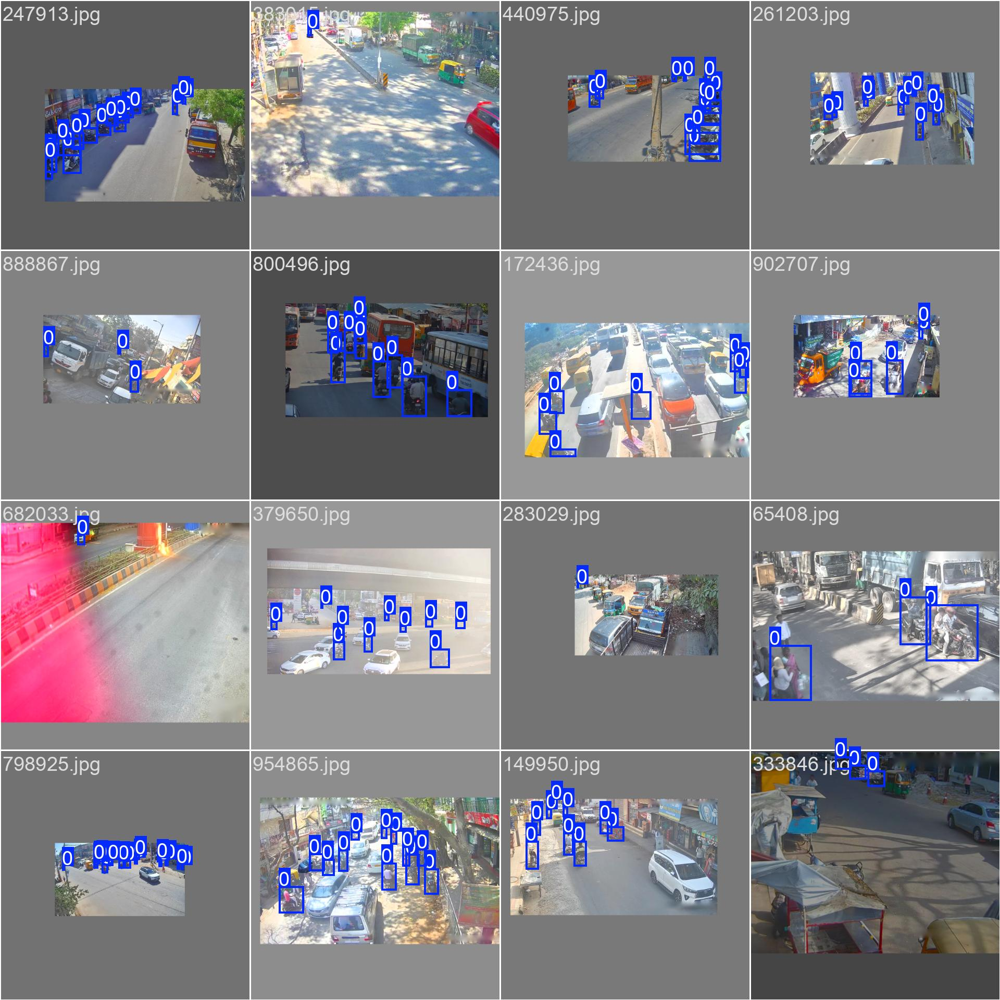

/kaggle/working/runs_v6_e60_ulang/C1_s0/train_batch0.jpg


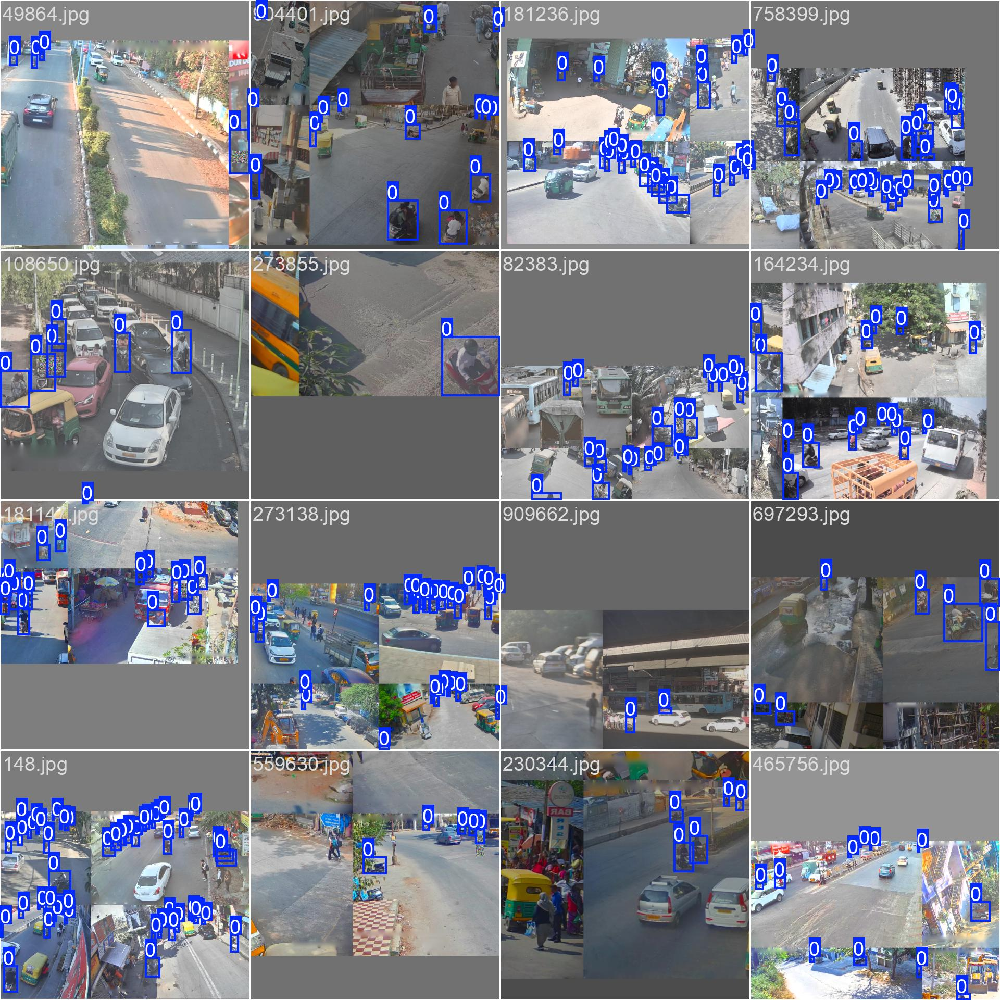

/kaggle/working/runs_v6_e60_ulang/C1_s0/train_batch8002.jpg


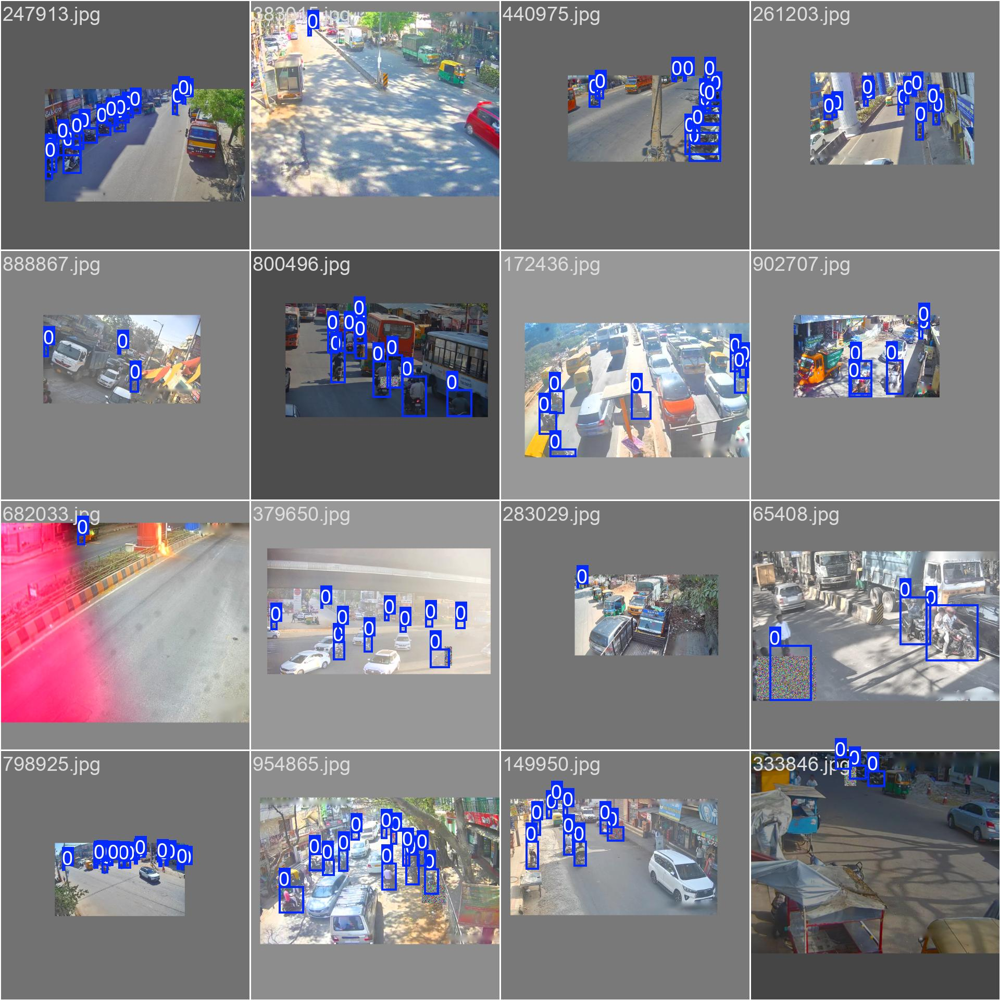

In [45]:
# Cek visual bahwa augmentasi benar-benar terpasang: mosaic training C2 dan C1 harus memperlihatkan penutup di atas motor
from IPython.display import Image, display
for cfg in ("C2", "C1"):
    for f in ("train_batch0.jpg", sorted((RUNS / f"{cfg}_s{SEEDS[0]}").glob("train_batch*.jpg"))[-1].name if (RUNS / f"{cfg}_s{SEEDS[0]}").exists() else None):
        p = RUNS / f"{cfg}_s{SEEDS[0]}" / str(f)
        if f and p.exists():
            print(p); display(Image(str(p), width=640))

## 6. Prediksi mentah dan pemilihan NMS di val (FR-19, FR-20)
Prediksi dijalankan sekali per model per set dengan NMS bawaan hampir mati (`iou=0.99`, `conf=0.001`).
Semua varian NMS (standar dengan berbagai IoU, Soft-NMS Gaussian) diterapkan pada kandidat yang sama, sehingga perbedaannya murni dari post-processing.

In [46]:
import pickle
assert globals().get("LABEL_FINAL_OK"), "jalankan sel 4.7 (kunci label final) dulu"
if not SMOKE:
    assert real_src == "manual", "evaluasi set nyata hanya boleh dengan label manual"
LEVELS_SYN = ["L0", "L1", "L2", "L3"]
# ---- definisi set evaluasi ----
SETS = {}
SETS["val"] = (L.EvalSet("val", L.gts_from_yolo(DATA / "src_train/labels", DATA / "src_train/images", val)),
               {s: DATA / "src_train/images" / f"{s}.jpg" for s in val})
for lv in LEVELS_SYN:
    tg = [(s, k) for s, k in val_targets.items()]
    SETS[f"valsyn_{lv}"] = (L.EvalSet(f"valsyn_{lv}", L.gts_target_only(DATA / "src_train/meta", tg, "{stem}_" + lv)),
                            {f"{s}_{lv}": DATA / "synthetic_val" / lv / "images" / f"{s}_{lv}.jpg" for s, _ in tg})
    tg = [(s, k) for s, k in syn_targets.items()]
    SETS[lv] = (L.EvalSet(lv, L.gts_target_only(DATA / "src_test/meta", tg, "{stem}_" + lv)),
                {f"{s}_{lv}": DATA / "synthetic_test" / lv / "images" / f"{s}_{lv}.jpg" for s, _ in tg})
for lvl in ("bersih", "ringan", "berat"):
    tg = [k for k, v in real_levels.items() if v == lvl]
    if tg:
        SETS[f"nyata_{lvl}"] = (L.EvalSet(f"nyata_{lvl}", L.gts_target_only(DATA / "src_test/meta", tg)),
                                {s: DATA / "src_test/images" / f"{s}.jpg" for s, _ in tg})
print({k: len(v[0].gts) for k, v in SETS.items()})
# anggota tiap set evaluasi (untuk diperiksa ulang)
pd.DataFrame([dict(set=k, citra=s, n_target=int(np.sum(c)), n_ignore=int(np.sum(~np.asarray(c, bool))))
              for k, (es, _) in SETS.items() for s, (g, c) in es.gts.items()]).to_csv(RES / "eval_sets_members.csv", index=False)

RAW = W / "raw_preds"; RAW.mkdir(exist_ok=True)
runs = sorted(p.parent.parent.name for p in RUNS.glob("*/weights/best.pt") if status_run(p.parent.parent) == "selesai")
for run in runs:
    f = RAW / f"{run}.pkl"
    have = pickle.load(open(f, "rb")) if f.exists() else {}
    todo = [k for k in SETS if k not in have or set(SETS[k][1]) != set(have[k])]   # isi set berubah -> prediksi ulang
    if not todo: continue
    model = YOLO(RUNS / run / "weights" / "best.pt")
    for k in todo:
        stems_paths = SETS[k][1]
        raw = L.predict_raw(model, [str(p) for p in stems_paths.values()], imgsz=IMGSZ, device=0)
        have[k] = raw
    pickle.dump(have, open(f, "wb")); print("raw selesai:", run)

{'val': 450, 'valsyn_L0': 355, 'L0': 910, 'valsyn_L1': 355, 'L1': 910, 'valsyn_L2': 355, 'L2': 910, 'valsyn_L3': 355, 'L3': 910, 'nyata_bersih': 365, 'nyata_ringan': 362, 'nyata_berat': 191}


In [47]:
# ---- matching untuk tiap run x varian x set (VERSI CEPAT, hasil identik dengan versi lama) ----
# Lebih cepat karena: (1) Soft-NMS & pencocokan divektorkan, (2) set uji hanya dihitung untuk varian NMS
# yang TERPILIH (std 0.7, std terbaik, soft terbaik), (3) tiap run dikerjakan paralel di semua inti CPU.
import time as _time, os
from joblib import Parallel, delayed
_t_match = _time.time()

VARIANTS = [("std", i) for i in NMS_IOU_GRID] + [("soft", s) for s in SOFT_SIGMA_GRID]
SEL_SETS = ["val", "valsyn_L1", "valsyn_L2", "valsyn_L3"]
TEST_SETS = [k for k in SETS if k not in SEL_SETS]
IOU_THRS_ = np.asarray(L.IOU_THRS)
cfg_of = lambda run: run.split("_s")[0]

def _iou_mat(a, b):
    a = a.astype(np.float64); b = b.astype(np.float64)
    xx1 = np.maximum(a[:, None, 0], b[None, :, 0]); yy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    xx2 = np.minimum(a[:, None, 2], b[None, :, 2]); yy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
    A = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); B = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(A[:, None] + B[None, :] - inter, 1e-9)

def _soft_nms(boxes, scores, sigma, score_thr=0.001, max_det=300, pre_topk=1000):
    if len(boxes) == 0:
        return boxes, scores
    o = scores.argsort()[::-1][:pre_topk]
    B, S = boxes[o].astype(np.float64), scores[o].astype(np.float64).copy()
    iou = _iou_mat(B, B); alive = np.ones(len(S), bool); keep = []
    while len(keep) < max_det and alive.any():
        i = int(np.argmax(np.where(alive, S, -np.inf)))
        if S[i] < score_thr:
            break
        keep.append(i); alive[i] = False
        S[alive] *= np.exp(-(iou[i, alive] ** 2) / sigma)
    keep = np.array(keep, dtype=int)
    return B[keep].reshape(-1, 4), S[keep]

def _hard_nms(boxes, scores, thr, max_det=300):
    import torch, torchvision
    if len(boxes) == 0:
        return boxes, scores
    k = torchvision.ops.nms(torch.as_tensor(boxes, dtype=torch.float32), torch.as_tensor(scores, dtype=torch.float32), thr).numpy()[:max_det]
    return boxes[k], scores[k]

def _match_image(pb, ps, gt, care):
    n_thr = len(IOU_THRS_)
    o = np.argsort(-ps); pb, ps = pb[o], ps[o]
    tp = np.zeros((len(ps), n_thr), dtype=np.int8)
    care = np.asarray(care, dtype=bool)
    if len(gt) == 0 or len(pb) == 0:
        return ps, tp, int(care.sum())
    ious = _iou_mat(pb, np.asarray(gt, dtype=np.float64))
    rows = np.where(ious.max(1) >= IOU_THRS_[0])[0]          # prediksi tanpa tumpang tindih >= 0.5 pasti FP
    for t, thr in enumerate(IOU_THRS_):
        used = np.zeros(len(gt), bool)
        for i in rows:
            hit = ious[i] >= thr
            cand = np.where(care & ~used & hit)[0]
            if len(cand):
                j = cand[np.argmax(ious[i, cand])]; used[j] = True; tp[i, t] = 1
            elif np.any(~care & hit):
                tp[i, t] = -1
    return ps, tp, int(care.sum())

def _post(raw, v):
    f = (lambda b, s: _hard_nms(b, s, v[1])) if v[0] == "std" else (lambda b, s: _soft_nms(b, s, v[1]))
    return {k: f(b, s) for k, (b, s) in raw.items()}

def _match_set(gts, preds):
    z = (np.zeros((0, 4)), np.zeros(0))
    return {stem: _match_image(*preds.get(stem, z), gt, care) for stem, (gt, care) in gts.items()}

def _job(run, variants, set_names, gts_by_set):
    import torch; torch.set_num_threads(1)
    raw_all = pickle.load(open(RAW / f"{run}.pkl", "rb"))
    out = {}
    for v in variants:
        for k in set_names:
            out[(run, v, k)] = _match_set(gts_by_set[k], _post(raw_all[k], v))
    return out

N_JOBS = max(1, min(len(runs), os.cpu_count() or 1))
GTS = {k: es.gts for k, (es, _) in SETS.items()}
print(f"{len(runs)} run, {N_JOBS} proses paralel")

# tahap 1: semua varian, hanya set seleksi (val + valsyn)
MATCH = {}
for d in Parallel(n_jobs=N_JOBS)(delayed(_job)(r, VARIANTS, SEL_SETS, {k: GTS[k] for k in SEL_SETS}) for r in runs):
    MATCH.update(d)
print(f"tahap 1 (seleksi NMS) selesai: {round(_time.time() - _t_match)} detik")

rows = []
for run in runs:
    for v in VARIANTS:
        r = {k: L.summarize(MATCH[(run, v, k)])["AP50_95"] for k in SEL_SETS}
        rows.append(dict(run=run, cfg=cfg_of(run), variant=f"{v[0]}:{v[1]}", sel_score=np.mean(list(r.values())), **r))
sel = pd.DataFrame(rows)
sel.to_csv(RES / "FR19_20_val_sweep.csv", index=False)
g = sel.groupby(["cfg", "variant"]).sel_score.mean().unstack(0); display(g.round(4))

# pilih IoU terbaik (std) dan sigma terbaik (soft) PER KONFIGURASI, hanya dari val
BEST = {}
for cfg in sel.cfg.unique():
    s = sel[sel.cfg == cfg].groupby("variant").sel_score.mean()
    BEST[cfg] = {"std_default": ("std", 0.7),
                 "std_best": ("std", float(s[s.index.str.startswith("std")].idxmax().split(":")[1])),
                 "soft": ("soft", float(s[s.index.str.startswith("soft")].idxmax().split(":")[1]))}
print(BEST); json.dump({c: {k: list(v) for k, v in d.items()} for c, d in BEST.items()}, open(RES / "FR19_20_selected.json", "w"), indent=2)

# tahap 2: set uji (L0-L3 + nyata) hanya untuk varian terpilih
jobs = [delayed(_job)(r, sorted(set(BEST[cfg_of(r)].values())), TEST_SETS, {k: GTS[k] for k in TEST_SETS}) for r in runs]
for d in Parallel(n_jobs=N_JOBS)(jobs):
    MATCH.update(d)
print("kombinasi:", len(MATCH))

# ambang confidence: F1 maksimum di val bersih, per run x varian (FR-17)
CONF = {(run, v): L.best_f1_conf(MATCH[(run, v, "val")])[0] for run in runs for v in VARIANTS}
print("waktu matching + seleksi NMS:", round(_time.time() - _t_match), "detik")

9 run, 4 proses paralel
tahap 1 (seleksi NMS) selesai: 172 detik


cfg,C0,C1,C2
variant,,,
soft:0.3,0.2684,0.2765,0.4104
soft:0.5,0.2664,0.2748,0.4088
soft:0.7,0.2641,0.2727,0.4062
std:0.5,0.2664,0.2746,0.4044
std:0.6,0.2669,0.2754,0.4060
std:0.7,0.2673,0.2758,0.4069
std:0.8,0.2664,0.2747,0.4059


{'C0': {'std_default': ('std', 0.7), 'std_best': ('std', 0.7), 'soft': ('soft', 0.3)}, 'C1': {'std_default': ('std', 0.7), 'std_best': ('std', 0.7), 'soft': ('soft', 0.3)}, 'C2': {'std_default': ('std', 0.7), 'std_best': ('std', 0.7), 'soft': ('soft', 0.3)}}
kombinasi: 396
waktu matching + seleksi NMS: 294 detik


## 7. Evaluasi per tingkat (FR-21, FR-22)

In [48]:
EVAL_SETS = [k for k in ["L0", "L1", "L2", "L3", "nyata_bersih", "nyata_ringan", "nyata_berat"] if k in SETS]
rows = []
for run in runs:
    cfg = cfg_of(run)
    for vname, v in BEST[cfg].items():
        for k in EVAL_SETS:
            m = L.summarize(MATCH[(run, v, k)], conf_thr=CONF[(run, v)])
            rows.append(dict(cfg=cfg, seed=run.split("_s")[1], nms=vname, nms_param=v[1], set=k, **m))
per_seed = pd.DataFrame(rows); per_seed.to_csv(RES / "FR21_per_seed.csv", index=False)

agg = per_seed.groupby(["cfg", "nms", "set"]).agg(
    AP50=("AP50", "mean"), AP50_sd=("AP50", "std"), AP50_95=("AP50_95", "mean"), AP50_95_sd=("AP50_95", "std"),
    P=("P", "mean"), R=("R", "mean"), R_sd=("R", "std"), n_gt=("n_gt", "first"), n_seed=("seed", "nunique")).reset_index()
agg.to_csv(RES / "FR21_22_main_table.csv", index=False)
fmt = lambda m, s: f"{m:.3f} ± {s:.3f}" if pd.notna(s) else f"{m:.3f}"
tbl = agg.assign(cell=[fmt(a, b) for a, b in zip(agg.AP50, agg.AP50_sd)]).pivot_table(
    index=["cfg", "nms"], columns="set", values="cell", aggfunc="first")[EVAL_SETS]
tbl.to_csv(RES / "TABLE_AP50_mean_sd.csv"); display(tbl)

set                         L0             L1             L2             L3  \
cfg nms                                                                       
C0  soft         0.856 ± 0.009  0.541 ± 0.018  0.149 ± 0.016  0.017 ± 0.006   
    std_best     0.852 ± 0.010  0.531 ± 0.018  0.144 ± 0.016  0.017 ± 0.006   
    std_default  0.852 ± 0.010  0.531 ± 0.018  0.144 ± 0.016  0.017 ± 0.006   
C1  soft         0.856 ± 0.003  0.545 ± 0.003  0.168 ± 0.016  0.021 ± 0.003   
    std_best     0.852 ± 0.003  0.537 ± 0.004  0.163 ± 0.016  0.020 ± 0.003   
    std_default  0.852 ± 0.003  0.537 ± 0.004  0.163 ± 0.016  0.020 ± 0.003   
C2  soft         0.857 ± 0.004  0.743 ± 0.006  0.538 ± 0.014  0.298 ± 0.024   
    std_best     0.853 ± 0.004  0.735 ± 0.007  0.524 ± 0.014  0.286 ± 0.022   
    std_default  0.853 ± 0.004  0.735 ± 0.007  0.524 ± 0.014  0.286 ± 0.022   

set               nyata_bersih   nyata_ringan    nyata_berat  
cfg nms                                                       
C0  soft         0.838 ± 0.008  0.725 ± 0.006  0.568 ± 0.004  
    std_best     0.847 ± 0.007  0.754 ± 0.006  0.582 ± 0.007  
    std_default  0.847 ± 0.007  0.754 ± 0.006  0.582 ± 0.007  
C1  soft         0.840 ± 0.008  0.735 ± 0.013  0.575 ± 0.023  
    std_best     0.852 ± 0.006  0.767 ± 0.012  0.590 ± 0.023  
    std_default  0.852 ± 0.006  0.767 ± 0.012  0.590 ± 0.023  
C2  soft         0.848 ± 0.003  0.721 ± 0.010  0.566 ± 0.009  
    std_best     0.856 ± 0.002  0.749 ± 0.014  0.584 ± 0.010  
    std_default  0.856 ± 0.002  0.749 ± 0.014  0.584 ± 0.010

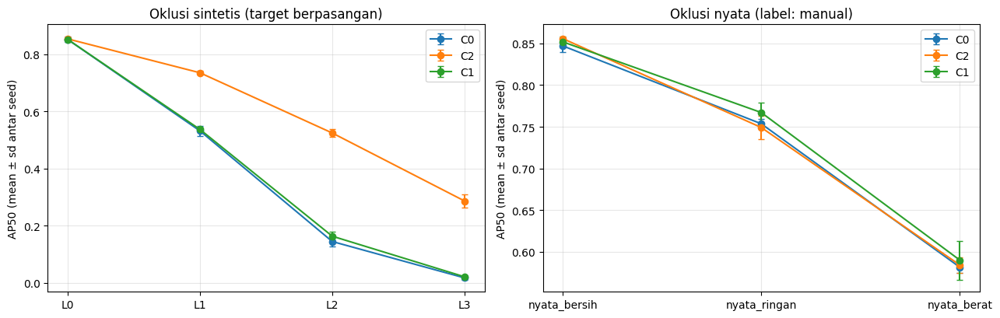

In [49]:
# RQ1: kurva AP50 vs tingkat oklusi (NMS default), rata-rata antar seed
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for cfg in CONFIGS:
    d = agg[(agg.cfg == cfg) & (agg.nms == "std_default")].set_index("set")
    syn = [k for k in ["L0", "L1", "L2", "L3"] if k in d.index]
    real = [k for k in ["nyata_bersih", "nyata_ringan", "nyata_berat"] if k in d.index]
    axs[0].errorbar(syn, d.loc[syn, "AP50"], yerr=d.loc[syn, "AP50_sd"], marker="o", capsize=3, label=cfg)
    if real: axs[1].errorbar(real, d.loc[real, "AP50"], yerr=d.loc[real, "AP50_sd"], marker="o", capsize=3, label=cfg)
axs[0].set_title("Oklusi sintetis (target berpasangan)"); axs[1].set_title(f"Oklusi nyata (label: {real_src})")
for a in axs: a.set_ylabel("AP50 (mean ± sd antar seed)"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(RES / "FIG_rq1_ap_vs_level.png", dpi=150); plt.show()

## 8. Bootstrap CI, ablasi (FR-22, FR-23) dan analisis transfer (FR-24)

In [50]:
# ============ Bagian 8: bootstrap CI + ablasi (FR-22, FR-23) — versi cepat ============
import time as _t
BOOT_AP5095 = False   # True = ikut hitung CI untuk AP50:95 (kira-kira 5x lebih lama). AP50, P, R selalu dihitung.

def prep_run(per, stems):
    """Siapkan satu run x set sekali saja: skor terurut, status TP/FP per ambang IoU, indeks citra."""
    idx = {s: i for i, s in enumerate(stems)}
    S = np.concatenate([per[s][0] for s in stems]); T = np.concatenate([per[s][1] for s in stems])
    I = np.concatenate([np.full(len(per[s][0]), idx[s]) for s in stems]).astype(np.int64)
    ngt = np.array([per[s][2] for s in stems], dtype=np.float64)
    o = np.argsort(-S, kind="mergesort")
    return dict(S=S[o], T=T[o], I=I[o], ngt=ngt)

def wmetrics(r, w, conf, thr_cols):
    """AP50, AP50:95, P, R dengan bobot citra w (identik dengan summarize pada citra yang diambil ulang)."""
    n = float((w * r["ngt"]).sum())
    if n == 0:
        return dict(AP50=np.nan, AP50_95=np.nan, P=np.nan, R=np.nan)
    wd = w[r["I"]]; rs = np.linspace(0, 1, 101); aps = []
    for t in thr_cols:
        v = r["T"][:, t]; keep = v >= 0
        ww, vv = wd[keep], v[keep]
        if len(vv) == 0:
            aps.append(0.0); continue
        ctp = np.cumsum(ww * (vv == 1)); cfp = np.cumsum(ww * (vv == 0))
        rec = ctp / n; prec = ctp / np.maximum(ctp + cfp, 1)
        prec = np.maximum.accumulate(prec[::-1])[::-1]
        j = np.searchsorted(rec, rs, side="left")
        aps.append(float(np.where(j < len(prec), prec[np.minimum(j, len(prec) - 1)], 0.0).mean()))
    m = (r["S"] >= conf) & (r["T"][:, 0] >= 0)
    tp = float((wd[m] * (r["T"][m, 0] == 1)).sum()); fp = float((wd[m] * (r["T"][m, 0] == 0)).sum())
    return dict(AP50=aps[0], AP50_95=float(np.mean(aps)) if len(aps) > 1 else np.nan,
                P=tp / max(tp + fp, 1e-9), R=tp / n)

def boot_curve(per_list, confs, stems, Wmat, thr):
    """Metrik (rata-rata antar seed) untuk setiap baris bobot di Wmat. Baris 0 = data asli."""
    R = [prep_run(p, stems) for p in per_list]
    out = {}
    for b, w in enumerate(Wmat):
        ms = [wmetrics(r, w, c, thr) for r, c in zip(R, confs)]
        for k in ms[0]:
            out.setdefault(k, np.empty(len(Wmat)))[b] = np.nanmean([m[k] for m in ms])
    return out

def runs_of(cfg, nms):
    rs = [r for r in runs if cfg_of(r) == cfg]; v = BEST[cfg][nms]
    return rs, v, [CONF[(r, v)] for r in rs]

aug_cfgs = [c for c in CONFIGS if c != "C0" and any(cfg_of(r) == c for r in runs)]
COMPARE = [("NMS saja (IoU terbaik)", "C0", "std_best"), ("NMS saja (Soft-NMS)", "C0", "soft")]
for c in aug_cfgs:
    COMPARE += [(f"Augmentasi saja ({c})", c, "std_default"), (f"Gabungan ({c} + Soft-NMS)", c, "soft"),
                (f"Gabungan ({c} + IoU terbaik)", c, "std_best")]

_t0 = _t.time(); rows = []
THR = list(range(10)) if BOOT_AP5095 else [0]
ra, va, ca = runs_of("C0", "std_default")
for k in EVAL_SETS:
    stems = list(SETS[k][0].gts); n = len(stems)
    rng = np.random.default_rng(0)                      # citra yang sama diambil ulang untuk semua perbandingan
    Wmat = np.vstack([np.ones(n)] + [np.bincount(rng.integers(0, n, n), minlength=n) for _ in range(N_BOOT)]).astype(np.float64)
    base = boot_curve([MATCH[(r, va, k)] for r in ra], ca, stems, Wmat, THR)   # baseline: sekali per set
    for label, cfg, nms in COMPARE:
        rb, vb, cb = runs_of(cfg, nms)
        other = boot_curve([MATCH[(r, vb, k)] for r in rb], cb, stems, Wmat, THR)
        for metric in base:
            dd = other[metric] - base[metric]
            if np.isnan(dd[0]):
                continue
            lo, hi = np.nanpercentile(dd[1:], [2.5, 97.5])
            rows.append(dict(perbandingan=label, set=k, metric=metric, delta=dd[0], ci_lo=lo, ci_hi=hi,
                             signifikan=(lo > 0) or (hi < 0)))
    print(f"  {k} selesai ({_t.time() - _t0:.0f} detik)")
abl = pd.DataFrame(rows); abl["n_boot"] = N_BOOT; abl["seed_bootstrap"] = 0
abl.to_csv(RES / "FR22_23_ablation_bootstrap.csv", index=False)
json.dump(dict(n_boot=N_BOOT, seed_bootstrap=0, metrik=sorted(abl.metric.unique().tolist()), ap50_95_dihitung=BOOT_AP5095,
               metode="bootstrap berpasangan nonparametrik: citra (stem) tiap set evaluasi diambil ulang dengan pengembalian; "
                      "sampel ulang yang sama dipakai untuk semua perbandingan; metrik dihitung per seed lalu dirata-rata per replikasi",
               interval="persentil 2,5-97,5 (CI 95%)", baseline="C0 + NMS std 0.7", unit_sampling="citra",
               n_citra_per_set={k: len(SETS[k][0].gts) for k in EVAL_SETS}),
          open(RES / "FR22_bootstrap_config.json", "w"), indent=2)
show = abl[abl.metric == "AP50"].assign(cell=lambda d: [f"{a:+.3f} [{b:+.3f}, {c:+.3f}]{' *' if s else ''}"
                                                        for a, b, c, s in zip(d.delta, d.ci_lo, d.ci_hi, d.signifikan)])
display(show.pivot_table(index="perbandingan", columns="set", values="cell", aggfunc="first")[EVAL_SETS])
print("* = 95% CI tidak memuat nol (bermakna) | total waktu:", round(_t.time() - _t0), "detik")

/tmp/ipykernel_136/2417318020.py:42: RuntimeWarning: Mean of empty slice
  out.setdefault(k, np.empty(len(Wmat)))[b] = np.nanmean([m[k] for m in ms])


  L0 selesai (32 detik)
  L1 selesai (65 detik)
  L2 selesai (96 detik)
  L3 selesai (127 detik)
  nyata_bersih selesai (147 detik)
  nyata_ringan selesai (166 detik)
  nyata_berat selesai (178 detik)


set,L0,L1,L2,L3,nyata_bersih,nyata_ringan,nyata_berat
perbandingan,,,,,,,
Augmentasi saja (C1),"+0.000 [-0.006, +0.005]","+0.005 [-0.006, +0.017]","+0.019 [+0.009, +0.030] *","+0.004 [+0.001, +0.007] *","+0.005 [-0.004, +0.014]","+0.013 [+0.003, +0.026] *","+0.009 [-0.015, +0.029]"
Augmentasi saja (C2),"+0.002 [-0.004, +0.008]","+0.203 [+0.185, +0.222] *","+0.380 [+0.355, +0.409] *","+0.269 [+0.248, +0.296] *","+0.009 [-0.001, +0.017]","-0.004 [-0.018, +0.010]","+0.003 [-0.025, +0.024]"
Gabungan (C1 + IoU terbaik),"+0.000 [-0.006, +0.005]","+0.005 [-0.006, +0.017]","+0.019 [+0.009, +0.030] *","+0.004 [+0.001, +0.007] *","+0.005 [-0.004, +0.014]","+0.013 [+0.003, +0.026] *","+0.009 [-0.015, +0.029]"
Gabungan (C1 + Soft-NMS),"+0.004 [-0.002, +0.009]","+0.014 [+0.003, +0.026] *","+0.024 [+0.014, +0.035] *","+0.004 [+0.001, +0.008] *","-0.007 [-0.018, +0.004]","-0.019 [-0.032, -0.004] *","-0.006 [-0.034, +0.020]"
Gabungan (C2 + IoU terbaik),"+0.002 [-0.004, +0.008]","+0.203 [+0.185, +0.222] *","+0.380 [+0.355, +0.409] *","+0.269 [+0.248, +0.296] *","+0.009 [-0.001, +0.017]","-0.004 [-0.018, +0.010]","+0.003 [-0.025, +0.024]"
Gabungan (C2 + Soft-NMS),"+0.006 [+0.001, +0.012] *","+0.211 [+0.193, +0.231] *","+0.394 [+0.368, +0.423] *","+0.281 [+0.260, +0.309] *","+0.001 [-0.009, +0.011]","-0.033 [-0.048, -0.018] *","-0.016 [-0.046, +0.008]"
NMS saja (IoU terbaik),"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]"
NMS saja (Soft-NMS),"+0.004 [+0.003, +0.005] *","+0.010 [+0.007, +0.012] *","+0.005 [+0.004, +0.007] *","+0.000 [+0.000, +0.001] *","-0.009 [-0.014, -0.005] *","-0.028 [-0.036, -0.020] *","-0.013 [-0.026, -0.002] *"


* = 95% CI tidak memuat nol (bermakna) | total waktu: 178 detik


,perbandingan,delta_sintetis,delta_nyata,arah_sama,rasio_transfer,d_L1L2,d_ringan,d_L3,d_berat
0,NMS saja (IoU terbaik),0.0000,0.0000,True,NaN,0.0000,0.0000,0.0000,0.0000
1,NMS saja (Soft-NMS),0.0051,-0.0209,False,-4.1129,0.0074,-0.0283,0.0005,-0.0134
2,Augmentasi saja (C2),0.2841,-0.0009,False,-0.0033,0.2916,-0.0045,0.2691,0.0026
3,Gabungan (C2 + Soft-NMS),0.2954,-0.0243,False,-0.0821,0.3025,-0.0329,0.2813,-0.0156
4,Gabungan (C2 + IoU terbaik),0.2841,-0.0009,False,-0.0033,0.2916,-0.0045,0.2691,0.0026
5,Augmentasi saja (C1),0.0092,0.0110,True,1.1932,0.0119,0.0135,0.0038,0.0085
6,Gabungan (C1 + Soft-NMS),0.0142,-0.0127,False,-0.8934,0.0191,-0.0189,0.0044,-0.0065
7,Gabungan (C1 + IoU terbaik),0.0092,0.0110,True,1.1932,0.0119,0.0135,0.0038,0.0085


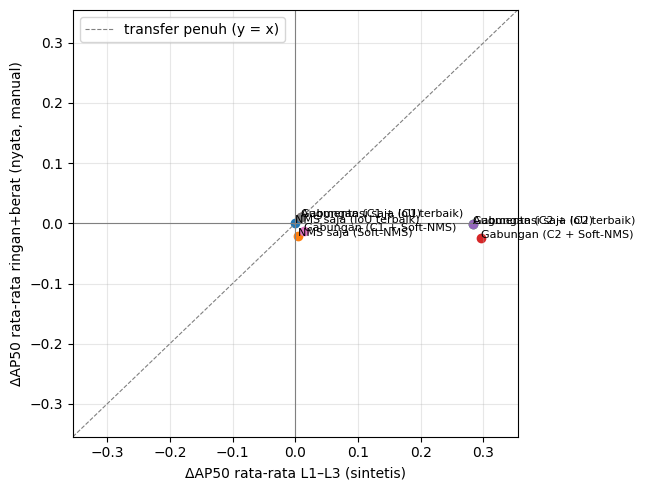

In [51]:
# FR-24 / RQ3: apakah perubahan di sintetis diikuti di nyata?
syn_k = [k for k in ["L1", "L2", "L3"] if k in EVAL_SETS]
real_k = [k for k in ["nyata_ringan", "nyata_berat"] if k in EVAL_SETS]
tr_rows = []
for label in abl.perbandingan.unique():
    d = abl[(abl.perbandingan == label) & (abl.metric == "AP50")].set_index("set")
    ds, dr = d.loc[syn_k, "delta"].mean(), d.loc[real_k, "delta"].mean() if real_k else np.nan
    tr_rows.append(dict(perbandingan=label, delta_sintetis=ds, delta_nyata=dr, arah_sama=np.sign(ds) == np.sign(dr),
                        rasio_transfer=dr / ds if abs(ds) > 1e-9 else np.nan,
                        # pasangan setara tingkat: L1/L2 ~ ringan (<=50%), L3 ~ berat (>50%)
                        d_L1L2=d.loc[[k for k in ("L1", "L2") if k in d.index], "delta"].mean(),
                        d_ringan=d.loc["nyata_ringan", "delta"] if "nyata_ringan" in d.index else np.nan,
                        d_L3=d.loc["L3", "delta"] if "L3" in d.index else np.nan,
                        d_berat=d.loc["nyata_berat", "delta"] if "nyata_berat" in d.index else np.nan))
transfer = pd.DataFrame(tr_rows); transfer.to_csv(RES / "FR24_transfer.csv", index=False); display(transfer.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.axhline(0, c="gray", lw=.8); ax.axvline(0, c="gray", lw=.8)
lim = np.nanmax(np.abs(transfer[["delta_sintetis", "delta_nyata"]].values)) * 1.2 or 0.05
ax.plot([-lim, lim], [-lim, lim], ls="--", c="gray", lw=.8, label="transfer penuh (y = x)")
for _, r in transfer.iterrows():
    ax.scatter(r.delta_sintetis, r.delta_nyata); ax.annotate(r.perbandingan, (r.delta_sintetis, r.delta_nyata), fontsize=8)
ax.set_xlabel("ΔAP50 rata-rata L1–L3 (sintetis)"); ax.set_ylabel(f"ΔAP50 rata-rata ringan+berat (nyata, {real_src})")
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / "FIG_rq3_transfer.png", dpi=150); plt.show()

In [52]:
# FR-24: simpan 10-20 contoh prediksi per tingkat (C0 vs konfigurasi augmentasi terbaik, Soft-NMS)
best_aug = transfer[transfer.perbandingan.str.startswith("Gabungan")].sort_values("delta_sintetis").perbandingan.iloc[-1] if aug_cfgs else None
cmp_cfg = best_aug.split("(")[1].split(" ")[0] if best_aug else "C0"
import random
EXD = RES / "examples"; EXD.mkdir(exist_ok=True)
def draw(run, v, k, key, path, thr):
    raw = pickle.load(open(RAW / f"{run}.pkl", "rb"))[k][key]
    b, s = L.postprocess({key: raw}, v)[key]
    im = cv2.imread(str(path)); gt, care = SETS[k][0].gts[key]
    for g, c in zip(gt, care):
        cv2.rectangle(im, tuple(map(int, g[:2])), tuple(map(int, g[2:])), (0, 255, 0) if c else (128, 128, 128), 2)
    for bb, ss in zip(b, s):
        if ss >= thr: cv2.rectangle(im, tuple(map(int, bb[:2])), tuple(map(int, bb[2:])), (0, 0, 255), 1)
    return im
for k in EVAL_SETS:
    keys = random.Random(0).sample(sorted(SETS[k][0].gts), min(15, len(SETS[k][0].gts)))
    for cfg, nms in (("C0", "std_default"), (cmp_cfg, "soft")):
        run = f"{cfg}_s{SEEDS[0]}"
        if run not in runs: continue
        v = BEST[cfg][nms]; (EXD / k / f"{cfg}_{nms}").mkdir(parents=True, exist_ok=True)
        for key in keys:
            cv2.imwrite(str(EXD / k / f"{cfg}_{nms}" / f"{key}.jpg"), draw(run, v, k, key, SETS[k][1][key], CONF[(run, v)]))
print("contoh disimpan di", EXD, "(hijau = target, abu = ignore, merah = prediksi)")

contoh disimpan di /kaggle/working/results_v6_e60_ulang/examples (hijau = target, abu = ignore, merah = prediksi)


In [53]:
# Ringkasan untuk Bab 4 + EKSPOR LENGKAP (poin 8) + bersihkan state widget (poin 9)
import glob, zipfile
import hashlib
if not SMOKE:
    assert real_src == "manual", "hasil belum boleh diekspor: label set nyata bukan manual"
    _lock = json.load(open(RES / "real_labels_manifest.json"))
    _now = hashlib.sha256(open(REAL_TAGS_CSV, "rb").read()).hexdigest()
    assert _now == _lock["sha256_real_tags"], ("real_tags.csv berubah setelah 4.7 dikunci -> jalankan ulang 4.7 dan bagian 6-8 "
                                               "agar hasil dan ZIP memakai label yang sama")
print("MODE:", "UJI ASAP" if SMOKE else BUDGET, "| Label set nyata:", real_src.upper(), "| GATE 1:", GATE_OK,
      "| kappa:", kappa_info.get("kappa", "belum"), kappa_info.get("jenis", ""), "| dataset", REPO_ID, REVISION)
print("Run:", runs)

EKS = RES / "ekspor"; EKS.mkdir(exist_ok=True)
def _cp(src, dst):
    src = Path(src)
    if src.exists():
        Path(dst).parent.mkdir(parents=True, exist_ok=True); shutil.copy(src, dst)
for p in (DATA / "splits").glob("*.txt"):                                   # ID gambar tiap split
    _cp(p, EKS / "splits" / p.name)
for part in ("synthetic_test", "synthetic_val"):                            # metadata oklusi sintetis
    _cp(DATA / part / "synthetic_log.csv", EKS / "sintetis" / f"{part}_log.csv")
for f in ("real_candidates.csv", "real_tags.csv", "real_tags_raw.csv", "aturan_penandaan.json", "tag_order.csv"):
    _cp(DATA / "real_test" / f, EKS / "label_nyata" / f)                    # label mentah + final + aturan
for part in ("pool_train", "pool_test"):                                   # daftar potongan penutup
    _cp(DATA / "occluders" / part / "pool.csv", EKS / "sintetis" / f"{part}.csv")
for r in runs:                                                              # konfigurasi + kurva per run
    for f in ("args.yaml", "results.csv"):
        _cp(RUNS / r / f, EKS / "runs" / r / f)
pickle.dump(dict(MATCH=MATCH, CONF=CONF, BEST=BEST, VARIANTS=VARIANTS), open(EKS / "matching.pkl", "wb"))   # matching per citra
with zipfile.ZipFile(W / "raw_preds.zip", "w", zipfile.ZIP_DEFLATED) as z:  # prediksi mentah (terpisah, bisa besar)
    for p in RAW.glob("*.pkl"):
        z.write(p, p.name)
json.dump(dict(mode="UJI ASAP" if SMOKE else BUDGET, label=real_src, runs=runs, n_boot=N_BOOT, seeds=SEEDS,
               file_label_final="real_labels_final.csv", file_prediksi=f"raw_preds.zip (di {W})"),
          open(RES / "ekspor_manifest.json", "w"), indent=2)
shutil.make_archive(str(W / "results_bab4"), "zip", RES)
print("arsip:", W / "results_bab4.zip", "(", round((W / "results_bab4.zip").stat().st_size / 1e6, 1), "MB ) + raw_preds.zip")

# Poin 9: state widget (gambar alat penandaan) membuat .ipynb sangat besar dan terpotong saat diunduh. Tutup semua widget.
try:
    from ipywidgets import Widget
    Widget.close_all()
    print("state widget dibersihkan: simpan versi notebook sekarang (Save Version)")
except Exception as e:
    print("lewati pembersihan widget:", type(e).__name__)

MODE: PENUH | Label set nyata: MANUAL | GATE 1: True | kappa: belum  | dataset iisc-aim/UVH-26 v1.0
Run: ['C0_s0', 'C0_s1', 'C0_s2', 'C1_s0', 'C1_s1', 'C1_s2', 'C2_s0', 'C2_s1', 'C2_s2']
arsip: /kaggle/working/results_bab4.zip ( 131.4 MB ) + raw_preds.zip
state widget dibersihkan: simpan versi notebook sekarang (Save Version)


citra uji: 400 | motor (GT): 2348 | kondisi: 8
  C0_s0 selesai (61 detik)
  C0_s1 selesai (123 detik)
  C0_s2 selesai (187 detik)
  C1_s0 selesai (251 detik)
  C1_s1 selesai (313 detik)
  C1_s2 selesai (376 detik)
  C2_s0 selesai (443 detik)
  C2_s1 selesai (509 detik)
  C2_s2 selesai (574 detik)

(1) AKURASI pada citra uji normal (semua motor, rata-rata ± sd antar seed)


,AP50,AP50_95,P,R,F1
cfg,,,,,
C0,0.892 ± 0.005,0.681 ± 0.004,0.864 ± 0.006,0.807 ± 0.011,0.834 ± 0.003
C1,0.895 ± 0.002,0.686 ± 0.002,0.858 ± 0.011,0.814 ± 0.008,0.835 ± 0.001
C2,0.893 ± 0.004,0.682 ± 0.003,0.866 ± 0.011,0.807 ± 0.011,0.836 ± 0.006



(2) AP50 per kondisi cahaya


cfg,C0,C1,C2
kondisi,,,
malam (sim.),0.797,0.809,0.791
sangat gelap,0.844,0.849,0.842
gelap,0.878,0.882,0.878
redup,0.889,0.892,0.890
normal,0.892,0.895,0.893
kontras rendah,0.878,0.881,0.881
terang,0.876,0.882,0.878
sangat terang,0.751,0.769,0.760


Perubahan relatif terhadap 'normal' (%)


cfg,C0,C1,C2
kondisi,,,
malam (sim.),-10.6,-9.6,-11.4
sangat gelap,-5.4,-5.1,-5.8
gelap,-1.6,-1.4,-1.7
redup,-0.4,-0.3,-0.4
normal,0.0,0.0,0.0
kontras rendah,-1.5,-1.5,-1.4
terang,-1.7,-1.4,-1.7
sangat terang,-15.8,-14.0,-14.9


,skor ketahanan (1 = kebal)
cfg,
C0,0.947
C1,0.952
C2,0.947



(3) Cahaya alami (kecerahan rata-rata V: gelap < 145 <= sedang < 152 <= terang)


cfg,C0,C1,C2
kelompok,,,
gelap alami,0.880,0.881,0.883
sedang,0.897,0.902,0.900
terang alami,0.900,0.900,0.899


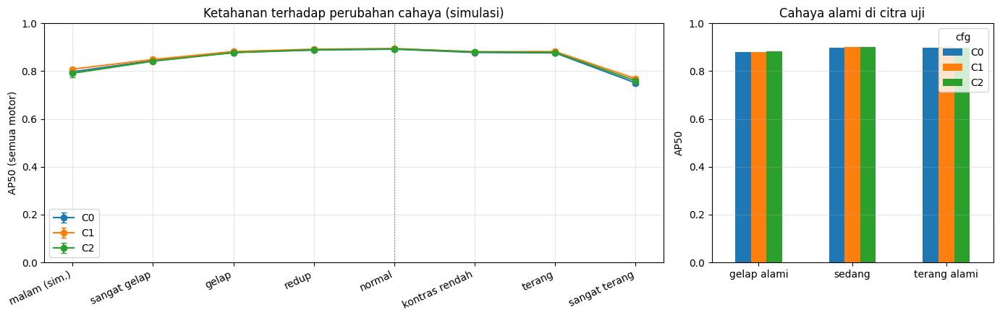

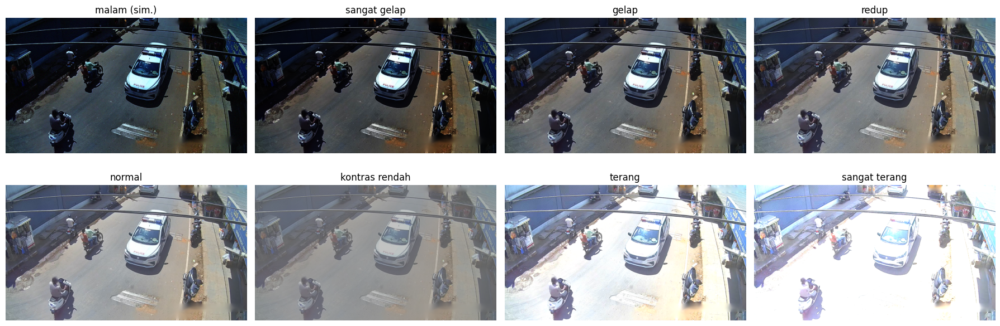

total waktu: 578 detik | file: ACCURACY_test_clean.csv, LIGHT_*.csv, FIG_lighting*.png


In [54]:
# ============ Bagian 10: akurasi model + ketahanan terhadap pencahayaan ============
# Butuh variabel dari sel sebelumnya: L, DATA, RUNS, RES, IMGSZ, test, runs, cfg_of, CONF
import time as _t
import matplotlib.pyplot as plt
from ultralytics import YOLO

N_LIGHT_IMGS = 400          # jumlah citra uji yang dipakai (None = semua). 400 cukup dan jauh lebih cepat
LIGHT_CFGS   = None         # None = semua konfigurasi; atau mis. ["C0", "C2"]
NMS_EVAL     = ("std", 0.7) # NMS standar, sama seperti aplikasi deteksi

# ---- kondisi cahaya: nama -> fungsi pada citra BGR uint8 (deterministik, tanpa acak kecuali derau ber-seed) ----
def _gamma(g):
    lut = (255 * (np.arange(256) / 255) ** g).clip(0, 255).astype(np.uint8)
    return lambda im: cv2.LUT(im, lut)
def _gain(a):
    return lambda im: cv2.convertScaleAbs(im, alpha=a, beta=0)
def _contrast(c):
    return lambda im: cv2.addWeighted(im, c, np.full_like(im, int(im.mean())), 1 - c, 0)
def _night(g, sigma):
    def f(im):
        d = _gamma(g)(im).astype(np.float32)
        d[..., 0] *= 1.10; d[..., 2] *= 0.85                                   # lampu malam: sedikit kebiruan
        noise = np.random.default_rng(int(im[::50, ::50].sum()) % 2**32).normal(0, sigma, d.shape)
        return np.clip(d + noise, 0, 255).astype(np.uint8)                       # derau sensor kamera
    return f

LIGHT = {                         # urutan = dari paling gelap ke paling terang
    "malam (sim.)":      _night(3.0, 8),
    "sangat gelap":      _gamma(3.0),
    "gelap":             _gamma(2.0),
    "redup":             _gamma(1.5),
    "normal":            lambda im: im,
    "kontras rendah":    _contrast(0.5),
    "terang":            _gain(1.5),
    "sangat terang":     _gain(2.2),
}

# ---- data uji: semua motor dihitung (bukan hanya target), dari citra uji asli ----
stems_l = list(test) if N_LIGHT_IMGS is None else sorted(np.random.default_rng(0).choice(test, min(N_LIGHT_IMGS, len(test)), replace=False))
es_l = L.EvalSet("light", L.gts_from_yolo(DATA / "src_test/labels", DATA / "src_test/images", stems_l))
imgs_l = {s: cv2.imread(str(DATA / "src_test/images" / f"{s}.jpg")) for s in stems_l}
print(f"citra uji: {len(stems_l)} | motor (GT): {sum(len(g) for g, _ in es_l.gts.values())} | kondisi: {len(LIGHT)}")

def predict_arrays(model, arrs, batch=16):
    raw = {}
    keys = list(arrs)
    for i in range(0, len(keys), batch):
        ks = keys[i:i + batch]
        res = model.predict([arrs[k] for k in ks], imgsz=IMGSZ, conf=0.001, iou=0.99, max_det=1000,
                            verbose=False, device=0, agnostic_nms=True)
        for k, r in zip(ks, res):
            raw[k] = (r.boxes.xyxy.cpu().numpy().astype(np.float32), r.boxes.conf.cpu().numpy().astype(np.float32))
    return raw

eval_runs = [r for r in runs if LIGHT_CFGS is None or cfg_of(r) in LIGHT_CFGS]
rows, PER_LIGHT = [], {}
_t0 = _t.time()
for run in eval_runs:
    model = YOLO(RUNS / run / "weights" / "best.pt")
    thr = CONF.get((run, NMS_EVAL), 0.25)                                   # ambang F1-maks dari val
    for cond, fn in LIGHT.items():
        raw = predict_arrays(model, {s: fn(im) for s, im in imgs_l.items()})
        per = es_l.match(L.postprocess(raw, NMS_EVAL))
        PER_LIGHT[(run, cond)] = per
        m = L.summarize(per, conf_thr=thr)
        f1 = 2 * m["P"] * m["R"] / max(m["P"] + m["R"], 1e-9)
        rows.append(dict(cfg=cfg_of(run), run=run, kondisi=cond, AP50=m["AP50"], AP50_95=m["AP50_95"],
                         P=m["P"], R=m["R"], F1=f1, conf_thr=thr))
    print(f"  {run} selesai ({_t.time() - _t0:.0f} detik)")
light = pd.DataFrame(rows); light.to_csv(RES / "LIGHT_per_run.csv", index=False)

# ---- (1) akurasi pada kondisi normal ----
acc = (light[light.kondisi == "normal"].groupby("cfg")[["AP50", "AP50_95", "P", "R", "F1"]]
       .agg(["mean", "std"]))
acc_show = pd.DataFrame({k: [f"{acc.loc[c, (k, 'mean')]:.3f} ± {acc.loc[c, (k, 'std')]:.3f}" if pd.notna(acc.loc[c, (k, 'std')])
                             else f"{acc.loc[c, (k, 'mean')]:.3f}" for c in acc.index] for k in ["AP50", "AP50_95", "P", "R", "F1"]},
                        index=acc.index)
acc_show.to_csv(RES / "ACCURACY_test_clean.csv")
print("\n(1) AKURASI pada citra uji normal (semua motor, rata-rata ± sd antar seed)")
display(acc_show)

# ---- (2) ketahanan cahaya: AP50 per kondisi + penurunan relatif terhadap normal ----
agg_l = light.groupby(["cfg", "kondisi"]).AP50.agg(["mean", "std"]).reset_index()
base = agg_l[agg_l.kondisi == "normal"].set_index("cfg")["mean"]
agg_l["turun_%"] = [100 * (m - base[c]) / base[c] if base[c] > 0 else np.nan for c, m in zip(agg_l.cfg, agg_l["mean"])]
order = list(LIGHT)
tab = agg_l.pivot(index="kondisi", columns="cfg", values="mean").loc[order]
drop = agg_l.pivot(index="kondisi", columns="cfg", values="turun_%").loc[order]
print("\n(2) AP50 per kondisi cahaya")
display(tab.round(3))
print("Perubahan relatif terhadap 'normal' (%)")
display(drop.round(1))
tab.to_csv(RES / "LIGHT_AP50.csv"); drop.to_csv(RES / "LIGHT_drop_pct.csv")

# skor ketahanan: rata-rata AP50 kondisi non-normal dibagi AP50 normal (1.0 = tidak terpengaruh cahaya)
robust = (tab.drop(index="normal").mean() / tab.loc["normal"]).rename("skor ketahanan (1 = kebal)")
display(robust.round(3).to_frame())

# ---- (3) cahaya alami: citra uji asli dibagi 3 menurut kecerahan (tanpa diubah) ----
bright = {s: cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[..., 2].mean() for s, im in imgs_l.items()}
q = np.quantile(list(bright.values()), [1 / 3, 2 / 3])
grp = {s: ("gelap alami" if v < q[0] else "sedang" if v < q[1] else "terang alami") for s, v in bright.items()}
nat = []
for run in eval_runs:
    per = PER_LIGHT[(run, "normal")]
    for g in ("gelap alami", "sedang", "terang alami"):
        ss = [s for s in stems_l if grp[s] == g]
        nat.append(dict(cfg=cfg_of(run), kelompok=g, AP50=L.summarize(per, ss)["AP50"], n_img=len(ss)))
nat = pd.DataFrame(nat)
nat_tab = nat.groupby(["kelompok", "cfg"]).AP50.mean().unstack().loc[["gelap alami", "sedang", "terang alami"]]
print(f"\n(3) Cahaya alami (kecerahan rata-rata V: gelap < {q[0]:.0f} <= sedang < {q[1]:.0f} <= terang)")
display(nat_tab.round(3)); nat_tab.to_csv(RES / "LIGHT_natural.csv")

# ---- grafik ----
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
x = np.arange(len(order))
for c in tab.columns:
    sd = agg_l[agg_l.cfg == c].set_index("kondisi").loc[order, "std"]
    axs[0].errorbar(x, tab[c], yerr=sd, marker="o", capsize=3, label=c)
axs[0].set_xticks(x); axs[0].set_xticklabels(order, rotation=25, ha="right")
axs[0].axvline(order.index("normal"), color="gray", ls=":", lw=1)
axs[0].set_ylabel("AP50 (semua motor)"); axs[0].set_title("Ketahanan terhadap perubahan cahaya (simulasi)")
axs[0].set_ylim(0, 1); axs[0].grid(alpha=.3); axs[0].legend()
nat_tab.plot(kind="bar", ax=axs[1], rot=0); axs[1].set_ylim(0, 1)
axs[1].set_title("Cahaya alami di citra uji"); axs[1].set_ylabel("AP50"); axs[1].set_xlabel(""); axs[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(RES / "FIG_lighting.png", dpi=150); plt.show()

# contoh visual satu citra di semua kondisi
s0 = stems_l[0]
fig, axs = plt.subplots(2, 4, figsize=(18, 6.5))
for a_, (cond, fn) in zip(axs.ravel(), LIGHT.items()):
    a_.imshow(fn(imgs_l[s0])[:, :, ::-1]); a_.set_title(cond); a_.axis("off")
plt.tight_layout(); plt.savefig(RES / "FIG_lighting_examples.png", dpi=110); plt.show()
print("total waktu:", round(_t.time() - _t0), "detik | file: ACCURACY_test_clean.csv, LIGHT_*.csv, FIG_lighting*.png")

In [55]:
# ===== 10b. TRAINING TAMBAHAN: augmentasi cahaya kuat (hsv_v = 0.7) =====
# Hanya untuk analisis ketahanan cahaya. Model disimpan di folder terpisah (RUNS/_cahaya), jadi TIDAK ikut
# dihitung di analisis utama oklusi (bagian 6-8) dan hasil C0/C1/C2 tidak berubah.
# Butuh variabel dari bagian 5 (HYP, CONFIGS, SEEDS, MODEL). Jalankan sel training bagian 5 dulu (run lama akan dilewati).
import time
from ultralytics import YOLO

HSV_V_KUAT = 0.7          # default Ultralytics 0.4 (variasi kecerahan saat training)
CFG_CAHAYA = ["C0"]       # konfigurasi yang dilatih ulang dengan augmentasi cahaya; ["C0", "C2"] = 2x lebih lama
RUNS_L = RUNS / "_cahaya"
HYP_L = dict(HYP, project=str(RUNS_L), hsv_v=HSV_V_KUAT)

st_l = {f"{cfg}+cahaya_s{seed}": latih(f"{cfg}+cahaya_s{seed}", CONFIGS[cfg], seed, HYP_L, RUNS_L)
        for cfg in CFG_CAHAYA for seed in SEEDS}
print("model cahaya:", st_l)
if any(v != "selesai" for v in st_l.values()):
    print("Training cahaya belum tuntas -> 10c/10d memakai run yang sudah selesai saja; lanjutkan di sesi berikutnya.")

lewati (sudah selesai): C0+cahaya_s0
lewati (sudah selesai): C0+cahaya_s1
lewati (sudah selesai): C0+cahaya_s2
model cahaya: {'C0+cahaya_s0': 'selesai', 'C0+cahaya_s1': 'selesai', 'C0+cahaya_s2': 'selesai'}


  C0+cahaya_s0 selesai (67 detik)
  C0+cahaya_s1 selesai (132 detik)
  C0+cahaya_s2 selesai (194 detik)
AP50 per kondisi cahaya


cfg,C0,C0+cahaya,C1,C2
kondisi,,,,
malam (sim.),0.797,0.817,0.809,0.791
sangat gelap,0.844,0.858,0.849,0.842
gelap,0.878,0.885,0.882,0.878
redup,0.889,0.891,0.892,0.890
normal,0.892,0.894,0.895,0.893
kontras rendah,0.878,0.886,0.881,0.881
terang,0.876,0.881,0.882,0.878
sangat terang,0.751,0.807,0.769,0.760


Perubahan relatif terhadap 'normal' (%)


cfg,C0,C0+cahaya,C1,C2
kondisi,,,,
malam (sim.),-10.6,-8.7,-9.6,-11.4
sangat gelap,-5.4,-4.1,-5.1,-5.8
gelap,-1.6,-1.1,-1.4,-1.7
redup,-0.4,-0.4,-0.3,-0.4
normal,0.0,0.0,0.0,0.0
kontras rendah,-1.5,-0.9,-1.5,-1.4
terang,-1.7,-1.5,-1.4,-1.7
sangat terang,-15.8,-9.7,-14.0,-14.9


,skor ketahanan (1 = kebal)
cfg,
C0,0.947
C0+cahaya,0.962
C1,0.952
C2,0.947



selisih AP50 C0+cahaya - C0 (positif = augmentasi cahaya membantu):


,selisih
kondisi,
malam (sim.),0.020
sangat gelap,0.014
gelap,0.007
redup,0.003
normal,0.002
kontras rendah,0.008
terang,0.004
sangat terang,0.056


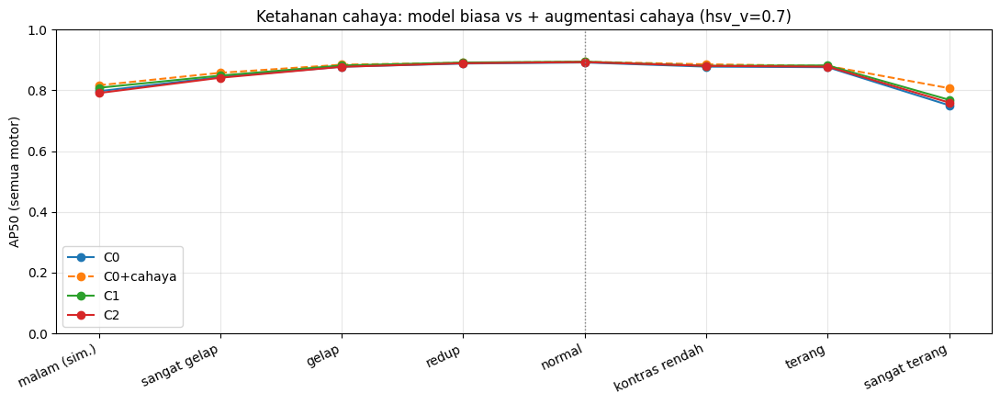

In [56]:
# ===== 10c. BANDINGKAN ketahanan cahaya: model biasa vs model + augmentasi cahaya =====
# Butuh variabel dari Bagian 10 (LIGHT, predict_arrays, es_l, imgs_l, stems_l, light, NMS_EVAL). Jalankan Bagian 10 dulu.
import matplotlib.pyplot as plt
from ultralytics import YOLO

rows2, _t0 = [], _t.time()
for w in sorted(w for w in RUNS_L.glob("*/weights/best.pt") if status_run(w.parent.parent) == "selesai"):
    run = w.parent.parent.name; model = YOLO(w)
    for cond, fn in LIGHT.items():
        raw = predict_arrays(model, {s: fn(im) for s, im in imgs_l.items()})
        m = L.summarize(es_l.match(L.postprocess(raw, NMS_EVAL)))
        rows2.append(dict(cfg=run.split("_s")[0], run=run, kondisi=cond, AP50=m["AP50"], AP50_95=m["AP50_95"]))
    print(f"  {run} selesai ({_t.time() - _t0:.0f} detik)")
light_all = pd.concat([light[["cfg", "run", "kondisi", "AP50", "AP50_95"]], pd.DataFrame(rows2)], ignore_index=True)
light_all.to_csv(RES / "LIGHT_per_run_dengan_aug_cahaya.csv", index=False)

urut = list(LIGHT)
tab2 = light_all.groupby(["kondisi", "cfg"]).AP50.mean().unstack().loc[urut]
drop2 = 100 * (tab2 - tab2.loc["normal"]) / tab2.loc["normal"]
robust2 = (tab2.drop(index="normal").mean() / tab2.loc["normal"]).rename("skor ketahanan (1 = kebal)")
print("AP50 per kondisi cahaya"); display(tab2.round(3))
print("Perubahan relatif terhadap 'normal' (%)"); display(drop2.round(1))
display(robust2.round(3).to_frame())

# selisih langsung: model + aug cahaya dikurangi model aslinya (positif = lebih baik)
for c in [c for c in tab2.columns if c.endswith("+cahaya")]:
    base_c = c.replace("+cahaya", "")
    if base_c in tab2.columns:
        print(f"\nselisih AP50 {c} - {base_c} (positif = augmentasi cahaya membantu):")
        display((tab2[c] - tab2[base_c]).round(3).to_frame("selisih"))
tab2.to_csv(RES / "LIGHT_AP50_dengan_aug_cahaya.csv"); drop2.to_csv(RES / "LIGHT_drop_dengan_aug_cahaya.csv")

fig, ax = plt.subplots(figsize=(11, 4.5)); x = np.arange(len(urut))
for c in tab2.columns:
    ax.plot(x, tab2[c], marker="o", ls="--" if c.endswith("+cahaya") else "-", label=c)
ax.set_xticks(x); ax.set_xticklabels(urut, rotation=25, ha="right"); ax.axvline(urut.index("normal"), color="gray", ls=":", lw=1)
ax.set_ylim(0, 1); ax.set_ylabel("AP50 (semua motor)"); ax.grid(alpha=.3); ax.legend()
ax.set_title(f"Ketahanan cahaya: model biasa vs + augmentasi cahaya (hsv_v={HSV_V_KUAT})")
plt.tight_layout(); plt.savefig(RES / "FIG_lighting_aug_cahaya.png", dpi=150); plt.show()

(1) AKURASI di citra uji normal (rata-rata 3 seed, confidence >= 0.25)


,AP50,AP50_95,P,R,F1
model,,,,,
SEBELUM (C0),0.892,0.681,0.790,0.866,0.826
SESUDAH (C0+cahaya),0.894,0.682,0.784,0.864,0.822
selisih (sesudah - sebelum),0.002,0.001,-0.006,-0.002,-0.005



(2) AP50 per kondisi cahaya (selisih > 0 = augmentasi cahaya membantu)


,SEBELUM,SESUDAH,selisih,turun_sebelum_%,turun_sesudah_%,hasil
kondisi,,,,,,
malam (sim.),0.797,0.817,0.020,-10.622,-8.653,membaik
sangat gelap,0.844,0.858,0.014,-5.370,-4.074,membaik
gelap,0.878,0.885,0.007,-1.552,-1.081,membaik
redup,0.889,0.891,0.003,-0.398,-0.371,sama
normal,0.892,0.894,0.002,0.000,0.000,sama
kontras rendah,0.878,0.886,0.008,-1.538,-0.938,membaik
terang,0.876,0.881,0.004,-1.747,-1.537,sama
sangat terang,0.751,0.807,0.056,-15.812,-9.740,membaik


skor ketahanan (1 = kebal): {'SEBELUM': 0.947, 'SESUDAH': 0.962}


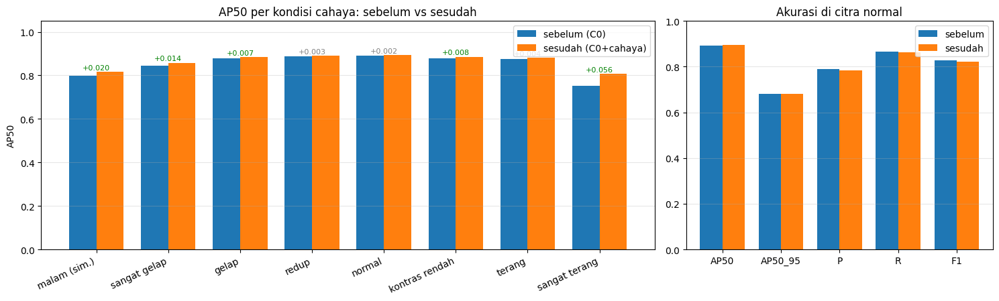

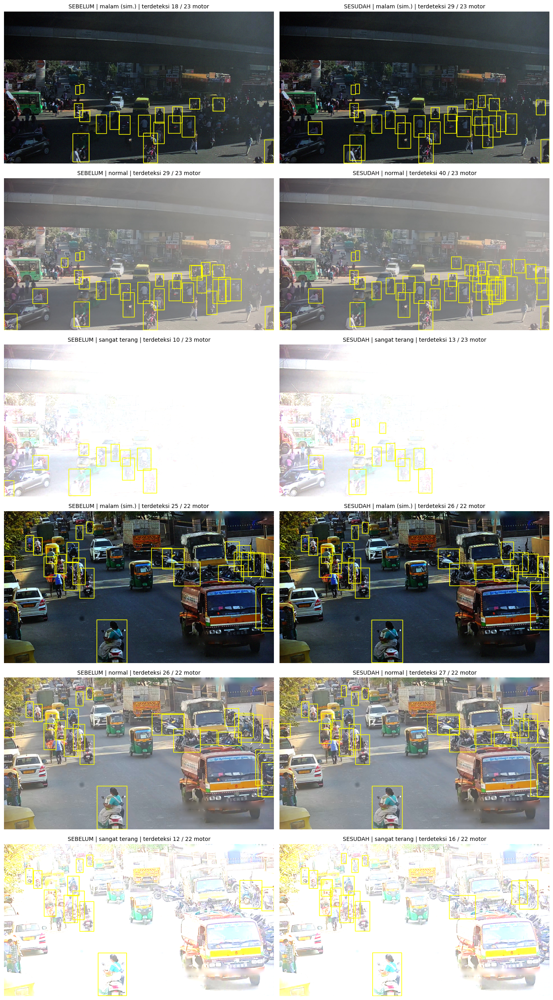

file: BANDING_akurasi_normal.csv, BANDING_per_kondisi.csv, FIG_banding_sebelum_sesudah.png, FIG_banding_contoh.png


In [57]:
# ===== 10d. PERBANDINGAN SEBELUM vs SESUDAH augmentasi cahaya (C0 vs C0+cahaya) =====
# Taruh SETELAH 10c. Butuh variabel dari Bagian 10 dan 10c (LIGHT, predict_arrays, es_l, imgs_l, stems_l, light_all, RUNS_L).
import matplotlib.pyplot as plt
from ultralytics import YOLO

SEBELUM, SESUDAH = "C0", "C0+cahaya"
KONF_DEMO = 0.25                     # ambang confidence yang SAMA untuk kedua model (adil)
KONDISI_CONTOH = ["malam (sim.)", "normal", "sangat terang"]
N_CONTOH = 2                         # jumlah citra contoh

w_seb = sorted(RUNS.glob(f"{SEBELUM}_s*/weights/best.pt"))
w_ses = sorted(w for w in RUNS_L.glob(f"{SESUDAH}_s*/weights/best.pt") if status_run(w.parent.parent) == "selesai")
assert w_seb and w_ses, "model sebelum/sesudah tidak ditemukan -> jalankan 10b dulu"

# ---------- 1) akurasi di citra normal (semua seed, ambang sama) ----------
def nilai(w, cond="normal"):
    m = YOLO(w); fn = LIGHT[cond]
    per = es_l.match(L.postprocess(predict_arrays(m, {s: fn(im) for s, im in imgs_l.items()}), NMS_EVAL))
    r = L.summarize(per, conf_thr=KONF_DEMO)
    r["F1"] = 2 * r["P"] * r["R"] / max(r["P"] + r["R"], 1e-9)
    return r
akur = []
for nama, ws in (("SEBELUM (" + SEBELUM + ")", w_seb), ("SESUDAH (" + SESUDAH + ")", w_ses)):
    for w in ws:
        akur.append(dict(model=nama, run=w.parent.parent.name, **{k: v for k, v in nilai(w).items() if k != "n_gt"}))
akur = pd.DataFrame(akur)
ringkas = akur.groupby("model")[["AP50", "AP50_95", "P", "R", "F1"]].mean()
ringkas.loc["selisih (sesudah - sebelum)"] = ringkas.iloc[1] - ringkas.iloc[0]
print(f"(1) AKURASI di citra uji normal (rata-rata {len(w_seb)} seed, confidence >= {KONF_DEMO})")
display(ringkas.round(3)); ringkas.to_csv(RES / "BANDING_akurasi_normal.csv")

# ---------- 2) AP50 per kondisi cahaya ----------
urut = list(LIGHT)
if "light_all" not in globals():                     # 10c belum dijalankan di sesi ini -> baca file / hitung ulang
    _p = RES / "LIGHT_per_run_dengan_aug_cahaya.csv"
    if _p.exists():
        light_all = pd.read_csv(_p); print("light_all dibaca dari", _p.name)
    else:
        _rows = []
        for _nama, _ws in ((SEBELUM, w_seb), (SESUDAH, w_ses)):
            for _w in _ws:
                _m = YOLO(_w)
                for _cond, _fn in LIGHT.items():
                    _r = L.summarize(es_l.match(L.postprocess(predict_arrays(_m, {s: _fn(im) for s, im in imgs_l.items()}), NMS_EVAL)))
                    _rows.append(dict(cfg=_nama, run=_w.parent.parent.name, kondisi=_cond, AP50=_r["AP50"], AP50_95=_r["AP50_95"]))
        light_all = pd.DataFrame(_rows); print("light_all dihitung ulang (10c tidak dijalankan)")
t = light_all[light_all.cfg.isin([SEBELUM, SESUDAH])].groupby(["kondisi", "cfg"]).AP50.mean().unstack().loc[urut]
banding = pd.DataFrame({"SEBELUM": t[SEBELUM], "SESUDAH": t[SESUDAH]})
banding["selisih"] = banding.SESUDAH - banding.SEBELUM
banding["turun_sebelum_%"] = 100 * (banding.SEBELUM - banding.SEBELUM["normal"]) / banding.SEBELUM["normal"]
banding["turun_sesudah_%"] = 100 * (banding.SESUDAH - banding.SESUDAH["normal"]) / banding.SESUDAH["normal"]
banding["hasil"] = np.where(banding.selisih > 0.005, "membaik", np.where(banding.selisih < -0.005, "memburuk", "sama"))
print("\n(2) AP50 per kondisi cahaya (selisih > 0 = augmentasi cahaya membantu)")
display(banding.round(3)); banding.to_csv(RES / "BANDING_per_kondisi.csv")
skor = (banding[["SEBELUM", "SESUDAH"]].drop(index="normal").astype(float).mean()
        / banding.loc["normal", ["SEBELUM", "SESUDAH"]].astype(float)).astype(float)
print("skor ketahanan (1 = kebal):", skor.round(3).to_dict())

# ---------- 3) grafik ----------
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[2, 1]))
x = np.arange(len(urut)); wbar = 0.38
axs[0].bar(x - wbar / 2, banding.SEBELUM, wbar, label=f"sebelum ({SEBELUM})")
axs[0].bar(x + wbar / 2, banding.SESUDAH, wbar, label=f"sesudah ({SESUDAH})")
for i, d in enumerate(banding.selisih):
    axs[0].text(i, max(banding.SEBELUM.iloc[i], banding.SESUDAH.iloc[i]) + 0.01, f"{d:+.3f}", ha="center", fontsize=8,
                color="green" if d > 0.005 else "red" if d < -0.005 else "gray")
axs[0].set_xticks(x); axs[0].set_xticklabels(urut, rotation=25, ha="right"); axs[0].set_ylim(0, 1.05)
axs[0].set_ylabel("AP50"); axs[0].set_title("AP50 per kondisi cahaya: sebelum vs sesudah"); axs[0].legend(); axs[0].grid(alpha=.3, axis="y")
k = ["AP50", "AP50_95", "P", "R", "F1"]; x2 = np.arange(len(k))
axs[1].bar(x2 - wbar / 2, ringkas.iloc[0][k], wbar, label="sebelum"); axs[1].bar(x2 + wbar / 2, ringkas.iloc[1][k], wbar, label="sesudah")
axs[1].set_xticks(x2); axs[1].set_xticklabels(k); axs[1].set_ylim(0, 1); axs[1].set_title("Akurasi di citra normal")
axs[1].legend(); axs[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(RES / "FIG_banding_sebelum_sesudah.png", dpi=150); plt.show()

# ---------- 4) contoh visual berdampingan ----------
m_seb, m_ses = YOLO(w_seb[0]), YOLO(w_ses[0])
def gambar(model, im_bgr):
    r = model.predict(im_bgr, imgsz=IMGSZ, conf=KONF_DEMO, iou=0.7, verbose=False)[0]
    out = im_bgr.copy()
    for (x1, y1, x2, y2) in r.boxes.xyxy.cpu().numpy().astype(int):
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 255), 2)
    return out[:, :, ::-1], len(r.boxes)
contoh = sorted(stems_l, key=lambda s: -len(es_l.gts[s][0]))[:N_CONTOH]      # citra dengan motor terbanyak
fig, axs = plt.subplots(len(contoh) * len(KONDISI_CONTOH), 2, figsize=(14, 4.2 * len(contoh) * len(KONDISI_CONTOH)), squeeze=False)
row = 0
for s in contoh:
    n_gt = len(es_l.gts[s][0])
    for cond in KONDISI_CONTOH:
        im = LIGHT[cond](imgs_l[s])
        for j, (nama, m) in enumerate((("SEBELUM", m_seb), ("SESUDAH", m_ses))):
            vis, n = gambar(m, im)
            axs[row, j].imshow(vis); axs[row, j].axis("off")
            axs[row, j].set_title(f"{nama} | {cond} | terdeteksi {n} / {n_gt} motor", fontsize=10)
        row += 1
plt.tight_layout(); plt.savefig(RES / "FIG_banding_contoh.png", dpi=110); plt.show()
print("file: BANDING_akurasi_normal.csv, BANDING_per_kondisi.csv, FIG_banding_sebelum_sesudah.png, FIG_banding_contoh.png")

citra generator baru siap (15 detik) | target gagal ditempatkan: {'erase': 40, 'gray': 40} dari 910 -> dikeluarkan dari generator itu
target dibandingkan: 870 (sama untuk paste/erase/gray; dikeluarkan: 40)
  C0_s0 selesai (117 detik)
  C0_s1 selesai (219 detik)
  C0_s2 selesai (325 detik)
  C1_s0 selesai (429 detik)
  C1_s1 selesai (533 detik)
  C1_s2 selesai (636 detik)
  C2_s0 selesai (747 detik)
  C2_s1 selesai (857 detik)
  C2_s2 selesai (965 detik)
AP50 rata-rata L1-L3 (NMS 0.7) dan selisih terhadap C0:


,C0,C1,C2,Δ C1,Δ C2,n_target
generator,,,,,,
paste,0.231,0.241,0.514,0.010,0.284,870
erase,0.218,0.549,0.496,0.331,0.279,870
gray,0.167,0.174,0.412,0.007,0.245,870


cfg                 C0     C1     C2
generator level                     
erase     L1     0.489  0.721  0.716
          L2     0.152  0.578  0.521
          L3     0.012  0.347  0.252
gray      L1     0.431  0.446  0.624
          L2     0.069  0.075  0.418
          L3     0.001  0.001  0.195
paste     L1     0.533  0.539  0.734
          L2     0.143  0.163  0.523
          L3     0.016  0.020  0.286

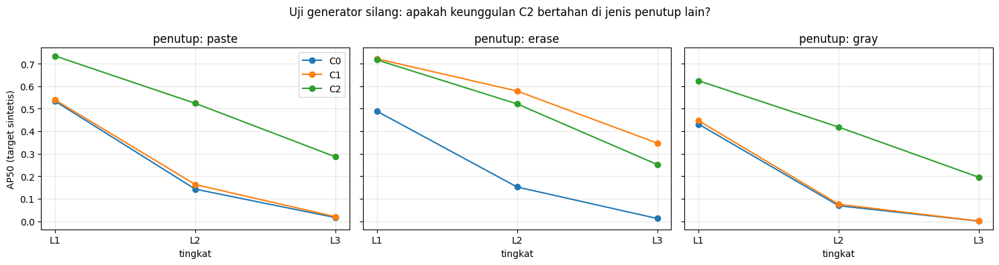

file: GENSILANG_per_run.csv, GENSILANG_ringkas.csv, GENSILANG_per_level.csv, GENSILANG_penempatan.csv, FIG_gensilang.png


In [58]:
# ===== 11. UJI GENERATOR SILANG (penjelasan RQ3) =====
# Pertanyaan: apakah keunggulan C2 di set sintetis karena model belajar OKLUSI, atau hanya mengenali pola TEMPELAN
# yang sama dengan generator uji? Target dan tingkat tutupan yang SAMA (L1-L3) ditutup dengan cara lain:
#   - "paste" : potongan kendaraan (set uji sintetis utama, sama dengan training C2)
#   - "erase" : derau acak / random pixels (sama dengan training C1)
#   - "gray"  : kotak abu-abu polos (tidak dipakai di training mana pun -> pembanding netral)
# Bila penutup GAGAL ditempatkan pada salah satu level, target itu DIKELUARKAN dari generator tersebut
# (sama seperti set paste utama), bukan dihitung sebagai citra tanpa penutup.
import random, time
import matplotlib.pyplot as plt
from ultralytics import YOLO

GEN_BARU = ["erase", "gray"]
NMS_GS   = ("std", 0.7)
_t0 = time.time()

# 1) buat citra L1-L3 untuk generator baru, target dan rentang tutupan sama dengan set uji sintetis utama
GAGAL_GS, LOG_GS = {g: set() for g in GEN_BARU}, []
for gen in GEN_BARU:
    root = DATA / f"synthetic_test_{gen}"
    for stem, k in syn_targets.items():
        box = L.load_meta(DATA / "src_test/meta", stem)["boxes"][k]["xyxy"]
        base = None
        for lv, rr in L.LEVELS.items():
            out = root / lv / "images" / f"{stem}_{lv}.jpg"
            if base is None:
                base = cv2.imread(str(DATA / "src_test/images" / f"{stem}.jpg"))
            r = random.Random(f"{DATA_SEED}-{stem}-{lv}")
            img, cov, _, rect = L.occlude_box(base.copy(), box, rr, "erase", None, r)
            LOG_GS.append(dict(generator=gen, stem=stem, level=lv, coverage=cov, berhasil=cov is not None))
            if cov is None:
                GAGAL_GS[gen].add(stem); continue
            if gen == "gray":                                  # bentuk/posisi sama dengan erase, isi abu-abu
                img = base.copy(); L.paint_occluder(img, rect, "gray")
            if not out.exists():
                out.parent.mkdir(parents=True, exist_ok=True); cv2.imwrite(str(out), img, [cv2.IMWRITE_JPEG_QUALITY, 95])
pd.DataFrame(LOG_GS).to_csv(RES / "GENSILANG_penempatan.csv", index=False)
print(f"citra generator baru siap ({time.time() - _t0:.0f} detik) | target gagal ditempatkan:",
      {g: len(v) for g, v in GAGAL_GS.items()}, "dari", len(syn_targets), "-> dikeluarkan dari generator itu")

# 2) evaluasi semua model (NMS standar 0.7) pada target YANG SAMA untuk semua generator:
#    target yang gagal di generator mana pun dikeluarkan dari SEMUA generator (paste, erase, gray) agar adil
GAGAL_SEMUA = set().union(*GAGAL_GS.values())
tg_sama = [(s, k) for s, k in syn_targets.items() if s not in GAGAL_SEMUA]
print(f"target dibandingkan: {len(tg_sama)} (sama untuk paste/erase/gray; dikeluarkan: {len(GAGAL_SEMUA)})")
rows = []
for run in runs:
    model = None
    for lv in L.LEVELS:
        m = L.summarize(MATCH[(run, NMS_GS, lv)], stems=[f"{s}_{lv}" for s, _ in tg_sama])
        rows.append(dict(run=run, cfg=cfg_of(run), generator="paste", level=lv, n_target=len(tg_sama), AP50=m["AP50"], AP50_95=m["AP50_95"]))
        for gen in GEN_BARU:
            tg_g = tg_sama
            es = L.EvalSet(lv, L.gts_target_only(DATA / "src_test/meta", tg_g, "{stem}_" + lv))
            model = model or YOLO(RUNS / run / "weights" / "best.pt")
            paths = [str(DATA / f"synthetic_test_{gen}" / lv / "images" / f"{s}_{lv}.jpg") for s, _ in tg_g]
            raw = L.predict_raw(model, paths, imgsz=IMGSZ, device=0 if torch.cuda.is_available() else "cpu")
            m = L.summarize(es.match(L.postprocess(raw, NMS_GS)))
            rows.append(dict(run=run, cfg=cfg_of(run), generator=gen, level=lv, n_target=len(tg_g), AP50=m["AP50"], AP50_95=m["AP50_95"]))
    print(f"  {run} selesai ({time.time() - _t0:.0f} detik)")
gs = pd.DataFrame(rows); gs.to_csv(RES / "GENSILANG_per_run.csv", index=False)

# 3) ringkasan: AP50 rata-rata L1-L3 per konfigurasi x generator, dan selisih terhadap C0
tab = gs.groupby(["generator", "cfg"]).AP50.mean().unstack()
delta = tab.sub(tab["C0"], axis=0).drop(columns="C0").add_prefix("Δ ").round(3)
ringkas = pd.concat([tab.round(3), delta, gs.groupby("generator").n_target.max().rename("n_target")], axis=1).loc[["paste"] + GEN_BARU]
print("AP50 rata-rata L1-L3 (NMS 0.7) dan selisih terhadap C0:"); display(ringkas)
ringkas.to_csv(RES / "GENSILANG_ringkas.csv")
per_lv = gs.groupby(["generator", "level", "cfg"]).AP50.mean().unstack().round(3)
display(per_lv); per_lv.to_csv(RES / "GENSILANG_per_level.csv")

fig, axs = plt.subplots(1, len(["paste"] + GEN_BARU), figsize=(5 * (1 + len(GEN_BARU)), 4), sharey=True)
for a_, gen in zip(axs, ["paste"] + GEN_BARU):
    d = gs[gs.generator == gen].groupby(["level", "cfg"]).AP50.mean().unstack()
    for c in d.columns:
        a_.plot(d.index, d[c], marker="o", label=c)
    a_.set_title(f"penutup: {gen}"); a_.set_xlabel("tingkat"); a_.grid(alpha=.3)
axs[0].set_ylabel("AP50 (target sintetis)"); axs[0].legend()
plt.suptitle("Uji generator silang: apakah keunggulan C2 bertahan di jenis penutup lain?")
plt.tight_layout(); plt.savefig(RES / "FIG_gensilang.png", dpi=150); plt.show()
print("file: GENSILANG_per_run.csv, GENSILANG_ringkas.csv, GENSILANG_per_level.csv, GENSILANG_penempatan.csv, FIG_gensilang.png")


## 12. Pemeriksaan tambahan untuk paper
12a cek penempatan penutup | 12b evaluasi semua motor | 12c contoh C0/C1/C2 + hard vs Soft-NMS | 12d sampel penanda ke-2 | 12e kappa antar-penanda | 12f paket akhir (checkpoint + prediksi mentah) | 12g tabel lama vs baru

In [59]:
# ===== 12a. CEK PENEMPATAN PENUTUP SINTETIS + CAKUPAN PER LEVEL (untuk paper) =====
# Cakupan = luas irisan penutup dengan kotak motor / luas kotak motor. Rentang level: L1 20-40%, L2 40-60%, L3 60-80%.
# Aturan bila gagal (50 percobaan per level): set UJI/VAL -> target dikeluarkan dari SEMUA level (pasangan tetap utuh);
# augmentasi TRAINING -> citra itu dilatih tanpa penutup pada iterasi tersebut (label tidak berubah).
import random, math
rows_pen = []
for part in ("synthetic_test", "synthetic_val"):
    lg = pd.read_csv(DATA / part / "synthetic_log.csv")
    n_skip = int((lg.level == "skip").sum()); n_ok = lg[lg.level == "L0"].shape[0]
    for lv, (lo, hi) in L.LEVELS.items():
        c = lg[lg.level == lv].coverage.astype(float)
        rows_pen.append(dict(set=part, generator="paste", level=lv, rentang=f"{lo:.2f}-{hi:.2f}", n=len(c), gagal_target=n_skip,
                             cov_min=c.min(), cov_mean=c.mean(), cov_max=c.max(), di_luar_rentang=int(((c < lo) | (c > hi)).sum())))
if (RES / "GENSILANG_penempatan.csv").exists():                       # random pixels (erase) dan gray rectangle
    gp = pd.read_csv(RES / "GENSILANG_penempatan.csv")
    for (gen, lv), d in gp.groupby(["generator", "level"]):
        lo, hi = L.LEVELS[lv]; c = d.coverage.dropna().astype(float)
        rows_pen.append(dict(set="synthetic_test", generator=gen, level=lv, rentang=f"{lo:.2f}-{hi:.2f}", n=len(c),
                             gagal_target=d[~d.berhasil].stem.nunique(), cov_min=c.min(), cov_mean=c.mean(), cov_max=c.max(),
                             di_luar_rentang=int(((c < lo) | (c > hi)).sum())))
pen = pd.DataFrame(rows_pen).round(4)
print("Penempatan penutup per set / generator / level (gagal_target = target yang dikeluarkan):"); display(pen)
pen.to_csv(RES / "CEK_penempatan_penutup.csv", index=False)

# augmentasi training (C1 = random pixels, C2 = paste): perkiraan tingkat gagal pada kotak motor train (tanpa mosaic)
rng_ = random.Random(DATA_SEED); n_try = n_fail = 0
for s in train[:800]:
    H_, W_ = cv2.imread(str(DATA / "src_train/images" / f"{s}.jpg")).shape[:2]
    for b in L.load_meta(DATA / "src_train/meta", s)["boxes"]:
        if b["cat"] != L.MOTOR_CAT or min(b["xyxy"][2] - b["xyxy"][0], b["xyxy"][3] - b["xyxy"][1]) < 8:
            continue
        asp = math.exp(rng_.uniform(math.log(0.3), math.log(3.3)))
        rect, cov = L.place_occluder(tuple(b["xyxy"]), COV_TRAIN, asp, W_, H_, rng_)
        n_try += 1; n_fail += rect is None
print(f"augmentasi training: penutup gagal ditempatkan pada {n_fail}/{n_try} kotak ({100 * n_fail / max(n_try, 1):.2f}%) "
      "-> sampel itu dilatih tanpa penutup; label tetap")
json.dump(dict(train_aug_percobaan=n_try, train_aug_gagal=n_fail), open(RES / "CEK_penempatan_training.json", "w"), indent=2)


Penempatan penutup per set / generator / level (gagal_target = target yang dikeluarkan):


,set,generator,level,rentang,n,gagal_target,cov_min,cov_mean,cov_max,di_luar_rentang
0,synthetic_test,paste,L1,0.20-0.40,910,14,0.2000,0.2827,0.3995,0
1,synthetic_test,paste,L2,0.40-0.60,910,14,0.4001,0.4841,0.5992,0
2,synthetic_test,paste,L3,0.60-0.80,910,14,0.6000,0.6776,0.8000,0
3,synthetic_val,paste,L1,0.20-0.40,355,5,0.2003,0.2800,0.3970,0
4,synthetic_val,paste,L2,0.40-0.60,355,5,0.4021,0.4799,0.5999,0
5,synthetic_val,paste,L3,0.60-0.80,355,5,0.6003,0.6749,0.8000,0
6,synthetic_test,erase,L1,0.20-0.40,910,0,0.2000,0.2821,0.3999,0
7,synthetic_test,erase,L2,0.40-0.60,906,4,0.4000,0.4749,0.5985,0
8,synthetic_test,erase,L3,0.60-0.80,874,36,0.6000,0.6701,0.7976,0
9,synthetic_test,gray,L1,0.20-0.40,910,0,0.2000,0.2821,0.3999,0


augmentasi training: penutup gagal ditempatkan pada 0/4827 kotak (0.00%) -> sampel itu dilatih tanpa penutup; label tetap


In [60]:
# ===== 12b. EVALUASI SEMUA MOTOR DALAM GAMBAR (tanpa target yang diabaikan) =====
# Evaluasi utama memakai target + 'ignore'. Di sini SEMUA motor di citra dihitung (GT penuh dari label UVH-26),
# memakai prediksi mentah yang sudah tersimpan (raw_preds), sehingga pengaruh NMS pada citra padat ikut terlihat.
# Set: L0-L3 (citra sintetis, semua motor), nyata (semua citra yang memuat target nyata), test_penuh (semua citra uji).
PREDIKSI_TEST_PENUH = True                     # False = lewati prediksi 1.150 citra uji penuh (hemat waktu GPU)
VAR_SEMUA = [("std", 0.5), ("std", 0.7), ("std", 0.8), ("soft", 0.3), ("soft", 0.5)]
_gt_all = L.gts_from_yolo(DATA / "src_test/labels", DATA / "src_test/images", list(test))
SUMBER = {lv: [lv] for lv in LEVELS_SYN}
SUMBER["nyata_semua_citra"] = [k for k in SETS if k.startswith("nyata_")]
# Citra sintetis: penutup bisa ikut menutup motor LAIN (bukan target). Motor lain yang tertutup penutup > BATAS_IGN
# dari luas kotaknya diperlakukan 'ignore' (tidak dihitung TP/FP), karena visibilitasnya diubah buatan dan tidak bertingkat.
# Target selalu dihitung. Motor yang tertutup <= BATAS_IGN tetap dihitung (GT biasa).
BATAS_IGN = 0.10
_lg = pd.read_csv(DATA / "synthetic_test" / "synthetic_log.csv", dtype={"source_image": str})
_rect = {(r.source_image, r.level): json.loads(r.rect) for r in _lg.itertuples() if isinstance(r.rect, str) and r.rect}
_tgt = {r.source_image: json.loads(r.target_xyxy) for r in _lg.itertuples() if r.level == "L0"}
_st_ign = []
def _gt_syn(s, lv):
    gt = _gt_all[s][0]; care = np.ones(len(gt), bool)
    if lv == "L0" or (s, lv) not in _rect or len(gt) == 0:
        return gt, care
    rx1, ry1, rx2, ry2 = _rect[(s, lv)]
    ix = np.clip(np.minimum(gt[:, 2], rx2) - np.maximum(gt[:, 0], rx1), 0, None)
    iy = np.clip(np.minimum(gt[:, 3], ry2) - np.maximum(gt[:, 1], ry1), 0, None)
    cov = ix * iy / np.maximum((gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1]), 1e-9)
    tj = int(np.argmax(_iou_mat(gt, np.array([_tgt[s]]))[:, 0]))
    care = cov <= BATAS_IGN; care[tj] = True
    lain = np.arange(len(gt)) != tj
    _st_ign.append(dict(level=lv, citra=s, motor_lain=int(lain.sum()), tersentuh=int((cov[lain] > 0).sum()),
                        ignore_gt10=int((cov[lain] > BATAS_IGN).sum()), tertutup_gt50=int((cov[lain] > 0.5).sum())))
    return gt, care
GTS_SEMUA = {lv: {f"{s}_{lv}": _gt_syn(s, lv) for s in syn_targets} for lv in LEVELS_SYN}
_ign = pd.DataFrame(_st_ign)
if len(_ign):
    _ign_r = _ign.groupby("level")[["motor_lain", "tersentuh", "ignore_gt10", "tertutup_gt50"]].sum()
    print("motor LAIN yang ikut tertutup penutup sintetis (tersentuh > 0%, ignore > 10%, > 50%):"); display(_ign_r)
    _ign_r.to_csv(RES / "SEMUA_MOTOR_motor_lain_tertutup.csv")
GTS_SEMUA["nyata_semua_citra"] = {s: _gt_all[s] for k in SUMBER["nyata_semua_citra"] for s in SETS[k][1]}
if PREDIKSI_TEST_PENUH:
    for run in runs:
        f = RAW / f"{run}.pkl"; have = pickle.load(open(f, "rb"))
        if set(have.get("test_penuh", {})) != set(test):
            have["test_penuh"] = L.predict_raw(YOLO(RUNS / run / "weights" / "best.pt"),
                                              [str(DATA / "src_test/images" / f"{s}.jpg") for s in test], imgsz=IMGSZ, device=0)
            pickle.dump(have, open(f, "wb")); print("prediksi test penuh:", run)
    SUMBER["test_penuh"] = ["test_penuh"]; GTS_SEMUA["test_penuh"] = _gt_all

def _job_semua(run):
    import torch; torch.set_num_threads(1)
    raw_all = pickle.load(open(RAW / f"{run}.pkl", "rb")); out = {}
    for k, srcs in SUMBER.items():
        raw = {}
        for s_ in srcs:
            raw.update(raw_all[s_])
        for v in VAR_SEMUA:
            out[(run, v, k)] = _match_set(GTS_SEMUA[k], _post(raw, v))
    return out
_t1 = time.time(); MATCH_SEMUA = {}
for d in Parallel(n_jobs=N_JOBS)(delayed(_job_semua)(r) for r in runs):
    MATCH_SEMUA.update(d)
rows = []
for (run, v, k), per in MATCH_SEMUA.items():
    m = L.summarize(per, conf_thr=CONF.get((run, v), 0.25))
    rows.append(dict(cfg=cfg_of(run), run=run, nms=f"{v[0]}:{v[1]}", set=k, n_motor=m["n_gt"], AP50=m["AP50"], AP50_95=m["AP50_95"], P=m["P"], R=m["R"]))
semua = pd.DataFrame(rows); semua.to_csv(RES / "SEMUA_MOTOR_per_run.csv", index=False)
agg = semua.groupby(["set", "cfg", "nms"]).agg(n_motor=("n_motor", "first"), AP50=("AP50", "mean"), AP50_sd=("AP50", "std"),
                                               AP50_95=("AP50_95", "mean"), P=("P", "mean"), R=("R", "mean")).round(3)
agg.to_csv(RES / "SEMUA_MOTOR_ringkas.csv")
print(f"selesai ({time.time() - _t1:.0f} detik). AP50 SEMUA MOTOR per set x konfigurasi x NMS (rata-rata seed).")
print("CATATAN: NMS utama tetap yang dipilih dari VALIDATION (lihat FR19_20_selected.json); varian lain di sini hanya pembanding.")
display(agg[["n_motor", "AP50", "AP50_sd", "P", "R"]])
piv = semua.groupby(["set", "nms", "cfg"]).AP50.mean().unstack("cfg").round(3)
print("Ringkas (AP50, kolom = konfigurasi):"); display(piv); piv.to_csv(RES / "SEMUA_MOTOR_AP50_pivot.csv")


motor LAIN yang ikut tertutup penutup sintetis (tersentuh > 0%, ignore > 10%, > 50%):


,motor_lain,tersentuh,ignore_gt10,tertutup_gt50
level,,,,
L1,4816,71,26,0
L2,4816,78,29,1
L3,4816,141,57,2


prediksi test penuh: C0_s0
prediksi test penuh: C0_s1
prediksi test penuh: C0_s2
prediksi test penuh: C1_s0
prediksi test penuh: C1_s1
prediksi test penuh: C1_s2
prediksi test penuh: C2_s0
prediksi test penuh: C2_s1
prediksi test penuh: C2_s2
selesai (284 detik). AP50 SEMUA MOTOR per set x konfigurasi x NMS (rata-rata seed).
CATATAN: NMS utama tetap yang dipilih dari VALIDATION (lihat FR19_20_selected.json); varian lain di sini hanya pembanding.


n_motor   AP50  AP50_sd      P      R
set        cfg nms                                            
L0         C0  soft:0.3     5726  0.903    0.006  0.873  0.831
               soft:0.5     5726  0.891    0.007  0.876  0.830
               std:0.5      5726  0.908    0.005  0.868  0.838
               std:0.7      5726  0.906    0.005  0.881  0.820
               std:0.8      5726  0.898    0.005  0.872  0.817
...                          ...    ...      ...    ...    ...
test_penuh C2  soft:0.3     6729  0.899    0.004  0.867  0.824
               soft:0.5     6729  0.890    0.005  0.870  0.820
               std:0.5      6729  0.905    0.003  0.865  0.827
               std:0.7      6729  0.902    0.003  0.875  0.813
               std:0.8      6729  0.893    0.003  0.867  0.806

[90 rows x 5 columns]

Ringkas (AP50, kolom = konfigurasi):


cfg                            C0     C1     C2
set               nms                          
L0                soft:0.3  0.903  0.906  0.904
                  soft:0.5  0.891  0.896  0.895
                  std:0.5   0.908  0.911  0.910
                  std:0.7   0.906  0.909  0.907
                  std:0.8   0.898  0.903  0.899
L1                soft:0.3  0.870  0.875  0.897
                  soft:0.5  0.857  0.863  0.887
                  std:0.5   0.878  0.882  0.902
                  std:0.7   0.874  0.878  0.899
                  std:0.8   0.864  0.869  0.889
L2                soft:0.3  0.812  0.820  0.882
                  soft:0.5  0.798  0.807  0.870
                  std:0.5   0.822  0.828  0.887
                  std:0.7   0.818  0.824  0.883
                  std:0.8   0.807  0.814  0.871
L3                soft:0.3  0.767  0.772  0.861
                  soft:0.5  0.756  0.762  0.848
                  std:0.5   0.776  0.782  0.869
                  std:0.7   0.772  0.777  0.862
                  std:0.8   0.763  0.768  0.847
nyata_semua_citra soft:0.3  0.901  0.904  0.902
                  soft:0.5  0.889  0.895  0.892
                  std:0.5   0.905  0.910  0.908
                  std:0.7   0.904  0.908  0.905
                  std:0.8   0.894  0.900  0.895
test_penuh        soft:0.3  0.896  0.900  0.899
                  soft:0.5  0.886  0.891  0.890
                  std:0.5   0.901  0.905  0.905
                  std:0.7   0.900  0.903  0.902
                  std:0.8   0.892  0.896  0.893

In [61]:
# ===================== KODE LAMA (tidak dipakai) =====================
# # ===== 12c. CONTOH PERBANDINGAN C0 / C1 / C2 PADA GAMBAR YANG SAMA (+ hard NMS vs Soft-NMS) =====
# CNT = RES / "contoh_C0_C1_C2"; CNT.mkdir(exist_ok=True)
# def _hit(run, v, k, key):
#     sc, tp, n = MATCH[(run, v, k)][key]; thr = CONF.get((run, v), 0.25)
#     return int(((sc >= thr) & (tp[:, 0] == 1)).sum()), n
# def _gambar(run, v, k, key):
#     raw = pickle.load(open(RAW / f"{run}.pkl", "rb"))[k][key]; b, s = _post({key: raw}, v)[key]
#     im = cv2.imread(str(SETS[k][1][key])); gt, care = SETS[k][0].gts[key]
#     for g, c in zip(gt, care):
#         cv2.rectangle(im, tuple(map(int, g[:2])), tuple(map(int, g[2:])), (0, 200, 0) if c else (150, 150, 150), 2)
#     for bb, ss in zip(b, s):
#         if ss >= CONF.get((run, v), 0.25):
#             cv2.rectangle(im, tuple(map(int, bb[:2])), tuple(map(int, bb[2:])), (0, 0, 255), 2)
#     gtc = gt[np.asarray(care, bool)]
#     x1, y1 = gtc[:, :2].min(0); x2, y2 = gtc[:, 2:].max(0); p = int(0.8 * max(x2 - x1, y2 - y1)) + 20
#     return im[max(0, int(y1) - p):int(y2) + p, max(0, int(x1) - p):int(x2) + p][:, :, ::-1]
# S0 = SEEDS[0]; V7 = ("std", 0.7)
# for k in ["L2", "L3", "nyata_ringan", "nyata_berat"]:
#     if k not in SETS: continue
#     kat = {"semua_berhasil": [], "hanya_C2_berhasil": [], "C0_berhasil_C2_gagal": [], "semua_gagal": []}
#     for key in sorted(SETS[k][0].gts):
#         r = {c: _hit(f"{c}_s{S0}", V7, k, key) for c in ("C0", "C1", "C2")}
#         ok = {c: h == n and n > 0 for c, (h, n) in r.items()}; no = {c: h == 0 for c, (h, n) in r.items()}
#         if all(ok.values()): kat["semua_berhasil"].append(key)
#         elif ok["C2"] and no["C0"]: kat["hanya_C2_berhasil"].append(key)
#         elif ok["C0"] and no["C2"]: kat["C0_berhasil_C2_gagal"].append(key)
#         elif all(no.values()): kat["semua_gagal"].append(key)
#     print(k, {a: len(b) for a, b in kat.items()})
#     for nama, keys in kat.items():
#         keys = random.Random(0).sample(keys, min(3, len(keys)))
#         if not keys: continue
#         fig, axs = plt.subplots(len(keys), 3, figsize=(12, 4 * len(keys)), squeeze=False)
#         for i, key in enumerate(keys):
#             for j, c in enumerate(("C0", "C1", "C2")):
#                 h, n = _hit(f"{c}_s{S0}", V7, k, key)
#                 axs[i, j].imshow(_gambar(f"{c}_s{S0}", V7, k, key)); axs[i, j].axis("off")
#                 axs[i, j].set_title(f"{c} | {key} | target terdeteksi {h}/{n}", fontsize=9)
#         plt.suptitle(f"{k}: {nama.replace('_', ' ')}"); plt.tight_layout()
#         plt.savefig(CNT / f"{k}_{nama}.png", dpi=110); plt.close()
# VS = BEST["C0"]["soft"]
# for k in ["nyata_ringan", "nyata_berat"]:
#     if k not in SETS: continue
#     beda = [(key, _hit(f"C0_s{S0}", V7, k, key)[0] - _hit(f"C0_s{S0}", VS, k, key)[0]) for key in sorted(SETS[k][0].gts)]
#     pilih = [x for x in beda if x[1] > 0][:2] + [x for x in beda if x[1] < 0][:2]
#     if not pilih: continue
#     fig, axs = plt.subplots(len(pilih), 2, figsize=(9, 4 * len(pilih)), squeeze=False)
#     for i, (key, d) in enumerate(pilih):
#         for j, (nm, v) in enumerate((("hard NMS 0.7", V7), (f"Soft-NMS s={VS[1]}", VS))):
#             h, n = _hit(f"C0_s{S0}", v, k, key)
#             axs[i, j].imshow(_gambar(f"C0_s{S0}", v, k, key)); axs[i, j].axis("off")
#             axs[i, j].set_title(f"{nm} | {key} | {h}/{n}", fontsize=9)
#     plt.suptitle(f"{k}: hard NMS vs Soft-NMS (C0)"); plt.tight_layout(); plt.savefig(CNT / f"{k}_hard_vs_soft.png", dpi=110); plt.close()
# print("contoh disimpan di", CNT, ":", sorted(p.name for p in CNT.glob("*.png")))
# =================== AKHIR KODE LAMA ===================


# ===================== KODE BARU (dipakai) =====================
# ===== 12c. CONTOH PERBANDINGAN C0 / C1 / C2 PADA GAMBAR YANG SAMA (+ hard NMS vs Soft-NMS) =====
# Hijau = target, abu-abu = motor diabaikan, merah = prediksi (confidence >= ambang dari val). Seed 0, NMS 0.7.
# Perubahan: "hanya_C2_berhasil" sekarang berarti C0 DAN C1 gagal; kasus C1 ikut berhasil masuk "C1_C2_berhasil_C0_gagal".
CNT = RES / "contoh_C0_C1_C2"; CNT.mkdir(exist_ok=True)
def _hit(run, v, k, key):
    sc, tp, n = MATCH[(run, v, k)][key]; thr = CONF.get((run, v), 0.25)
    return int(((sc >= thr) & (tp[:, 0] == 1)).sum()), n
def _gambar(run, v, k, key):
    raw = pickle.load(open(RAW / f"{run}.pkl", "rb"))[k][key]; b, s = _post({key: raw}, v)[key]
    im = cv2.imread(str(SETS[k][1][key])); gt, care = SETS[k][0].gts[key]
    for g, c in zip(gt, care):
        cv2.rectangle(im, tuple(map(int, g[:2])), tuple(map(int, g[2:])), (0, 200, 0) if c else (150, 150, 150), 2)
    for bb, ss in zip(b, s):
        if ss >= CONF.get((run, v), 0.25):
            cv2.rectangle(im, tuple(map(int, bb[:2])), tuple(map(int, bb[2:])), (0, 0, 255), 2)
    gtc = gt[np.asarray(care, bool)]                                 # potong di sekitar target agar jelas
    x1, y1 = gtc[:, :2].min(0); x2, y2 = gtc[:, 2:].max(0); p = int(0.8 * max(x2 - x1, y2 - y1)) + 20
    return im[max(0, int(y1) - p):int(y2) + p, max(0, int(x1) - p):int(x2) + p][:, :, ::-1]
S0 = SEEDS[0]; V7 = ("std", 0.7)
for k in ["L2", "L3", "nyata_ringan", "nyata_berat"]:
    if k not in SETS: continue
    kat = {"semua_berhasil": [], "hanya_C2_berhasil": [], "C1_C2_berhasil_C0_gagal": [], "C0_berhasil_C2_gagal": [], "semua_gagal": []}
    for key in sorted(SETS[k][0].gts):
        r = {c: _hit(f"{c}_s{S0}", V7, k, key) for c in ("C0", "C1", "C2")}
        ok = {c: h == n and n > 0 for c, (h, n) in r.items()}; no = {c: h == 0 for c, (h, n) in r.items()}
        if all(ok.values()): kat["semua_berhasil"].append(key)
        elif ok["C2"] and no["C0"] and no["C1"]: kat["hanya_C2_berhasil"].append(key)      # C0 dan C1 sama-sama gagal
        elif ok["C2"] and no["C0"]: kat["C1_C2_berhasil_C0_gagal"].append(key)             # C1 juga (sebagian) berhasil
        elif ok["C0"] and no["C2"]: kat["C0_berhasil_C2_gagal"].append(key)
        elif all(no.values()): kat["semua_gagal"].append(key)
    print(k, {a: len(b) for a, b in kat.items()})
    for nama, keys in kat.items():
        keys = random.Random(0).sample(keys, min(3, len(keys)))
        if not keys: continue
        fig, axs = plt.subplots(len(keys), 3, figsize=(12, 4 * len(keys)), squeeze=False)
        for i, key in enumerate(keys):
            for j, c in enumerate(("C0", "C1", "C2")):
                h, n = _hit(f"{c}_s{S0}", V7, k, key)
                axs[i, j].imshow(_gambar(f"{c}_s{S0}", V7, k, key)); axs[i, j].axis("off")
                axs[i, j].set_title(f"{c} | {key} | target terdeteksi {h}/{n}", fontsize=9)
        plt.suptitle(f"{k}: {nama.replace('_', ' ')}"); plt.tight_layout()
        plt.savefig(CNT / f"{k}_{nama}.png", dpi=110); plt.close()
# hard NMS (0.7) vs Soft-NMS (sigma terpilih) pada C0: citra di mana hasilnya berbeda
VS = BEST["C0"]["soft"]
for k in ["nyata_ringan", "nyata_berat"]:
    if k not in SETS: continue
    beda = [(key, _hit(f"C0_s{S0}", V7, k, key)[0] - _hit(f"C0_s{S0}", VS, k, key)[0]) for key in sorted(SETS[k][0].gts)]
    pilih = [x for x in beda if x[1] > 0][:2] + [x for x in beda if x[1] < 0][:2]
    if not pilih: continue
    fig, axs = plt.subplots(len(pilih), 2, figsize=(9, 4 * len(pilih)), squeeze=False)
    for i, (key, d) in enumerate(pilih):
        for j, (nm, v) in enumerate((("hard NMS 0.7", V7), (f"Soft-NMS s={VS[1]}", VS))):
            h, n = _hit(f"C0_s{S0}", v, k, key)
            axs[i, j].imshow(_gambar(f"C0_s{S0}", v, k, key)); axs[i, j].axis("off")
            axs[i, j].set_title(f"{nm} | {key} | {h}/{n}", fontsize=9)
    plt.suptitle(f"{k}: hard NMS vs Soft-NMS (C0)"); plt.tight_layout(); plt.savefig(CNT / f"{k}_hard_vs_soft.png", dpi=110); plt.close()
print("contoh disimpan di", CNT, ":", sorted(p.name for p in CNT.glob("*.png")))

L2 {'semua_berhasil': 132, 'hanya_C2_berhasil': 348, 'C1_C2_berhasil_C0_gagal': 59, 'C0_berhasil_C2_gagal': 9, 'semua_gagal': 313}
L3 {'semua_berhasil': 18, 'hanya_C2_berhasil': 308, 'C1_C2_berhasil_C0_gagal': 22, 'C0_berhasil_C2_gagal': 5, 'semua_gagal': 550}
nyata_ringan {'semua_berhasil': 205, 'hanya_C2_berhasil': 2, 'C1_C2_berhasil_C0_gagal': 12, 'C0_berhasil_C2_gagal': 20, 'semua_gagal': 37}
nyata_berat {'semua_berhasil': 85, 'hanya_C2_berhasil': 1, 'C1_C2_berhasil_C0_gagal': 6, 'C0_berhasil_C2_gagal': 11, 'semua_gagal': 27}
contoh disimpan di /kaggle/working/results_v6_e60_ulang/contoh_C0_C1_C2 : ['L2_C0_berhasil_C2_gagal.png', 'L2_C1_C2_berhasil_C0_gagal.png', 'L2_hanya_C2_berhasil.png', 'L2_semua_berhasil.png', 'L2_semua_gagal.png', 'L3_C0_berhasil_C2_gagal.png', 'L3_C1_C2_berhasil_C0_gagal.png', 'L3_hanya_C2_berhasil.png', 'L3_semua_berhasil.png', 'L3_semua_gagal.png', 'nyata_berat_C0_berhasil_C2_gagal.png', 'nyata_berat_C1_C2_berhasil_C0_gagal.png', 'nyata_berat_hanya_C2_berh

In [62]:
# ===== 12d. SAMPEL UNTUK PENANDA KE-2 (agreement antar-penanda, BUTA terhadap label kukuh) =====
# Membuat ZIP berisi potongan gambar + CSV kosong. Penanda baru mengisi kolom 'level' (bersih/ringan/berat/buang)
# TANPA melihat label kukuh. Urutan diacak dan nama file tidak memuat label.
N_PER_LEVEL = 50
_fin = pd.read_csv(RES / "real_labels_final.csv", dtype={"file": str, "stem": str})
samp = pd.concat([g.sample(min(N_PER_LEVEL, len(g)), random_state=DATA_SEED) for _, g in _fin.groupby("level")])
samp = samp.sample(frac=1, random_state=DATA_SEED + 1).reset_index(drop=True)
DIR2 = W / "penanda2"; (DIR2 / "gambar").mkdir(parents=True, exist_ok=True)
for i, r in samp.iterrows():
    meta = L.load_meta(DATA / "src_test/meta", r.stem); im = cv2.imread(str(DATA / "src_test/images" / f"{r.stem}.jpg"))
    x1, y1, x2, y2 = map(int, meta["boxes"][int(r.target_idx)]["xyxy"]); p = int(0.8 * max(x2 - x1, y2 - y1))
    cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 255), 2)
    cv2.imwrite(str(DIR2 / "gambar" / f"{i + 1:03d}_{r.file}"), im[max(0, y1 - p):y2 + p, max(0, x1 - p):x2 + p])
pd.DataFrame(dict(no=range(1, len(samp) + 1), gambar=[f"{i + 1:03d}_{f}" for i, f in enumerate(samp.file)], file=samp.file,
                  level="", penutup="", kotak_ok="ya", catatan="")).to_csv(DIR2 / "label_penanda2_KOSONG.csv", index=False)
json.dump(ATURAN, open(DIR2 / "aturan_penandaan.json", "w"), indent=2, ensure_ascii=False)
shutil.make_archive(str(W / "penanda2_sampel"), "zip", DIR2)
print(f"{len(samp)} motor ({N_PER_LEVEL}/tingkat) -> {W / 'penanda2_sampel.zip'} | isi kolom 'level' lalu unggah sebagai dataset")


150 motor (50/tingkat) -> /kaggle/working/penanda2_sampel.zip | isi kolom 'level' lalu unggah sebagai dataset


In [63]:
# ===== 12e. KAPPA ANTAR-PENANDA (kukuh vs penanda ke-2) + daftar beda untuk diskusi =====
# Jalankan setelah CSV penanda ke-2 diisi dan diunggah. Label FINAL tetap kukuh kecuali diubah lewat diskusi
# (isi RESOLVE di sel 4.5, lalu jalankan ulang 4.5-4.7 dan bagian 6-8 tanpa training).
LABEL_PENANDA2 = str(W / "label_penanda2.csv") if DI_COLAB else "/kaggle/input/datasets/alirahmanbayanaka/manual-penanda2/label_penanda2 (1).csv"          # mis. "/kaggle/input/label-penanda2/label_penanda2.csv"
if LABEL_PENANDA2 and Path(LABEL_PENANDA2).exists():
    p2 = pd.read_csv(LABEL_PENANDA2, dtype={"file": str}); p2["level"] = p2.level.astype(str).str.strip().str.lower()
    kk = pd.read_csv(DATA / "real_test" / "real_tags_raw_kukuh.csv", dtype={"file": str})
    m2 = p2[["file", "level"]].merge(kk[["file", "level"]], on="file", suffixes=("_p2", "_kukuh"))
    a, b = list(m2.level_kukuh), list(m2.level_p2)
    info = dict(pasangan="kukuh vs penanda2", n_motor=len(m2), kesepakatan=float(np.mean(np.array(a) == np.array(b))),
                kappa=L.cohen_kappa(a, b), jenis="antar")
    try:
        from sklearn.metrics import cohen_kappa_score
        urut = {"bersih": 0, "ringan": 1, "berat": 2}; mm = m2[m2.level_kukuh.isin(urut) & m2.level_p2.isin(urut)]
        info["kappa_berbobot_kuadratik"] = float(cohen_kappa_score(mm.level_kukuh.map(urut), mm.level_p2.map(urut), weights="quadratic"))
    except Exception:
        pass
    json.dump(info, open(RES / "FR13_kappa_antar.json", "w"), indent=2); print(info)
    display(pd.crosstab(m2.level_kukuh, m2.level_p2, margins=True))
    m2[m2.level_kukuh != m2.level_p2].to_csv(RES / "beda_label_untuk_diskusi.csv", index=False)
    print("beda label:", int((m2.level_kukuh != m2.level_p2).sum()), "-> RES/beda_label_untuk_diskusi.csv")
else:
    print("LABEL_PENANDA2 belum diisi: kerjakan sampel dari 12d dulu")


{'pasangan': 'kukuh vs penanda2', 'n_motor': 150, 'kesepakatan': 0.5066666666666667, 'kappa': 0.28317726832418477, 'jenis': 'antar', 'kappa_berbobot_kuadratik': 0.4929063640048642}


level_p2,berat,bersih,buang,ringan,All
level_kukuh,,,,,
berat,20,3,2,24,49
bersih,0,18,4,28,50
ringan,5,3,5,38,51
All,25,24,11,90,150


beda label: 74 -> RES/beda_label_untuk_diskusi.csv


In [64]:
# ===== 12f. PAKET AKHIR: checkpoint model + prediksi mentah (sebelum NMS kustom) + cara evaluasi =====
import zipfile
PAKET = W / "paket_akhir_v6.zip"
readme = f"""PAKET AKHIR v6 — Occlusion-Aware Motorcycle Detection
isi:
  weights/<run>/best.pt        checkpoint YOLO11s tiap run (C0/C1/C2 x seed {SEEDS}) + C0+cahaya
  raw_preds/<run>.pkl          prediksi mentah SEBELUM NMS kustom (conf>=0.001, NMS bawaan iou=0.99, max_det=1000)
                               dict[set][nama_citra] = (boxes_xyxy, scores)
  matching.pkl                 hasil pencocokan per citra (MATCH, CONF, BEST, VARIANTS)
  occlusion_lib.py             pustaka evaluasi (postprocess, EvalSet, summarize, bootstrap)
  label/real_tags.csv          label final oklusi nyata (sha256 di real_labels_manifest.json)
cara evaluasi ulang:
  A) lengkap: buka keterima-mbc-v6.ipynb, Add Input output versi ini, isi PREV_OUTPUT, Run All
     -> training dilewati (run sudah 'selesai'), semua evaluasi dihitung ulang dari bobot ini.
  B) cepat (tanpa GPU), mis. AP50 C2 seed 0 di L2 dengan NMS 0.7:
     import pickle, occlusion_lib as L
     M = pickle.load(open('matching.pkl','rb'))['MATCH']
     print(L.summarize(M[('C2_s0', ('std', 0.7), 'L2')])['AP50'])
  C) NMS lain dari prediksi mentah:
     raw = pickle.load(open('raw_preds/C2_s0.pkl','rb'))['L2']
     pred = L.postprocess(raw, ('soft', 0.3))   # lalu cocokkan dengan GT memakai L.EvalSet(...).match(pred)
"""
with zipfile.ZipFile(PAKET, "w", zipfile.ZIP_DEFLATED) as z:
    for w in sorted(RUNS.glob("**/weights/best.pt")):
        z.write(w, Path("weights") / w.parent.parent.name / "best.pt")
    for p in RAW.glob("*.pkl"):
        z.write(p, Path("raw_preds") / p.name)
    for src, dst in ((RES / "ekspor" / "matching.pkl", "matching.pkl"), (Path(LIB_PATH), "occlusion_lib.py"),
                     (REAL_TAGS_CSV, "label/real_tags.csv"), (RES / "real_labels_manifest.json", "label/real_labels_manifest.json")):
        if Path(src).exists(): z.write(src, dst)
    z.writestr("README.txt", readme)
print(f"paket: {PAKET} ({PAKET.stat().st_size / 1e6:.0f} MB) | isi: weights {len(list(RUNS.glob('**/weights/best.pt')))} run + raw_preds + README")


paket: /kaggle/working/paket_akhir_v6.zip (439 MB) | isi: weights 12 run + raw_preds + README


In [65]:
# ===== 12g. BANDINGKAN TABEL LAMA vs BARU (angka mana yang berubah setelah run ulang) =====
# Tabel lama = salinan results dari PREV_OUTPUT yang diambil sel konfigurasi SEBELUM ditimpa (results_v6_LAMA).
FILE_BANDING = ["FR21_22_main_table.csv", "TABLE_AP50_mean_sd.csv", "FR22_23_ablation_bootstrap.csv", "FR24_transfer.csv",
                "FR19_20_val_sweep.csv", "ACCURACY_test_clean.csv", "LIGHT_AP50.csv", "LIGHT_AP50_dengan_aug_cahaya.csv",
                "BANDING_per_kondisi.csv", "GENSILANG_ringkas.csv", "GENSILANG_per_level.csv", "FR14_real_counts.csv"]
TOL = 5e-4
if globals().get("RES_LAMA") and Path(RES_LAMA).exists():
    ubah, status = [], []
    for f in FILE_BANDING:
        a_, b_ = Path(RES_LAMA) / f, RES / f
        if not (a_.exists() and b_.exists()):
            status.append(dict(file=f, status="tidak ada di " + ("lama" if not a_.exists() else "baru"))); continue
        A, B = pd.read_csv(a_), pd.read_csv(b_)
        if len(A) != len(B):
            status.append(dict(file=f, status=f"jumlah baris berubah (lama {len(A)}, baru {len(B)})")); continue
        kol_baru = [c for c in B.columns if c not in A.columns]
        A, B = A[[c for c in A.columns if c in B.columns]], B[[c for c in A.columns if c in B.columns]]
        _isnum = lambda x: pd.api.types.is_numeric_dtype(x) and not pd.api.types.is_bool_dtype(x)
        num = [c for c in A.columns if _isnum(A[c]) and _isnum(B[c])]
        key = [c for c in A.columns if c not in num]
        n0 = len(ubah)
        for c in num:
            d = (B[c] - A[c]).abs()
            for i in np.where(d > TOL)[0]:
                ubah.append(dict(file=f, baris=" | ".join(str(A.loc[i, k]) for k in key) or str(i), kolom=c,
                                 lama=round(float(A.loc[i, c]), 4), baru=round(float(B.loc[i, c]), 4), selisih=round(float(B.loc[i, c] - A.loc[i, c]), 4)))
        for c in key:
            if not (A[c].astype(str) == B[c].astype(str)).all():
                ubah.append(dict(file=f, baris="(teks)", kolom=c, lama="berbeda", baru="berbeda", selisih=None))
        status.append(dict(file=f, status=("SAMA" if len(ubah) == n0 else f"BERUBAH ({len(ubah) - n0} sel)") +
                           (f" | kolom baru: {kol_baru}" if kol_baru else "")))
    st = pd.DataFrame(status); ub = pd.DataFrame(ubah)
    display(st); st.to_csv(RES / "BANDING_LAMA_BARU_status.csv", index=False)
    if len(ub):
        display(ub.head(80)); ub.to_csv(RES / "BANDING_LAMA_BARU_detail.csv", index=False)
    print(f"sel berubah (> {TOL}): {len(ub)} -> BANDING_LAMA_BARU_*.csv")
else:
    print("tidak ada tabel lama (PREV_OUTPUT tidak diisi) -> perbandingan dilewati")


tidak ada tabel lama (PREV_OUTPUT tidak diisi) -> perbandingan dilewati


In [66]:
# ===== JAWABAN RQ1 sampai RQ3 (dibaca dari tabel hasil) =====
import json
def _baca(nama, **kw):
    p = RES / nama
    return pd.read_csv(p, **kw) if p.exists() else None
_main, _abl = _baca("FR21_22_main_table.csv"), _baca("FR22_23_ablation_bootstrap.csv")
_gen = _baca("GENSILANG_ringkas.csv", index_col=0)
SINT, NYATA = ["L1", "L2", "L3"], ["nyata_bersih", "nyata_ringan", "nyata_berat"]

def _ci(perb, s):
    r = _abl[(_abl.perbandingan == perb) & (_abl.set == s) & (_abl.metric == "AP50")]
    return None if r.empty else tuple(r.iloc[0][["delta", "ci_lo", "ci_hi"]])
def _fmt(x):
    if x is None:
        return "n/a"
    return f"{x[0]:+.3f} [{x[1]:+.3f}, {x[2]:+.3f}]" + (" *" if x[1] > 0 or x[2] < 0 else "")

out = [f"# Ringkasan RQ ({BUDGET}, {EPOCHS} epoch, seed {SEEDS})", ""]
b = _main[(_main.cfg == "C0") & (_main.nms == "std_default")].set_index("set")
out += ["## RQ1. Penurunan baseline (C0, NMS 0.7)",
        "AP50: " + " | ".join(f"{s} {b.loc[s, 'AP50']:.3f} ± {b.loc[s, 'AP50_sd']:.3f}" for s in ["L0"] + SINT if s in b.index),
        f"Penurunan L0 ke L3: {b.loc['L0', 'AP50'] - b.loc['L3', 'AP50']:.3f} AP50.", ""]
out += ["## RQ2. Selisih terhadap C0 (AP50, 95% CI bootstrap; * = CI tidak memuat nol)"]
for perb in ["Augmentasi saja (C1)", "Augmentasi saja (C2)", "NMS saja (Soft-NMS)"]:
    out.append(f"- {perb}: " + "; ".join(f"{s} {_fmt(_ci(perb, s))}" for s in SINT + NYATA))
out.append("")
c2s, c2n = [_ci("Augmentasi saja (C2)", s) for s in SINT], [_ci("Augmentasi saja (C2)", s) for s in NYATA]
naik_sint = all(x is not None and x[1] > 0 for x in c2s)
naik_nyata = [s for s, x in zip(NYATA, c2n) if x is not None and x[1] > 0]
turun_nyata = [s for s, x in zip(NYATA, c2n) if x is not None and x[2] < 0]
if naik_sint and not naik_nyata and not turun_nyata:
    kes = "C2 meningkatkan AP50 pada semua level sintetis, tetapi selisih pada oklusi nyata tidak terdeteksi (CI memuat nol). Transfer belum terbukti pada data ini."
elif naik_sint and naik_nyata:
    kes = f"C2 meningkatkan AP50 pada oklusi sintetis dan juga pada {naik_nyata}. Periksa besar efeknya terhadap variasi antar seed."
elif naik_sint:
    kes = f"C2 meningkatkan AP50 pada oklusi sintetis, tetapi menurunkan AP50 pada {turun_nyata}."
else:
    kes = "C2 tidak meningkatkan AP50 secara jelas pada semua level sintetis."
out += ["## RQ3. Transfer sintetis ke nyata", kes]
for f, nama in (("FR13_kappa.json", "intra-penanda"), ("FR13_kappa_antar.json", "antar-penanda")):
    p = RES / f
    if p.exists():
        k = json.load(open(p))
        out.append(f"- Keandalan label, kappa {nama}: {k['kappa']:.3f} (n = {k['n_motor']}, kesepakatan {k['kesepakatan']:.1%})")
if _gen is not None and "Δ C2" in _gen:
    out.append("- Generator silang, selisih C2 terhadap C0 (AP50 rata-rata L1 sampai L3): "
               + ", ".join(f"{g} {d:+.3f}" for g, d in _gen["Δ C2"].items()))
out += ["", "Catatan: CI bootstrap mencerminkan variasi gambar uji; variasi pelatihan terlihat dari simpangan baku antar seed di tabel utama."]
(RES / "RINGKASAN_RQ.md").write_text("\n".join(out), encoding="utf-8")
print("\n".join(out))

# Ringkasan RQ (PENUH, 60 epoch, seed [0, 1, 2])

## RQ1. Penurunan baseline (C0, NMS 0.7)
AP50: L0 0.852 ± 0.010 | L1 0.531 ± 0.018 | L2 0.144 ± 0.016 | L3 0.017 ± 0.006
Penurunan L0 ke L3: 0.835 AP50.

## RQ2. Selisih terhadap C0 (AP50, 95% CI bootstrap; * = CI tidak memuat nol)
- Augmentasi saja (C1): L1 +0.005 [-0.006, +0.017]; L2 +0.019 [+0.009, +0.030] *; L3 +0.004 [+0.001, +0.007] *; nyata_bersih +0.005 [-0.004, +0.014]; nyata_ringan +0.013 [+0.003, +0.026] *; nyata_berat +0.009 [-0.015, +0.029]
- Augmentasi saja (C2): L1 +0.203 [+0.185, +0.222] *; L2 +0.380 [+0.355, +0.409] *; L3 +0.269 [+0.248, +0.296] *; nyata_bersih +0.009 [-0.001, +0.017]; nyata_ringan -0.004 [-0.018, +0.010]; nyata_berat +0.003 [-0.025, +0.024]
- NMS saja (Soft-NMS): L1 +0.010 [+0.007, +0.012] *; L2 +0.005 [+0.004, +0.007] *; L3 +0.000 [+0.000, +0.001] *; nyata_bersih -0.009 [-0.014, -0.005] *; nyata_ringan -0.028 [-0.036, -0.020] *; nyata_berat -0.013 [-0.026, -0.002] *

## RQ3. Transfer sintetis ke nyata

In [67]:
# ARSIP AKHIR: jalankan PALING TERAKHIR (setelah bagian 10). ZIP dibuat ulang agar hasil cahaya ikut masuk.
import hashlib
if not SMOKE:
    _lock = json.load(open(RES / "real_labels_manifest.json"))
    assert hashlib.sha256(open(REAL_TAGS_CSV, "rb").read()).hexdigest() == _lock["sha256_real_tags"], \
        "real_tags.csv berubah setelah dikunci -> jalankan ulang 4.7 dan bagian 6-8"
shutil.make_archive(str(W / f"results_bab4{TAG}"), "zip", RES)
print("arsip akhir:", W / f"results_bab4{TAG}.zip", round((W / f"results_bab4{TAG}.zip").stat().st_size / 1e6, 1), "MB | label:", real_src)
try:
    from ipywidgets import Widget
    Widget.close_all()
except Exception:
    pass
print("Selesai. Klik Save Version agar notebook tersimpan utuh.")

arsip akhir: /kaggle/working/results_bab4_v6_e60_ulang.zip 145.3 MB | label: manual
Selesai. Klik Save Version agar notebook tersimpan utuh.


In [68]:
# ===== LAPORAN HASIL -> laporan_hasil.html + laporan_bab4.zip =====
# Jalankan PALING AKHIR (setelah ARSIP AKHIR). Semua bagian bersifat opsional: hasil yang belum ada dilewati.
import base64, datetime, html, zipfile
G = globals()
def _csv(name):
    p = RES / name
    return pd.read_csv(p) if p.exists() else None
def _json(name):
    p = RES / name
    return json.load(open(p)) if p.exists() else None
def _tbl(df, idx=False, n=60):
    return df.head(n).to_html(index=idx, border=0, classes="t", float_format=lambda x: f"{x:.3f}") if df is not None and len(df) else "<p class='na'>belum ada</p>"
def _img(name, w=900):
    p = RES / name
    if not p.exists():
        return ""
    b64 = base64.b64encode(p.read_bytes()).decode()
    return f"<figure><img src='data:image/png;base64,{b64}' style='max-width:{w}px;width:100%'><figcaption>{html.escape(name)}</figcaption></figure>"
def _kv(d):
    if not d:
        return "<p class='na'>belum ada</p>"
    rows = "".join(f"<tr><th>{html.escape(str(k))}</th><td>{html.escape(str(v))}</td></tr>" for k, v in d.items())
    return f"<table class='t kv'>{rows}</table>"

bag, catatan = [], []
# 1. identitas run
ver = _json("versions.json") or {}
ident = dict(tanggal=datetime.datetime.now().strftime("%Y-%m-%d %H:%M"), mode="UJI ASAP" if G.get("SMOKE") else G.get("BUDGET", "?"),
             model=G.get("MODEL"), epoch=G.get("EPOCHS"), seed=G.get("SEEDS"), n_train_src=G.get("N_TRAIN_SRC"),
             n_test_src=G.get("N_TEST_SRC"), dataset=f"{G.get('REPO_ID')} ({G.get('REVISION')}, anotasi {G.get('ANN_VARIANT')})",
             label_set_nyata=G.get("real_src", "?"), pengurangan_instance=(f"{G.get('CARA_KURANGI')} (> {G.get('MAX_MOTOR_PER_IMG')} motor/citra, test {'ikut' if G.get('KURANGI_DI_TEST') else 'utuh'})" if G.get("KURANGI_INSTANCE") else "tidak"), run=", ".join(G.get("runs", [])), **{f"versi_{k}": v for k, v in ver.items()})
bag.append(("1. Identitas run", _kv(ident)))

# 2. data
sp = {}
for n in ("train", "val", "test", "test_removed_neardup"):
    p = DATA / "splits" / f"{n}.txt"
    if p.exists():
        sp[f"citra {n}"] = len([x for x in p.read_text().split() if x])
for part in ("synthetic_test", "synthetic_val"):
    p = DATA / part / "synthetic_log.csv"
    if p.exists():
        lg = pd.read_csv(p); ok = lg[lg.level != "skip"]
        sp[f"target {part}"] = ok.source_image.nunique(); sp[f"gagal {part}"] = int((lg.level == "skip").sum())
cov = None
if (DATA / "synthetic_test" / "synthetic_log.csv").exists():
    lg = pd.read_csv(DATA / "synthetic_test" / "synthetic_log.csv")
    cov = lg[lg.level.isin(["L1", "L2", "L3"])].groupby("level").coverage.describe()[["count", "mean", "min", "max"]].reset_index()
    cov["count"] = cov["count"].astype(int)
bag.append(("2. Data", _kv(sp) + "<h4>Motor per citra (setelah pengurangan)</h4>" + _tbl(_csv("FR01b_instance_per_citra.csv")) +
            "<h4>Pengurangan instance</h4>" + _kv(_json("FR01b_pengurangan_instance.json")) +
            "<h4>Tutupan sintetis (set uji)</h4>" + _tbl(cov)))

# 3. label set nyata
man = _json("real_labels_manifest.json"); kap = _json("FR13_kappa.json")
lab = _kv(man) + "<h4>Agreement</h4>" + (_kv(kap) if kap else "<p class='na'>tidak dihitung (satu penanda)</p>")
if G.get("real_src") != "manual":
    catatan.append("Label set nyata BUKAN manual: hasil RQ3 tidak boleh dipakai untuk paper.")
if not kap:
    catatan.append("Agreement antar-penanda tidak dihitung: tulis sebagai keterbatasan (label dari satu penanda).")
bag.append(("3. Label set nyata", lab + "<h4>Jumlah per tingkat</h4>" + _tbl(_csv("FR14_real_counts.csv"))))

# 4. pemilihan NMS
sel_ = _json("FR19_20_selected.json")
bag.append(("4. NMS terpilih (dari val)", _kv({c: "; ".join(f"{k}={v[0]} {v[1]}" for k, v in d.items()) for c, d in (sel_ or {}).items()})))

# 5. RQ1 + tabel utama
main = _csv("FR21_22_main_table.csv")
rq1 = None
if main is not None:
    rq1 = main[main.nms == "std_default"].pivot_table(index="cfg", columns="set", values="AP50").round(3)
    order = [c for c in ["L0", "L1", "L2", "L3", "nyata_bersih", "nyata_ringan", "nyata_berat"] if c in rq1.columns]
    rq1 = rq1[order]
bag.append(("5. RQ1: AP50 per tingkat oklusi (NMS 0.7)", _tbl(rq1, idx=True) + _img("FIG_rq1_ap_vs_level.png") +
            "<h4>Tabel lengkap AP50 (mean ± sd antar seed)</h4>" + _tbl(_csv("TABLE_AP50_mean_sd.csv"))))

# 6. RQ2 ablasi + bootstrap
abl_ = _csv("FR22_23_ablation_bootstrap.csv"); piv = None
if abl_ is not None:
    a = abl_[abl_.metric == "AP50"].copy()
    a["cell"] = [f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]{' *' if s else ''}" for d, lo, hi, s in zip(a.delta, a.ci_lo, a.ci_hi, a.signifikan)]
    piv = a.pivot_table(index="perbandingan", columns="set", values="cell", aggfunc="first")
bag.append(("6. RQ2: ablasi ΔAP50 vs C0+NMS 0.7 (CI 95%, * = bermakna)", _tbl(piv, idx=True) +
            "<h4>Konfigurasi bootstrap</h4>" + _kv(_json("FR22_bootstrap_config.json"))))

# 7. RQ3 transfer
bag.append(("7. RQ3: transfer sintetis → nyata", _tbl(_csv("FR24_transfer.csv")) + _img("FIG_rq3_transfer.png", 600)))

# 7b. uji generator silang
bag.append(("7b. Uji generator silang (penjelasan RQ3)", _tbl(_csv("GENSILANG_ringkas.csv")) + _img("FIG_gensilang.png")))

# 7c-7d. pemeriksaan tambahan
bag.append(("7c. Evaluasi semua motor dalam gambar (tanpa ignore)", _tbl(_csv("SEMUA_MOTOR_AP50_pivot.csv"))))
bag.append(("7d. Penempatan penutup sintetis", _tbl(_csv("CEK_penempatan_penutup.csv")) + _kv(_json("CEK_penempatan_training.json"))))

# 8. cahaya
bag.append(("8. Akurasi + ketahanan cahaya",
            "<h4>Akurasi citra normal</h4>" + _tbl(_csv("ACCURACY_test_clean.csv")) +
            "<h4>AP50 per kondisi</h4>" + _tbl(_csv("LIGHT_AP50.csv")) +
            "<h4>Perubahan relatif (%)</h4>" + _tbl(_csv("LIGHT_drop_pct.csv")) + _img("FIG_lighting.png") +
            "<h4>Sebelum vs sesudah augmentasi cahaya</h4>" + _tbl(_csv("BANDING_akurasi_normal.csv")) +
            _tbl(_csv("BANDING_per_kondisi.csv")) + _img("FIG_banding_sebelum_sesudah.png")))

# 9. daftar file
files = sorted(str(p.relative_to(RES)) for p in RES.rglob("*") if p.is_file())
bag.append(("9. Isi arsip", f"<p>{len(files)} file hasil + laporan ini.</p><details><summary>lihat daftar</summary><pre>" +
            html.escape("\n".join(files)) + "</pre></details>"))

css = """body{font-family:system-ui,Segoe UI,Arial,sans-serif;max-width:1100px;margin:24px auto;padding:0 16px;color:#1f2328}
h1{font-size:24px}h2{font-size:19px;margin-top:32px;border-bottom:1px solid #d0d7de;padding-bottom:4px}h4{margin:16px 0 6px}
table.t{border-collapse:collapse;font-size:13px;margin:6px 0}table.t th,table.t td{border:1px solid #d0d7de;padding:4px 8px;text-align:right}
table.kv th{text-align:left;background:#f6f8fa}table.t thead th{background:#f6f8fa}.na{color:#888;font-style:italic}
.warn{background:#fff4e5;border:1px solid #f0b37e;padding:8px 12px;border-radius:6px}figure{margin:12px 0}figcaption{font-size:12px;color:#666}"""
judul = "Occlusion-Aware Training and Post-Processing for Motorcycle Detection — Laporan Hasil (v6)"
warn = "".join(f"<p class='warn'>⚠ {html.escape(c)}</p>" for c in catatan)
body = "".join(f"<h2>{html.escape(t)}</h2>{c}" for t, c in bag)
LAPORAN = RES / "laporan_hasil.html"
LAPORAN.write_text(f"<!doctype html><html lang='id'><head><meta charset='utf-8'><title>Laporan Hasil</title><style>{css}</style></head>"
                   f"<body><h1>{judul}</h1>{warn}{body}</body></html>", encoding="utf-8")

ZIP = W / f"laporan_bab4{TAG}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for p in RES.rglob("*"):
        if p.is_file():
            z.write(p, Path(f"laporan_bab4{TAG}") / p.relative_to(RES))
print(f"laporan: {LAPORAN}\nZIP    : {ZIP} ({ZIP.stat().st_size / 1e6:.1f} MB, {len(files) + 1} file)")
for c in catatan:
    print("CATATAN:", c)
print(f"Unduh {ZIP.name} (Kaggle: panel Output; Colab: Google Drive/occlusion_v6), lalu buka laporan_bab4{TAG}/laporan_hasil.html di browser.")


laporan: /kaggle/working/results_v6_e60_ulang/laporan_hasil.html
ZIP    : /kaggle/working/laporan_bab4_v6_e60_ulang.zip (145.9 MB, 320 file)
CATATAN: Agreement antar-penanda tidak dihitung: tulis sebagai keterbatasan (label dari satu penanda).
Unduh laporan_bab4_v6_e60_ulang.zip (Kaggle: panel Output; Colab: Google Drive/occlusion_v6), lalu buka laporan_bab4_v6_e60_ulang/laporan_hasil.html di browser.


## 9. Demo: unggah gambar lalu deteksi motor (sesi interaktif)

In [69]:
import os
# Demo upload hanya di sesi interaktif; saat commit (Save & Run All) dilewati agar commit tidak tertahan
DEMO_COLAB = False   # Colab: ubah ke True bila ingin demo Gradio (tidak ikut "Run all")
DEMO_INTERAKTIF = os.environ.get("KAGGLE_KERNEL_RUN_TYPE", "Interactive") != "Batch" and (DEMO_COLAB or not globals().get("DI_COLAB", False))
if DEMO_INTERAKTIF:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
from pathlib import Path
import cv2, numpy as np
from ultralytics import YOLO

# Pilih bobot model. Default: run terbaik dari sweep val (bagian 6) bila tersedia, kalau tidak C2_s0.
# Untuk sesi baru, isi path manual, mis. Path("/kaggle/input/occ-motor-sesi1/runs/C2_s0/weights/best.pt")
WEIGHTS = None
if WEIGHTS is None:
    RUNS_DIR = RUNS if "RUNS" in globals() else Path("/kaggle/working/runs")   # ikut folder dari sel konfigurasi
    try:
        WEIGHTS = RUNS_DIR / sel.sort_values("sel_score", ascending=False).iloc[0].run / "weights" / "best.pt"
    except NameError:
        WEIGHTS = RUNS_DIR / "C2_s0" / "weights" / "best.pt"
assert Path(WEIGHTS).exists(), f"bobot tidak ditemukan: {WEIGHTS}"
motor_model = YOLO(str(WEIGHTS))
# hanya kelas motor yang dihitung (aman juga bila tidak sengaja memuat model banyak kelas, mis. COCO)
MOTOR_IDS = [k for k, v in motor_model.names.items() if str(v).lower().replace("-", "_") in ("motorcycle", "two_wheeler", "motorbike")]
assert MOTOR_IDS, f"model ini tidak punya kelas motor: {motor_model.names}"
print("model:", WEIGHTS, "| kelas motor:", {k: motor_model.names[k] for k in MOTOR_IDS})

def deteksi_motor(img_rgb, conf=0.25, iou=0.7, imgsz=640):
    """img_rgb: array RGB (H, W, 3). Return (gambar RGB berkotak, jumlah motor, daftar deteksi)."""
    if img_rgb is None:
        return None, 0, []
    img_rgb = np.ascontiguousarray(img_rgb[..., :3])           # buang kanal alfa (PNG transparan)
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)              # Ultralytics membaca array numpy sebagai BGR
    r = motor_model.predict(bgr, conf=conf, iou=iou, imgsz=imgsz, classes=MOTOR_IDS, verbose=False)[0]
    out = img_rgb.copy()
    t = max(2, round(max(out.shape[:2]) / 600))                 # tebal garis mengikuti ukuran gambar
    dets = []
    for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy()):
        cv2.rectangle(out, (x1, y1), (x2, y2), (255, 200, 0), t)
        cv2.putText(out, f"motor {c:.2f}", (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.4 * t, (255, 200, 0), max(1, t // 2))
        dets.append(dict(x1=int(x1), y1=int(y1), x2=int(x2), y2=int(y2), confidence=round(float(c), 3)))
    cv2.putText(out, f"Jumlah motor: {len(dets)}", (10, 20 + 15 * t), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * t, (255, 0, 0), t)
    return out, len(dets), dets

model: /kaggle/working/runs_v6_e60_ulang/C2_s2/weights/best.pt | kelas motor: {0: 'two_wheeler'}


In [70]:
if DEMO_INTERAKTIF:
    import gradio as gr

    def _app(img, conf, iou):
        out, n, dets = deteksi_motor(img, conf, iou)
        if out is None:
            return None, "Unggah gambar dulu."
        teks = f"Terdeteksi {n} motor (confidence >= {conf:.2f})."
        if n:
            teks += "\n" + "\n".join(f"{i+1}. confidence {d['confidence']:.2f}  kotak ({d['x1']},{d['y1']})-({d['x2']},{d['y2']})"
                                     for i, d in enumerate(dets))
        return out, teks

    demo = gr.Interface(
        fn=_app,
        inputs=[gr.Image(type="numpy", label="Unggah foto lalu lintas"),
                gr.Slider(0.05, 0.95, value=0.25, step=0.05, label="Ambang confidence (makin kecil = makin banyak kotak)"),
                gr.Slider(0.3, 0.9, value=0.7, step=0.05, label="IoU NMS (0.7 = bawaan, terbaik di uji kami)")],
        outputs=[gr.Image(type="numpy", label="Hasil deteksi"), gr.Textbox(label="Ringkasan", lines=8)],
        title="Deteksi Motor (YOLO11, UVH-26)",
        description="Unggah gambar, lalu model mendeteksi motor beserta pengendaranya.",
        flagging_mode="never",
    )
    demo.launch(share=True, debug=False)   # muncul tautan *.gradio.live; bisa dibuka juga dari HP
else:
    print("mode commit: demo Gradio dilewati (jalankan di sesi interaktif)")

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: [link gradio sementara dihapus]

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [71]:
# ===== KUMPULKAN SEMUA HASIL JADI 1 ZIP + LINK UNDUH =====
import zipfile
from pathlib import Path
from IPython.display import FileLink, display

SEMUA = W / f"SEMUA_HASIL{TAG}.zip"
with zipfile.ZipFile(SEMUA, "w", zipfile.ZIP_STORED) as z:
    for p in sorted(W.glob("*.zip")):
        if p != SEMUA:
            z.write(p, p.name)
            print("masuk:", p.name, f"({p.stat().st_size / 1e6:.0f} MB)")
    for p in sorted(RUNS.glob("*/results.csv")) + sorted(RUNS.glob("*/args.yaml")):
        z.write(p, f"log_training/{p.parent.name}/{p.name}")
    for p in list(RES.glob("laporan*.html")) + list(RES.glob("*.md")) + list(RES.glob("*.tex")):
        z.write(p, f"laporan/{p.name}")
print(f"\nSELESAI: {SEMUA.name} ({SEMUA.stat().st_size / 1e6:.0f} MB)")
display(FileLink(str(SEMUA.relative_to(W))))

masuk: laporan_bab4_v6_e60_ulang.zip (146 MB)
masuk: paket_akhir_v6.zip (439 MB)
masuk: penanda2_sampel.zip (5 MB)
masuk: raw_preds.zip (155 MB)
masuk: results_bab4.zip (131 MB)
masuk: results_bab4_v6_e60_ulang.zip (145 MB)

SELESAI: SEMUA_HASIL_v6_e60_ulang.zip (1023 MB)


/kaggle/working/SEMUA_HASIL_v6_e60_ulang.zip

In [72]:
# ===== PAKET UNTUK TIM: panel C0|C1|C2 (hard NMS 0.7) + paket evaluasi yang bisa ditelusuri =====
# Jalankan di SESI YANG SAMA setelah Run all selesai (butuh MATCH, SETS, RAW, _gambar dari sel-sel sebelumnya).
import random, pickle, hashlib, json, zipfile, time, platform
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
import ultralytics

TIM = W / f"paket_tim{TAG}"; TIM.mkdir(exist_ok=True)
S0 = SEEDS[0]; V7 = ("std", 0.7)
RUN_UTAMA = [f"{c}_s{s}" for c in ("C0", "C1", "C2") for s in SEEDS]

# ---------- A. PANEL C0 | C1 | C2, semua hard NMS 0.7, seed 0, gambar sama ----------
PANEL = TIM / "panel_C0_C1_C2_hardNMS07"; PANEL.mkdir(exist_ok=True)
def _hit(run, v, k, key):
    sc, tp, n = MATCH[(run, v, k)][key]; thr = CONF.get((run, v), 0.25)
    return int(((sc >= thr) & (tp[:, 0] == 1)).sum()), n
def _kategori(k, key):
    r = {c: _hit(f"{c}_s{S0}", V7, k, key) for c in ("C0", "C1", "C2")}
    ok = {c: h == n and n > 0 for c, (h, n) in r.items()}; no = {c: h == 0 for c, (h, n) in r.items()}
    if all(ok.values()): return "semua_berhasil"
    if ok["C2"] and no["C0"] and no["C1"]: return "hanya_C2_berhasil"
    if ok["C2"] and no["C0"]: return "C1_C2_berhasil_C0_gagal"
    if ok["C0"] and no["C2"]: return "C0_berhasil_C2_gagal"
    if all(no.values()): return "semua_gagal"
    return "campuran"
URUT_KAT = ["semua_berhasil", "hanya_C2_berhasil", "C1_C2_berhasil_C0_gagal", "C0_berhasil_C2_gagal", "semua_gagal"]
daftar, jumlah = [], []
for k in [x for x in ["L0", "L1", "L2", "L3", "nyata_bersih", "nyata_ringan", "nyata_berat"] if x in SETS]:
    kat = {}
    for key in sorted(SETS[k][0].gts):
        kat.setdefault(_kategori(k, key), []).append(key)
    jumlah.append(dict(set=k, **{c: len(kat.get(c, [])) for c in URUT_KAT + ["campuran"]}))
    pilih = [(c, random.Random(0).choice(kat[c])) for c in URUT_KAT if kat.get(c)]     # 1 contoh acak per kategori
    fig, axs = plt.subplots(len(pilih), 3, figsize=(11, 3.7 * len(pilih)), squeeze=False)
    for i, (c, key) in enumerate(pilih):
        for j, cfg in enumerate(("C0", "C1", "C2")):
            h, n = _hit(f"{cfg}_s{S0}", V7, k, key)
            axs[i, j].imshow(_gambar(f"{cfg}_s{S0}", V7, k, key)); axs[i, j].axis("off")
            axs[i, j].set_title(f"{cfg} | hard NMS 0.7 | {h}/{n} terdeteksi\n[{c.replace('_', ' ')}] {key}", fontsize=8)
            daftar.append(dict(set=k, kategori=c, gambar=key, cfg=cfg, seed=S0, nms="std:0.7", terdeteksi=h, target=n))
    plt.suptitle(f"{k}: C0 | C1 | C2, seed {S0}, hard NMS 0.7 (gambar sama per baris)\n"
                 "hijau = target, abu-abu = diabaikan, merah = prediksi (conf >= ambang validasi)", fontsize=10)
    plt.tight_layout(); plt.savefig(PANEL / f"panel_{k}.png", dpi=130); plt.close()
    print("panel:", k, {c: len(kat.get(c, [])) for c in URUT_KAT})
pd.DataFrame(daftar).to_csv(PANEL / "panel_daftar_contoh.csv", index=False)
pd.DataFrame(jumlah).to_csv(PANEL / "panel_jumlah_per_kategori.csv", index=False)

# ---------- B. Prediksi mentah generator silang (erase / gray) agar angka bagian 11 bisa ditelusuri ----------
SIMPAN_PRED_GENSILANG = True        # ~15 menit GPU; False = lewati
GSR = TIM / "gensilang_raw_preds"; GSR.mkdir(exist_ok=True)
if SIMPAN_PRED_GENSILANG and "tg_sama" in globals():
    _t = time.time()
    for run in RUN_UTAMA:
        f = GSR / f"{run}.pkl"
        if f.exists(): continue
        model = YOLO(RUNS / run / "weights" / "best.pt"); out = {}
        for gen in ["erase", "gray"]:
            for lv in ["L1", "L2", "L3"]:
                paths = [str(DATA / f"synthetic_test_{gen}" / lv / "images" / f"{s}_{lv}.jpg") for s, _ in tg_sama]
                out[(gen, lv)] = L.predict_raw(model, paths, imgsz=IMGSZ, device=0)
        pickle.dump(out, open(f, "wb")); print(f"  gensilang raw {run} ({time.time() - _t:.0f} detik)")
    json.dump(dict(target_sama=[[s, int(k)] for s, k in tg_sama], dikeluarkan=sorted(GAGAL_SEMUA)),
              open(GSR / "target_gensilang.json", "w"))
if "MATCH_SEMUA" in globals():
    pickle.dump(dict(MATCH_SEMUA=MATCH_SEMUA, VAR_SEMUA=VAR_SEMUA, BATAS_IGN=BATAS_IGN), open(TIM / "matching_semua_motor.pkl", "wb"))

# ---------- C. README ----------
README = f"""PAKET UNTUK TIM — run {EXP_TAG} (satu run yang sama untuk semua isi paket)
dibuat: {time.strftime('%Y-%m-%d %H:%M')} | torch {torch.__version__} | ultralytics {ultralytics.__version__} | python {platform.python_version()}
model : YOLO11s, {EPOCHS} epoch, seed {SEEDS}, deterministic=True, imgsz {IMGSZ}

ISI
  weights/<C0|C1|C2>_s<seed>/best.pt   checkpoint 9 run utama (tanpa training ulang)
  raw_preds/<run>.pkl                  prediksi mentah SEBELUM NMS kustom (conf>=0.001, NMS bawaan iou=0.99, max_det=1000)
                                       kunci: val, valsyn_L0-L3, L0-L3, nyata_bersih/ringan/berat, test_penuh
  matching.pkl                         MATCH/CONF/BEST: pencocokan per citra untuk tabel utama, ablasi, bootstrap
  matching_semua_motor.pkl             MATCH_SEMUA: evaluasi semua motor (12b), termasuk test_penuh
  gensilang_raw_preds/<run>.pkl        prediksi mentah uji generator silang, kunci (generator, level)
  gensilang_raw_preds/target_gensilang.json   870 target yang sama untuk paste/erase/gray
  hasil_csv/                           semua tabel hasil (utama, ablasi, RQ3, generator silang, semua motor, cahaya, dll.)
  label/                               label final oklusi nyata + manifest sha256
  log_training/<run>/results.csv       log per epoch (60 baris) + args.yaml
  panel_C0_C1_C2_hardNMS07/            panel C0|C1|C2, seed {S0}, hard NMS 0.7, contoh berhasil & gagal
  occlusion_lib.py                     pustaka evaluasi
  MANIFEST_sha256.csv                  sidik jari semua file (bukti satu run)

CARA EVALUASI SINGKAT (tanpa GPU)
  import pickle, occlusion_lib as L
  M = pickle.load(open('matching.pkl','rb'))['MATCH']
  L.summarize(M[('C2_s0', ('std', 0.7), 'L2')])['AP50']          # satu sel tabel utama (seed 0)
  # NMS lain dari prediksi mentah:
  raw  = pickle.load(open('raw_preds/C2_s0.pkl','rb'))['L2']
  pred = L.postprocess(raw, ('soft', 0.3))                       # lalu L.EvalSet(...).match(pred)
  # semua motor / test penuh:
  MS = pickle.load(open('matching_semua_motor.pkl','rb'))['MATCH_SEMUA']
  L.summarize(MS[('C0_s0', ('std', 0.7), 'test_penuh')])['AP50']
Tabel paper = rata-rata 3 seed dari angka per-run di atas (lihat hasil_csv/).
"""
(TIM / "README.txt").write_text(README)

# ---------- D. ZIP + manifest sha256 ----------
isi = []
for r in RUN_UTAMA:
    isi += [(RUNS / r / "weights" / "best.pt", f"weights/{r}/best.pt"),
            (RUNS / r / "results.csv", f"log_training/{r}/results.csv"), (RUNS / r / "args.yaml", f"log_training/{r}/args.yaml")]
    isi.append((RAW / f"{r}.pkl", f"raw_preds/{r}.pkl"))
isi += [(RES / "ekspor" / "matching.pkl", "matching.pkl"), (Path(LIB_PATH), "occlusion_lib.py"),
        (REAL_TAGS_CSV, "label/real_tags.csv"), (RES / "real_labels_manifest.json", "label/real_labels_manifest.json"),
        (RES / "real_labels_final.csv", "label/real_labels_final.csv")]
isi += [(p, f"hasil_csv/{p.name}") for p in sorted(RES.glob("*.csv")) + sorted(RES.glob("*.json"))]
isi += [(p, p.relative_to(TIM).as_posix()) for p in sorted(TIM.rglob("*")) if p.is_file()]
def _sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
ZT = W / f"PAKET_TIM{TAG}.zip"; man = []
with zipfile.ZipFile(ZT, "w", zipfile.ZIP_DEFLATED) as z:
    for src, dst in isi:
        if Path(src).exists():
            z.write(src, dst); man.append(dict(file=dst, bytes=Path(src).stat().st_size, sha256=_sha(src)))
    z.writestr("MANIFEST_sha256.csv", pd.DataFrame(man).to_csv(index=False))
print(f"\nSELESAI: {ZT} ({ZT.stat().st_size / 1e6:.0f} MB, {len(man)} file)")
print("cek: best.pt =", sum(m['file'].endswith('best.pt') for m in man), "| raw_preds =", sum(m['file'].startswith('raw_preds/') for m in man),
      "| panel =", sum(m['file'].endswith('.png') for m in man))

# ---------- E. Link unduh ----------
from IPython.display import FileLink, display
display(FileLink(str(ZT.relative_to(W))))

panel: L0 {'semua_berhasil': 736, 'hanya_C2_berhasil': 9, 'C1_C2_berhasil_C0_gagal': 20, 'C0_berhasil_C2_gagal': 30, 'semua_gagal': 84}
panel: L1 {'semua_berhasil': 439, 'hanya_C2_berhasil': 150, 'C1_C2_berhasil_C0_gagal': 72, 'C0_berhasil_C2_gagal': 21, 'semua_gagal': 178}
panel: L2 {'semua_berhasil': 132, 'hanya_C2_berhasil': 348, 'C1_C2_berhasil_C0_gagal': 59, 'C0_berhasil_C2_gagal': 9, 'semua_gagal': 313}
panel: L3 {'semua_berhasil': 18, 'hanya_C2_berhasil': 308, 'C1_C2_berhasil_C0_gagal': 22, 'C0_berhasil_C2_gagal': 5, 'semua_gagal': 550}
panel: nyata_bersih {'semua_berhasil': 269, 'hanya_C2_berhasil': 4, 'C1_C2_berhasil_C0_gagal': 7, 'C0_berhasil_C2_gagal': 5, 'semua_gagal': 21}
panel: nyata_ringan {'semua_berhasil': 205, 'hanya_C2_berhasil': 2, 'C1_C2_berhasil_C0_gagal': 12, 'C0_berhasil_C2_gagal': 20, 'semua_gagal': 37}
panel: nyata_berat {'semua_berhasil': 85, 'hanya_C2_berhasil': 1, 'C1_C2_berhasil_C0_gagal': 6, 'C0_berhasil_C2_gagal': 11, 'semua_gagal': 27}
  gensilang raw C

/kaggle/working/PAKET_TIM_v6_e60_ulang.zip